In [1]:
# Basics
import pandas as pd
import seaborn as sns
import datetime
import numpy as np
import geopandas as gpd
import math
import os
import warnings
warnings.filterwarnings('ignore')

# Plotting
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as mpatches
import matplotlib.patheffects as mpe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Stats & modeling
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
import statsmodels.api as sm
from sklearn.model_selection import ShuffleSplit
from sklearn.linear_model import LinearRegression
from scipy.stats import ttest_rel
import statsmodels.api as sm
from sklearn.inspection import permutation_importance
from pygam import LinearGAM, s, l
from scipy import stats

## Loading data

In [2]:
CLIMATE_DIR = '/Users/charlottecockburn/Documents/Columbia/AC_project/remote_deela/Climate_Drivers/monthly_output/'
DATA_DIR = '/Users/charlottecockburn/Documents/Columbia/AC_project/Data/'
DATA_DIR_LC = '/Users/charlottecockburn/Documents/Columbia/AC_project/data/'
OUT_DIR = '/Users/charlottecockburn/Documents/Columbia/AC_project/Figures/'
OUT_DIR_FILES = '/Users/charlottecockburn/Documents/Columbia/AC_project/Tables/'


df_cdd = pd.read_csv(CLIMATE_DIR + 'monthly_cdd.csv')
df_cdd['Date'] = pd.to_datetime(df_cdd['Date'], format='%m/%d/%y')

df_eld = pd.read_csv(CLIMATE_DIR + 'monthly_eld.csv')
df_eld['Date'] = pd.to_datetime(df_eld['Date'], format='%m/%d/%y')

df_elec = pd.read_csv(DATA_DIR + 'emberdata.csv')
df_elec['Date'] = pd.to_datetime(df_elec['Date'], format='%m/%d/%y')

df_ac = pd.read_csv(DATA_DIR + 'AC_saturation.csv')
df_income = pd.read_csv(DATA_DIR_LC + 'worldbank_income.csv')
gdf = gpd.read_file(DATA_DIR + 'Shapefiles/natural_earth_shapefiles/ne_110m_admin_0_countries.shp')

def _wb_long(path, value_name):
    df = pd.read_csv(path, skiprows=4)
    year_cols = [c for c in df.columns if c.isdigit()]
    return (df[['Country Name'] + year_cols]
            .melt(id_vars='Country Name', value_vars=year_cols,
                  var_name='Year', value_name=value_name)
            .assign(Year=lambda x: x['Year'].astype(int)))

df_gdp = _wb_long(DATA_DIR_LC + 'worldbank_gdp.csv', 'GDP')
df_pop = _wb_long(DATA_DIR_LC + 'worldbank_population.csv', 'Population')
print("Data loaded")

Data loaded


In [3]:
# Merging everything together!
mdf = (df_elec
       .merge(df_cdd, on=['Country', 'Date'])
       .merge(df_eld, on=['Country', 'Date'])
       .merge(df_ac[['Country', 'AC', 'Hemisphere']], on='Country', how='left')
       .merge(df_income[['Country', 'Income group']], on='Country', how='left'))

mdf['Year'] = mdf['Date'].dt.year
mdf = (mdf
       .merge(df_gdp, left_on=['Country', 'Year'], right_on=['Country Name', 'Year'], how='left')
       .drop(columns=['Country Name'])
       .merge(df_pop, left_on=['Country', 'Year'], right_on=['Country Name', 'Year'], how='left')
       .drop(columns=['Country Name']))

mdf = mdf.sort_values(['Country', 'Date'])
parts = []
for _, grp in mdf.groupby('Country', sort=False):
    g = grp.copy()
    g.loc[g['Date'].dt.month != 1, ['GDP', 'Population']] = np.nan
    g[['GDP', 'Population']] = g[['GDP', 'Population']].interpolate(method='linear')
    parts.append(g)
mdf = pd.concat(parts).sort_values(['Country', 'Date'])
mdf = mdf[mdf['Country'] != 'Taiwan']
mdf['Month'] = mdf['Date'].dt.month

# Define baseline warm season, and include months where the average monthly temp across the record is > 19 oC
north_warm = {6, 7, 8, 9}
south_warm = {12, 1, 2, 3}
dynamic_warm = {}
for country, grp in mdf.groupby('Country'):
    canonical = north_warm if grp['Hemisphere'].iloc[0] == 'North' else south_warm
    month_avg = grp.groupby('Month')['avg_temp'].mean()
    dynamic_warm[country] = set(month_avg.index[(month_avg > 19) | month_avg.index.isin(canonical)])

wdf = mdf[mdf.apply(lambda r: r['Month'] in dynamic_warm[r['Country']], axis=1)].copy()
wdf['cdd_sum_sq'] = wdf['cdd_sum_sum'] ** 2
print(f"wdf: {len(wdf):,} rows, {wdf['Country'].nunique()} countries")


wdf: 4,650 rows, 85 countries


In [4]:
# Set figure style
mpl.rcParams.update({
    # FONTS:
    "font.family": "Helvetica", "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"], "font.size": 14,
    # FIGURE
    "figure.figsize": (10, 5), "figure.dpi": 300, "savefig.dpi": 300,
    # AXES
    "axes.titlesize": 18, "axes.labelsize": 16, "axes.titleweight": "bold", "axes.linewidth": 1.2,
    # TICKS
    "xtick.labelsize": 13, "ytick.labelsize": 13, "xtick.major.width": 1.1, "ytick.major.width": 1.1, "xtick.major.size": 5, "ytick.major.size": 5,
    # LINES
    "lines.linewidth": 2, "lines.markersize": 6,
    # LEGEND
    "legend.fontsize": 11, "legend.frameon": False,
    # GRIDS
    "grid.alpha": 0.2, "grid.linewidth": 1,
})

## Helper functions

In [5]:
# Colourbar arrows: 'min'/'max'/'both' wherever values run past vmin/vmax (plus whatever was requested)
def colorbar_extend(values, vmin, vmax, extend='neither'):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    below = extend in ('min', 'both') or (values < vmin).any()
    above = extend in ('max', 'both') or (values > vmax).any()
    return {(True, True): 'both', (True, False): 'min', (False, True): 'max', (False, False): 'neither'}[(below, above)]

# Big ol' mapping function for use later on
def mapping_stuff(df, var_name, cmap_name, vmin, vmax, extend, title, cbar_label, outname, letter=None, location=[0.15, 0.98], simplify_tolerance=None, pval_col=None, n_bins=10):
        
    outpath = OUT_DIR + outname
    figsize = (12, 6.5)
    simplify_tolerance = 0.05 

    # Projection
    world = df.copy()
    if world.crs is None:
        raise ValueError("world_pct.crs is not set. Please set world_pct.crs to EPSG:4326.")
    if world.crs.to_string() != "EPSG:4326":
        world = world.to_crs(epsg=4326)
    if simplify_tolerance is not None:
        world["geometry"] = world["geometry"].apply(lambda g: g.simplify(simplify_tolerance) if g is not None else g)
    
    world_with = world.dropna(subset=[var_name])
    world_no = world[world[var_name].isna()]
    
    if world_with.empty:
        raise ValueError("No rows with pct_change values found (all NaN).")
    
    extend = colorbar_extend(world_with[var_name], vmin, vmax, extend)
    bounds = np.linspace(vmin, vmax, n_bins + 1)
    n_colors = len(bounds) - 1
    cmap = mpl.colormaps[cmap_name].resampled(n_colors)
    norm = mpl.colors.BoundaryNorm(bounds, ncolors=n_colors, clip=True)
    
    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()
    
    ax.add_feature(cfeature.OCEAN, facecolor="#f5f5f5", zorder=0)
    ax.coastlines(linewidth=0.4, zorder=4)
    if not world_no.empty:
        world_no.plot(ax=ax, facecolor="#e8e8e8", edgecolor="white",
                      linewidth=0.3, zorder=1, transform=ccrs.PlateCarree())

    # Plotting the variable of interest
    world_with.plot(column=var_name, cmap=cmap, norm=norm, ax=ax,
                    linewidth=0.3, edgecolor="white", zorder=2,
                    transform=ccrs.PlateCarree())

    # Hatch **insignificant** countries (could reverse it to hatch <0.05
    legend_handles = [Patch(facecolor='#e8e8e8', edgecolor='black', label='No data')]
    if pval_col and pval_col in world_with.columns:
        insig = world_with[world_with[pval_col] >= 0.05]
        if not insig.empty:
            insig.to_crs(epsg=4326).plot(
                ax=ax,
                facecolor="none",
                edgecolor="#cccccc",
                hatch="/////",
                linewidth=0.15,
                transform=ccrs.PlateCarree(),
                zorder=5
            )
        legend_handles.insert(0, Patch(facecolor='none', edgecolor='gray',
                                       hatch='///', label='p ≥ 0.05 (not significant)'))

    ax.axis("off")
    
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array(np.clip(world_with[var_name].values, vmin, vmax))

    # Colourbar, etc.
    plt.subplots_adjust(bottom=0.16)
    cbar_ax = fig.add_axes([0.18, 0.055, 0.64, 0.05])
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal",
                        boundaries=bounds, ticks=bounds, spacing="proportional", extend=extend)
    cbar.ax.tick_params(labelsize=12, pad=6)
    cbar.set_label(cbar_label, fontsize=16, labelpad=6)
    cbar_ax.set_facecolor("white")

    if legend_handles:
        ax.legend(handles=legend_handles, loc='lower left', fontsize=10,
                  framealpha=0.9, bbox_to_anchor=(0.0, 0.05))

    # Insert title (from function call) and save the figure! Will use outpath (set globally) + fig name from function call
    fig.suptitle(title, fontsize=22, y=0.96)
    fig.text(location[0], location[1], letter, fontsize=20, va='top', ha='left')
    plt.savefig(outpath, dpi=300, bbox_inches="tight")
    plt.show()

## Figure 1a

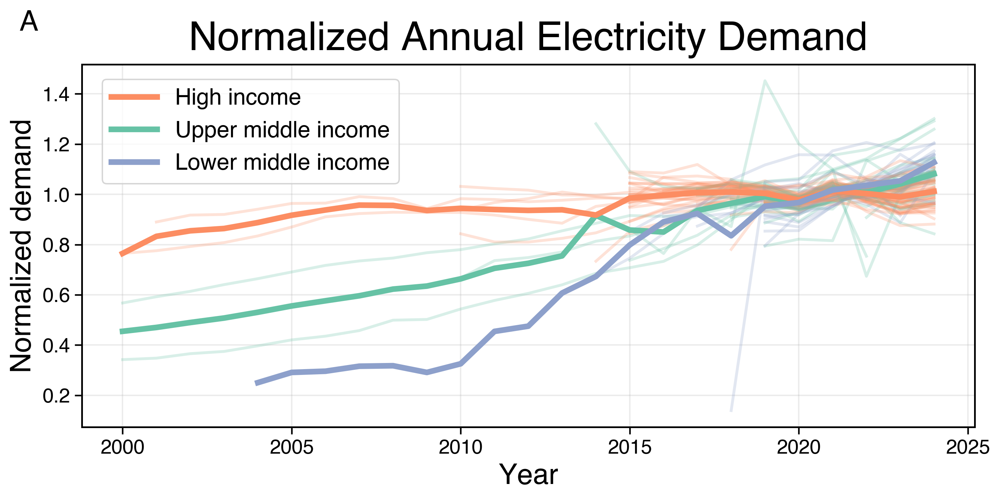

In [6]:
mdf['Year'] = mdf['Date'].dt.year
# Get annual mean electricity per country
annual = (mdf.groupby(['Country', 'Income group', 'Year'])['demand_gwh'].mean().reset_index())

# Get each country's baseline average electricity between 2015 and 2024, used to normalize electricity demand
baseline = (
    annual[(annual['Year'] >= 2015) & (annual['Year'] <= 2024)]
    .groupby('Country')['demand_gwh']
    .mean()
    .rename('baseline_mean')
)

# Apply baseline to each country
annual = annual.merge(baseline, on='Country', how='left')

# If a country has no data in 2015–2024, fallback to its overall mean
annual['baseline_mean'] = annual['baseline_mean'].fillna(
    annual.groupby('Country')['demand_gwh'].transform('mean')
)

# Normalize demand for plotting
annual['norm_demand'] = annual['demand_gwh'] / annual['baseline_mean']
group_means = (annual.groupby(['Income group', 'Year'])['norm_demand'].mean().reset_index())

# Now the figure!
fig, ax = plt.subplots(figsize=(10, 5))

# Set income groups + colour schemes
income_groups = annual['Income group'].unique()
palette = sns.color_palette("Set2", n_colors=len(income_groups)) # soft & distinct
income_color_map = dict(zip(income_groups, palette))

for country in annual['Country'].unique():
    cdf = annual[annual['Country'] == country]
    ig = cdf['Income group'].iloc[0]

    ax.plot(
        cdf['Year'],
        cdf['norm_demand'],
        lw=2,
        alpha=0.25,
        color=income_color_map[ig]
    )

for ig in income_groups:
    groupeddf = group_means[group_means['Income group'] == ig]

    ax.plot(
        groupeddf['Year'],
        groupeddf['norm_demand'],
        lw=4,
        alpha=1.0,
        color=income_color_map[ig],
        label=ig
    )

ax.set_title("Normalized Annual Electricity Demand", pad=10, fontsize = 28)
ax.set_xlabel("Year", fontsize = 20)
ax.set_ylabel("Normalized demand", fontsize = 20)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.grid(True, alpha=0.25)

desired_order = ["High income", "Upper middle income", "Lower middle income"]

handles, labels = ax.get_legend_handles_labels()
label_to_handle = dict(zip(labels, handles))

ordered_labels = (
    [ig for ig in desired_order if ig in labels] +
    [ig for ig in labels if ig not in desired_order]
)
ordered_handles = [label_to_handle[ig] for ig in ordered_labels]

ax.legend(
    ordered_handles, ordered_labels,
    loc="upper left",
    bbox_to_anchor=(0.01, 0.99),
    frameon=True,
    framealpha=0.8,
    fontsize=16
)

fig.text(0.03, 0.98, "A", fontsize=20, fontweight='bold', va='top', ha='left')
fig.tight_layout()
plt.savefig(OUT_DIR + "demand_over_time.png",
            bbox_inches='tight')
plt.show()


## Figure 1b

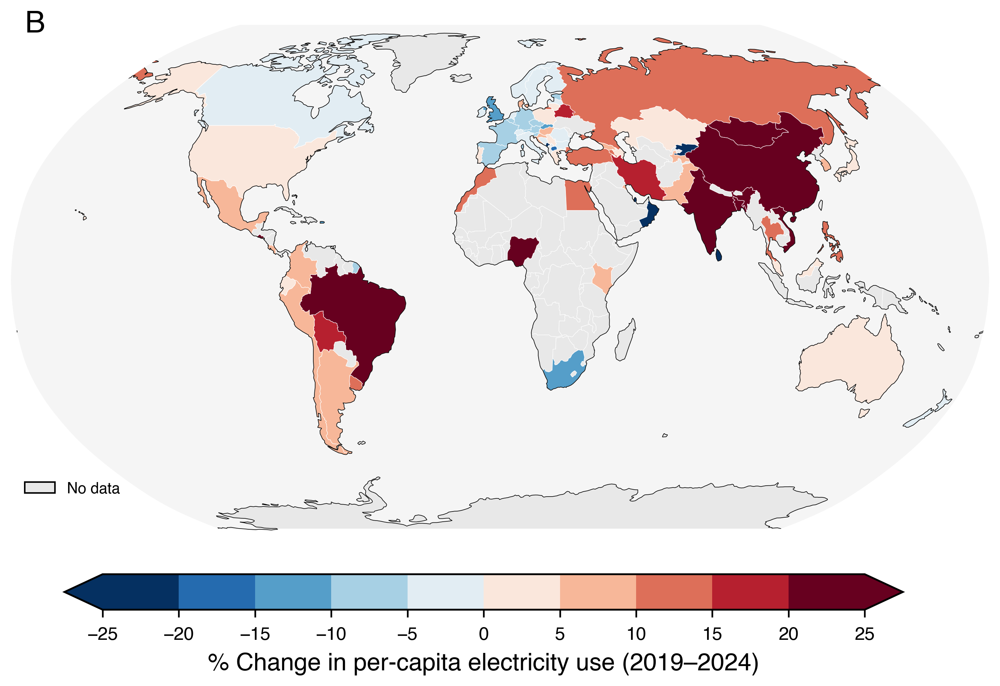

In [7]:
# Compute % change per country
# Only get 2019 and 2024 per country
df = (mdf[mdf['Year'].isin([2019, 2024])]
      .groupby(['Country', 'Year'])['demand_kwh_per_capita']
      .sum()
      .reset_index())

# Only countries with both years
countries = df.groupby('Country')['Year'].nunique()
df = df[df['Country'].isin(countries[countries == 2].index)]

# Get the per-capita electrcit for each year for each country
df_2019 = df[df['Year'] == 2019][['Country', 'demand_kwh_per_capita']]
df_2024 = df[df['Year'] == 2024][['Country', 'demand_kwh_per_capita']]

merged = df_2019.merge(df_2024, on='Country', suffixes=('_2019', '_2024'))

# Simple percent change: [(2024-2019) / 2019] *100
merged['pct_change'] = (
    (merged['demand_kwh_per_capita_2024'] - merged['demand_kwh_per_capita_2019'])
    / merged['demand_kwh_per_capita_2019'] * 100
)

# Annualized (compound) percent change: (1 + total)^(1/years) - 1
# Robust to period length -- total/years is only a linear approximation and
# increasingly overstates the true annual rate as the total change grows,
# since % change compounds year over year rather than adding linearly.
def annualize_pct(total_pct, years):
    return ((1 + total_pct / 100) ** (1 / years) - 1) * 100

merged['pct_change_annual'] = annualize_pct(merged['pct_change'], 2024 - 2019)

# Merge percent change onto world map
world_pct = gdf.merge(merged[['Country', 'pct_change']],
                        left_on='ADMIN', right_on='Country',
                        how='left')

mapping_stuff(world_pct, 'pct_change', 'RdBu_r', -25, 25, 'both', '',
              '% Change in per-capita electricity use (2019–2024)', 'electricity_change_map.png',
              letter = 'B', location = [0.15, 0.9], simplify_tolerance = 0.05)


In [8]:
print('number of countries with data before 2010: ', len(mdf['Country'][mdf['Date'].dt.year<2010].unique()))
print('number of countries with data before 2020: ', len(mdf['Country'][mdf['Date'].dt.year<2018].unique()))
print('number of countries with data before 2020: ', len(mdf['Country'][mdf['Date'].dt.year<2023].unique()))

number of countries with data before 2010:  5
number of countries with data before 2020:  46
number of countries with data before 2020:  85


## Figure S1

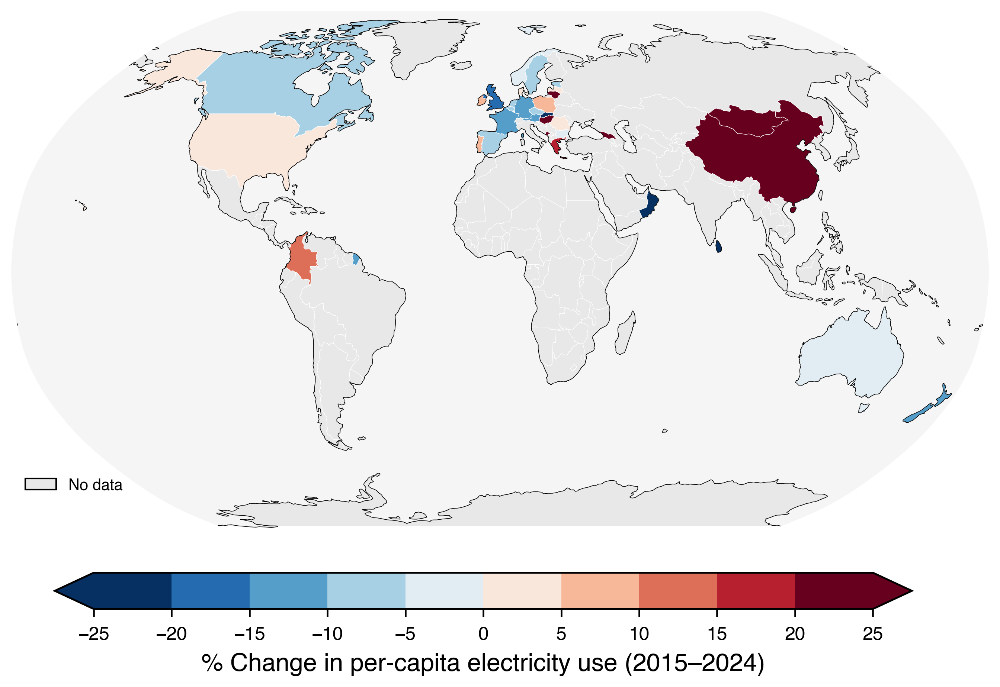

In [9]:
# Do the same but for 2015-2024, for comparison!

df = (mdf[mdf['Year'].isin([2015, 2024])]
      .groupby(['Country', 'Year'])['demand_kwh_per_capita']
      .sum()
      .reset_index())

countries = df.groupby('Country')['Year'].nunique()
df = df[df['Country'].isin(countries[countries == 2].index)]

df_2015 = df[df['Year'] == 2015][['Country', 'demand_kwh_per_capita']]
df_2024 = df[df['Year'] == 2024][['Country', 'demand_kwh_per_capita']]

merged2 = df_2015.merge(df_2024, on='Country', suffixes=('_2015', '_2024'))

merged2['pct_change'] = (
    (merged2['demand_kwh_per_capita_2024'] - merged2['demand_kwh_per_capita_2015'])
    / merged2['demand_kwh_per_capita_2015'] * 100
)

# Annualized (compound) percent change over the 2015-2024 window
merged2['pct_change_annual'] = annualize_pct(merged2['pct_change'], 2024 - 2015)

world_pct = gdf.merge(merged2[['Country', 'pct_change']],
                        left_on='ADMIN', right_on='Country',
                        how='left')

mapping_stuff(world_pct, 'pct_change', 'RdBu_r', -25, 25, 'both', '',
              '% Change in per-capita electricity use (2015–2024)', 'supplementary/electricity_change_map_2015.png', location = [0.15, 0.9], simplify_tolerance = 0.05)


In [10]:
# Function to get the weighted percent change.
# We sum demand_per_capita * population across all countries, then divide by the total population for all countries
# This gives the average per-capita electricity use of that GROUP, which allows us to compare between groups
def weighted_pct_change(df, years, value_col='demand_kwh_per_capita', pop_col='Population'):
    df = df[df['Year'].isin(years)]
    countries = df.groupby('Country')['Year'].nunique()
    df = df[df['Country'].isin(countries[countries == 2].index)]

    df_old = df[df['Year'] == years[0]][['Country', value_col, pop_col]]
    df_new = df[df['Year'] == years[1]][['Country', value_col, pop_col]]

    m = df_old.merge(df_new, on='Country', suffixes=('_old', '_new'))

    # Electricity demand: sum[demand_capita * population] / sum[population]
    E_old = (m[f'{value_col}_old'] * m[f'{pop_col}_old']).sum() / m[f'{pop_col}_old'].sum()
    E_new = (m[f'{value_col}_new'] * m[f'{pop_col}_new']).sum() / m[f'{pop_col}_new'].sum()

    n_countries = df['Country'].nunique()
    return ((E_new - E_old) / E_old) * 100, n_countries


# Population-weighted, whole-dataset % change for each period -- this is the
# 'Total' row appended to the table below (not a simple mean of the per-country rows,
# since countries are weighted by population here, as elsewhere in this analysis).
global_pct, n_countries_2019 = weighted_pct_change(mdf, [2019, 2024])
global_pct_annual = annualize_pct(global_pct, 2024 - 2019)

global_pct_2015, n_countries_2015 = weighted_pct_change(mdf, [2015, 2024])
global_pct_2015_annual = annualize_pct(global_pct_2015, 2024 - 2015)

result = merged.merge(merged2, on='Country', suffixes=('_2019', '_2015'))
# drop the duplicate demand column
result = result.drop(columns=['demand_kwh_per_capita_2024_2015'])
result = result.rename(columns={'demand_kwh_per_capita_2024_2019': 'demand_kwh_per_capita_2024'})

# Append a 'Total' row with the population-weighted % change across the whole dataset.
# Per-capita demand levels are left blank here since the 2019-2024 and 2015-2024 country
# sets differ in size (79 vs 33 countries), so there isn't a single well-defined
# 'total' demand level to report alongside the two period-specific pct-change figures.
total_row = {col: np.nan for col in result.columns}
total_row['Country'] = 'Total'
total_row['pct_change_2019'] = global_pct
total_row['pct_change_annual_2019'] = global_pct_annual
total_row['pct_change_2015'] = global_pct_2015
total_row['pct_change_annual_2015'] = global_pct_2015_annual
result = pd.concat([result, pd.DataFrame([total_row])], ignore_index=True)

result.to_csv(OUT_DIR_FILES + 'electricity_change_2015.csv')

# Save the electricity changes from 2015 and 2019, for comparison later!


In [11]:
# Getting values for text!
# (weighted_pct_change, global_pct, global_pct_annual, global_pct_2015, global_pct_2015_annual
# are all computed in the cell above, alongside the 'Total' row of the change table)

# 2019-2024 (seasonal)
cold_mdf = mdf[~mdf.apply(lambda r: r['Month'] in dynamic_warm[r['Country']], axis=1)]
warm_pct, _ = weighted_pct_change(wdf, [2019, 2024])
cold_pct, _ = weighted_pct_change(cold_mdf, [2019, 2024])

# 2019-2024 (by income group)
income_2019 = {}
for grp, gdfx in mdf[mdf['Income group'].notna()].groupby('Income group'):
    income_2019[grp], _ = weighted_pct_change(gdfx, [2019, 2024])

# 2015-2024 (by income group)
income_2015 = {}
for grp, gdfx in mdf[mdf['Income group'].notna()].groupby('Income group'):
    income_2015[grp], _ = weighted_pct_change(gdfx, [2015, 2024])


print(f"=== 2019-2024 ===")
print(f"N countries: {n_countries_2019}")
print(f"Global per-capita change: {global_pct:.1f}%  ({global_pct_annual:+.2f}%/year, annualized)")
print(f"Warm-season pct change: {warm_pct:.1f}%")
print(f"Cold-season pct change: {cold_pct:.1f}%")
print()
for grp in ['Lower middle income', 'Upper middle income', 'High income']:
    print(f"  {grp}: {income_2019.get(grp, float('nan')):.1f}%")

print(f"\n=== 2015-2024 ===")
print(f"N countries: {n_countries_2015}")
print(f"Global per-capita change: {global_pct_2015:.1f}%  ({global_pct_2015_annual:+.2f}%/year, annualized)")
for grp in ['Lower middle income', 'Upper middle income', 'High income']:
    print(f"  {grp}: {income_2015.get(grp, float('nan')):.1f}%")

# Check: countries whose pct_change sign flips between 2019-2024 and 2015-2024
sign_compare = merged[['Country', 'pct_change']].merge(
    merged2[['Country', 'pct_change']], on='Country', suffixes=('_2019', '_2015'))
sign_compare['flipped'] = (
    np.sign(sign_compare['pct_change_2019']) != np.sign(sign_compare['pct_change_2015'])
)
flipped = sign_compare[sign_compare['flipped']]
print(f"\nCountries with sign flip between periods (n={len(flipped)}): {sorted(flipped['Country'].tolist())}")


=== 2019-2024 ===
N countries: 79
Global per-capita change: 13.2%  (+2.52%/year, annualized)
Warm-season pct change: 15.4%
Cold-season pct change: 12.7%

  Lower middle income: 20.8%
  Upper middle income: 28.0%
  High income: 1.1%

=== 2015-2024 ===
N countries: 33
Global per-capita change: 29.1%  (+2.88%/year, annualized)
  Lower middle income: 18.4%
  Upper middle income: 72.2%
  High income: -2.9%

Countries with sign flip between periods (n=5): ['Australia', 'Ireland', 'Latvia', 'Montenegro', 'Romania']


In [12]:
# Per-capita electricity use by income group, 2024 — for text
income_order_pc = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']

raw_2024 = mdf[mdf['Year'] == 2024].dropna(subset=['demand_kwh_per_capita', 'Income group'])
pc_2024 = (raw_2024.groupby(['Country', 'Income group'])
           .agg(demand_kwh_per_capita=('demand_kwh_per_capita', 'mean'),
                Population=('Population', 'mean'))
           .reset_index()
           .dropna(subset=['demand_kwh_per_capita', 'Population']))

print("=== Per-capita electricity use by income group, 2024 ===")
for grp in income_order_pc:
    g = pc_2024[pc_2024['Income group'] == grp]
    g_raw = raw_2024[raw_2024['Income group'] == grp]
    if g.empty:
        print(f"{grp}: no countries with data")
        continue
    weighted_avg = (g['demand_kwh_per_capita'] * g['Population']).sum() / g['Population'].sum()
    print(f"{grp}: {weighted_avg:.1f} kWh/person "
          f"(range {g_raw['demand_kwh_per_capita'].min():.1f}-{g_raw['demand_kwh_per_capita'].max():.1f} kWh, "
          f"n={len(g)})")

=== Per-capita electricity use by income group, 2024 ===
Low income: no countries with data
Lower middle income: 92.2 kWh/person (range 9.8-283.1 kWh, n=14)
Upper middle income: 459.6 kWh/person (range 97.8-679.9 kWh, n=26)
High income: 716.5 kWh/person (range 198.8-2675.4 kWh, n=43)


## Figure 2: Balance temperatures

In [13]:
# Optimize a piecewise linear regression to get the best fits of heating and cooling lines
def two_hinge_features(x, tb_heat, tb_cool):
    heat = np.maximum(tb_heat - x, 0)
    cool = np.maximum(x - tb_cool, 0)
    return np.column_stack([heat, cool])

def single_cool_features(x, tb_cool):
    return np.maximum(x - tb_cool, 0).reshape(-1, 1)

def single_heat_features(x, tb_heat):
    return np.maximum(tb_heat - x, 0).reshape(-1, 1)

def estimate_balance_temp(country_name, cmin=15, cmax=26, hmin=5, hmax=16, min_cool_points=8):
    df = mdf[mdf['Country'] == country_name].copy().dropna(subset=['avg_temp', 'demand_gwh'])
    x = df['avg_temp'].values
    y = df['demand_gwh'].values

    if len(x) < 10:
        return None, None, 'insufficient_data', None

    # Case 1: always_hot — single cooling hinge
    if float(x.min()) > 15.0:
        data_min = np.percentile(x, 5)
        data_max = np.percentile(x, 95)
        # round to the nearest 0.5 + clip data extent:
        cmin_eff = np.round(max(cmin, data_min) * 2) / 2
        cmax_eff = np.round(min(cmax, data_max) * 2) / 2
        # if still out of range:
        if cmax_eff <= cmin_eff:
            cmin_eff = np.round(data_min * 2) / 2
            cmax_eff = np.round(data_max * 2) / 2

        best_mse, best_tbc = np.inf, None
        for tbc in np.arange(cmin_eff, cmax_eff + 0.5, 0.5):
            # need a certain number of points above the threshold
            if np.sum(x > tbc) < min_cool_points:
                continue
            # make everything below the threshold 0 (so it's flat)
            Xpw = single_cool_features(x, tbc)
            # fit linear regression
            m = LinearRegression().fit(Xpw, y)
            # get error
            mse = mean_squared_error(y, m.predict(Xpw))
            # if slope is positive and mse is very low, keep that line
            if mse < best_mse and m.coef_[0] > 0:
                best_mse, best_tbc = mse, tbc
        # Fallback: best MSE regardless of slope sign
        if best_tbc is None:
            for tbc in np.arange(cmin_eff, cmax_eff + 0.5, 0.5):
                if np.sum(x > tbc) < min_cool_points:
                    continue
                Xpw = single_cool_features(x, tbc)
                m = LinearRegression().fit(Xpw, y)
                mse = mean_squared_error(y, m.predict(Xpw))
                if mse < best_mse:
                    best_mse, best_tbc = mse, tbc
        # If still None (not enough warm data), treat as heating_only
        if best_tbc is None:
            return _fit_heating_only(x, y, hmin, hmax)
        return None, best_tbc, 'always_hot', best_mse

    # Cases 2 & 3: try two-hinge fit
    best_mse, best_tbh, best_tbc, best_cool_coef = np.inf, None, None, None
    for tbh in np.arange(hmin, hmax + 0.5, 0.5):
        for tbc in np.arange(cmin, cmax + 0.5, 0.5):
            if tbh >= tbc:
                continue
            if np.sum(x > tbc) < min_cool_points:
                continue
            Xpw = two_hinge_features(x, tbh, tbc)
            m = LinearRegression().fit(Xpw, y)
            mse = mean_squared_error(y, m.predict(Xpw))
            if mse < best_mse:
                best_mse, best_tbh, best_tbc, best_cool_coef = mse, tbh, tbc, m.coef_[1]

    # No valid two-hinge combo found (all tbc failed min_cool_points) so do heating only
    if best_tbc is None:
        return _fit_heating_only(x, y, hmin, hmax)

    # Cooling coefficient is non-positive so do heating only
    if best_cool_coef <= 0:
        return _fit_heating_only(x, y, hmin, hmax)

    return best_tbh, best_tbc, 'both', best_mse


def _fit_heating_only(x, y, hmin, hmax):
    # Refit with a single heating hinge when no valid cooling response exists
    best_mse, best_tbh = np.inf, None
    for tbh in np.arange(hmin, hmax + 0.5, 0.5):
        Xpw = single_heat_features(x, tbh)
        m = LinearRegression().fit(Xpw, y)
        mse = mean_squared_error(y, m.predict(Xpw))
        if mse < best_mse:
            best_mse, best_tbh = mse, tbh
    return best_tbh, None, 'heating_only', best_mse

def plot_balance_temp(country_name, letter=None):
    # Estimate thresholds and plot the piecewise fit!
    df = mdf[mdf['Country'] == country_name].copy().dropna(subset=['avg_temp', 'demand_gwh'])
    x = df['avg_temp'].values
    y = df['demand_gwh'].values

    Tb_heat, Tb_cool, regime, _ = estimate_balance_temp(country_name)

    x_range = np.linspace(x.min(), x.max(), 300)
    if regime == 'always_hot':
        X_fit = single_cool_features(x, Tb_cool)
        X_rng = single_cool_features(x_range, Tb_cool)
    elif regime == 'heating_only':
        X_fit = single_heat_features(x, Tb_heat)
        X_rng = single_heat_features(x_range, Tb_heat)
    else: # 'both'
        X_fit = two_hinge_features(x, Tb_heat, Tb_cool)
        X_rng = two_hinge_features(x_range, Tb_heat, Tb_cool)

    model = LinearRegression().fit(X_fit, y)
    y_range = model.predict(X_rng)

    fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
    ax.scatter(x, y, color='lightgray', alpha=0.6)
    ax.plot(x_range, y_range, color='purple', linewidth=2.5)

    handles = [
        Line2D([], [], color='lightgray', marker='o', linestyle='None', label='Observed demand'),
    ]
    if Tb_heat is not None:
        ax.axvline(Tb_heat, color='red', linestyle='--', linewidth=2)
        handles.append(Line2D([], [], color='red', linestyle='--', linewidth=2,
                              label=f'Heating threshold ({Tb_heat:.1f}°C)'))
    if Tb_cool is not None:
        ax.axvline(Tb_cool, color='blue', linestyle='--', linewidth=2)
        handles.append(Line2D([], [], color='blue', linestyle='--', linewidth=2,
                              label=f'Cooling threshold ({Tb_cool:.1f}°C)'))

    ax.set_xlabel('Monthly average temperature [°C]', fontsize=20, labelpad=10)
    ax.set_ylabel('Electricity demand [GWh]', fontsize=20, labelpad=10)
    ax.set_title(country_name, fontsize=22, pad=12)
    ax.legend(handles=handles, fontsize=13, loc='best')
    ax.grid(True)
    if letter:
        fig.text(0.03, 0.99, letter, fontsize=18, fontweight='bold', va='top', ha='left')

    fig.savefig(OUT_DIR + f'balancetemp_{country_name}.png',
                bbox_inches='tight')
    plt.show()


In [14]:
countries_list = mdf['Country'].unique()
results = []

for country in countries_list:
    Tb_heat, Tb_cool, regime, mse = estimate_balance_temp(country)
    results.append({
        'Country': country,
        'Tb_heat': Tb_heat,
        'Tb_cool': Tb_cool,
        'regime': regime,
        'mse': mse,
    })

results_df = pd.DataFrame(results)
# Tb_cool_for_cdd: use estimated threshold where available, 18.0 as standard fallback
# for heating-only and always_cold countries.
results_df[['Country','Tb_heat', 'Tb_cool']].to_csv(OUT_DIR_FILES + 'balance_temps.csv', index = False)

In [15]:
print('U-shaped', len(results_df[results_df['regime'] == 'both']))
print('No cold-driven', len(results_df[results_df['regime'] == 'always_hot']))
print('No warmth-driven', len(results_df[results_df['regime'] == 'heating_only']))
print('Mean balance temp', (results_df['Tb_cool']).mean())
print('USA', results_df['Tb_cool'][results_df['Country'] == 'United States of America'])
print('Korea', results_df['Tb_cool'][results_df['Country'] == 'South Korea'])

U-shaped 47
No cold-driven 22
No warmth-driven 16
Mean balance temp 20.159420289855074
USA 82    15.0
Name: Tb_cool, dtype: float64
Korea 71    21.0
Name: Tb_cool, dtype: float64


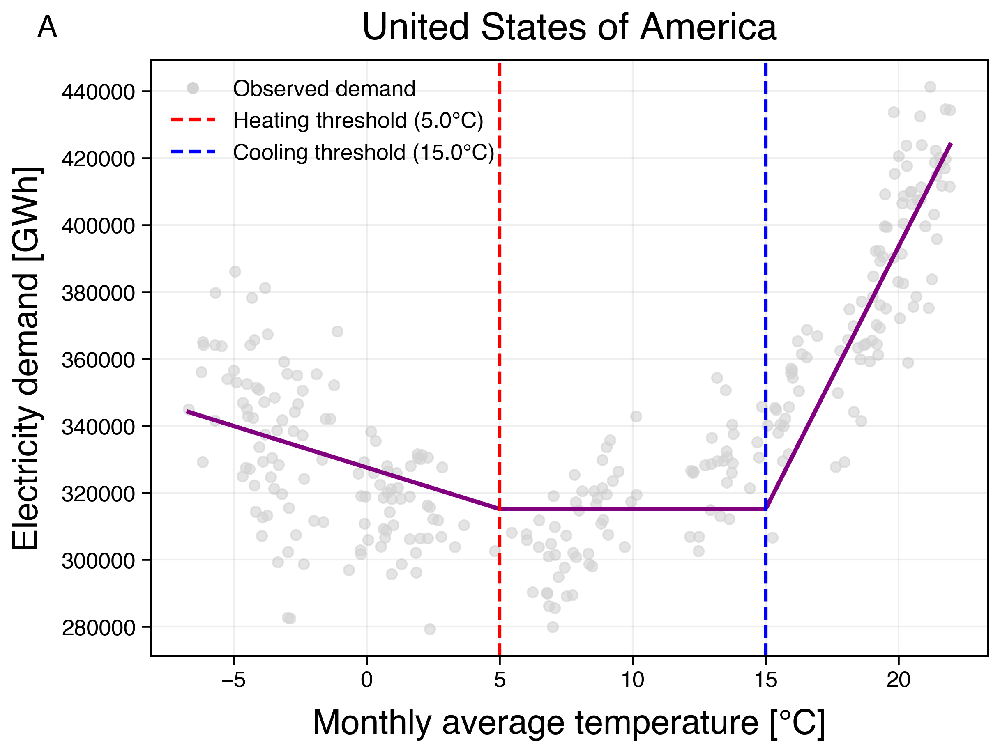

In [16]:
plot_balance_temp('United States of America', 'A')

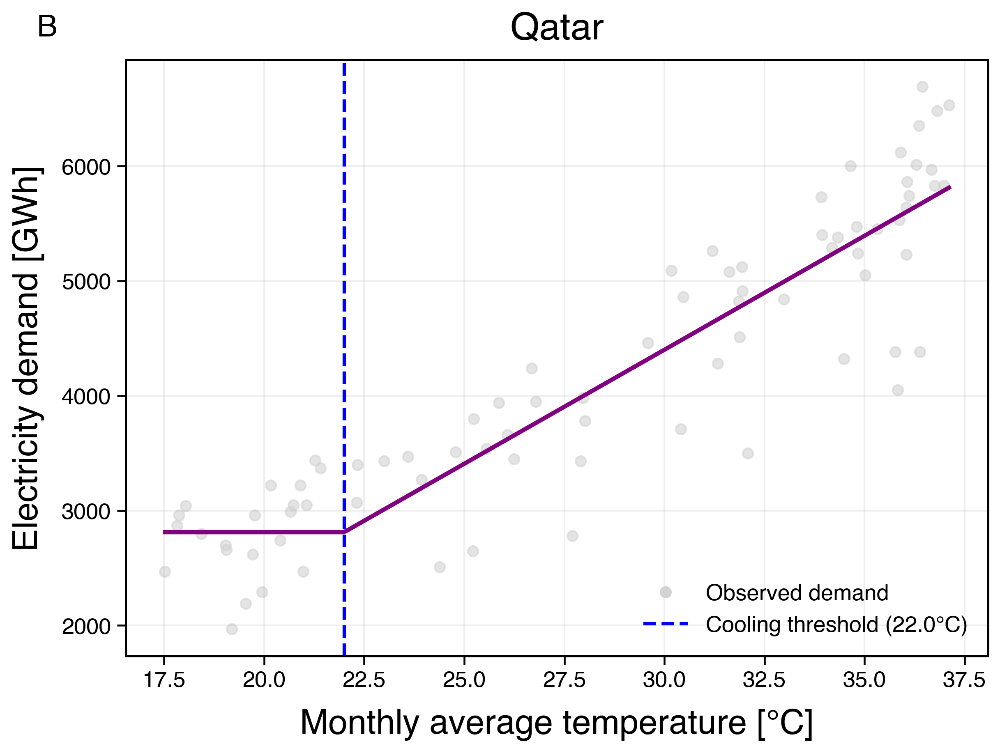

In [17]:
plot_balance_temp('Qatar', 'B')

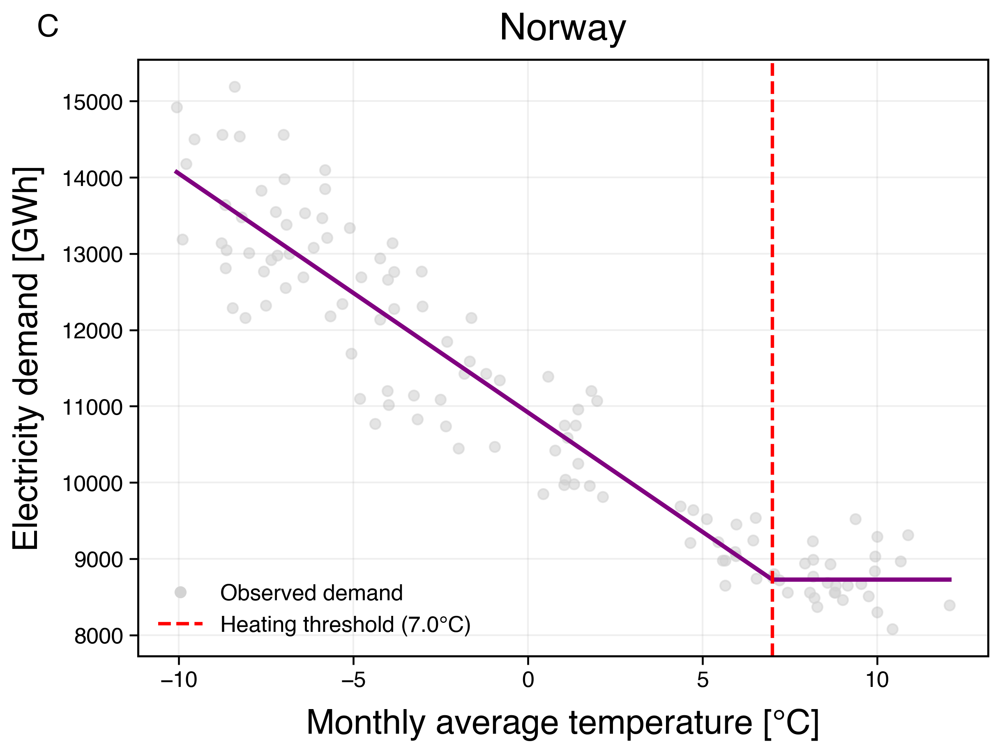

In [18]:
plot_balance_temp('Norway', 'C')

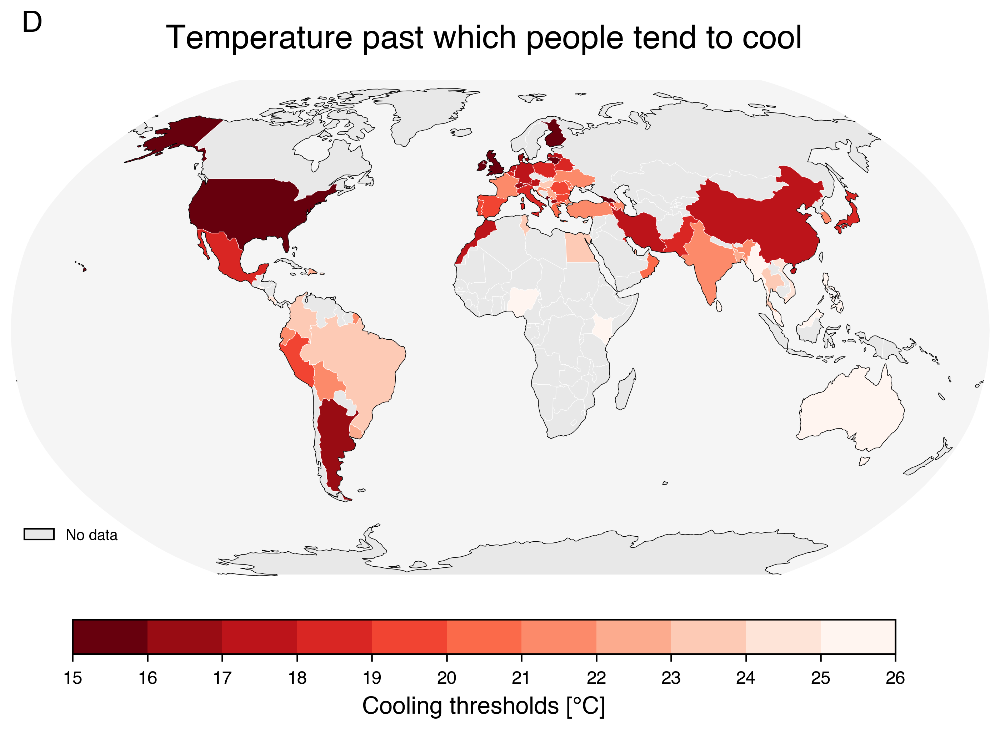

In [19]:
tb_map = gdf.merge(results_df[['Country', 'Tb_cool']], 
                        left_on='ADMIN', right_on='Country', 
                        how='left')

mapping_stuff(tb_map, 'Tb_cool', 'Reds_r', 15, 26, 'neither', 'Temperature past which people tend to cool', 
              'Cooling thresholds [°C]', 'tb_map.png', letter = 'D', location =[0.14, 0.98], n_bins=11)

In [20]:
def estimate_balance_cdd(country_name, variable='cdd_sum_avg', min_cool_points=8, n_steps=60):
    # Find the monthly-CDD threshold past which electricity demand starts
    # responding to cooling degree-days (single cooling hinge, CDD base 22°C)
    df = mdf[mdf['Country'] == country_name].copy().dropna(subset=[variable, 'demand_gwh'])
    x = df[variable].values
    y = df['demand_gwh'].values

    if len(x) < 10:
        return None, 'insufficient_data', None

    # Search candidate thresholds spanning this country's own CDD range —
    # CDD totals vary enormously between countries (tens vs. hundreds), so a
    # fixed search window (as used for temperature) doesn't work here.
    cmin, cmax = np.percentile(x, 5), np.percentile(x, 95)
    candidates = np.linspace(cmin, cmax, n_steps)

    best_mse, best_tbc = np.inf, None
    for tbc in candidates:
        if np.sum(x > tbc) < min_cool_points or np.sum(x <= tbc) < min_cool_points:
            continue
        Xpw = single_cool_features(x, tbc)
        m = LinearRegression().fit(Xpw, y)
        mse = mean_squared_error(y, m.predict(Xpw))
        if mse < best_mse and m.coef_[0] > 0:
            best_mse, best_tbc = mse, tbc

    if best_tbc is None:
        return None, 'no_response', None

    return best_tbc

for country in ['United States of America', 'South Korea']:
    cdd_b = estimate_balance_cdd(country)
    print(f"{country}: balance CDD = {cdd_b:.1f}")


United States of America: balance CDD = 51.9
South Korea: balance CDD = 118.1


## Figure S2

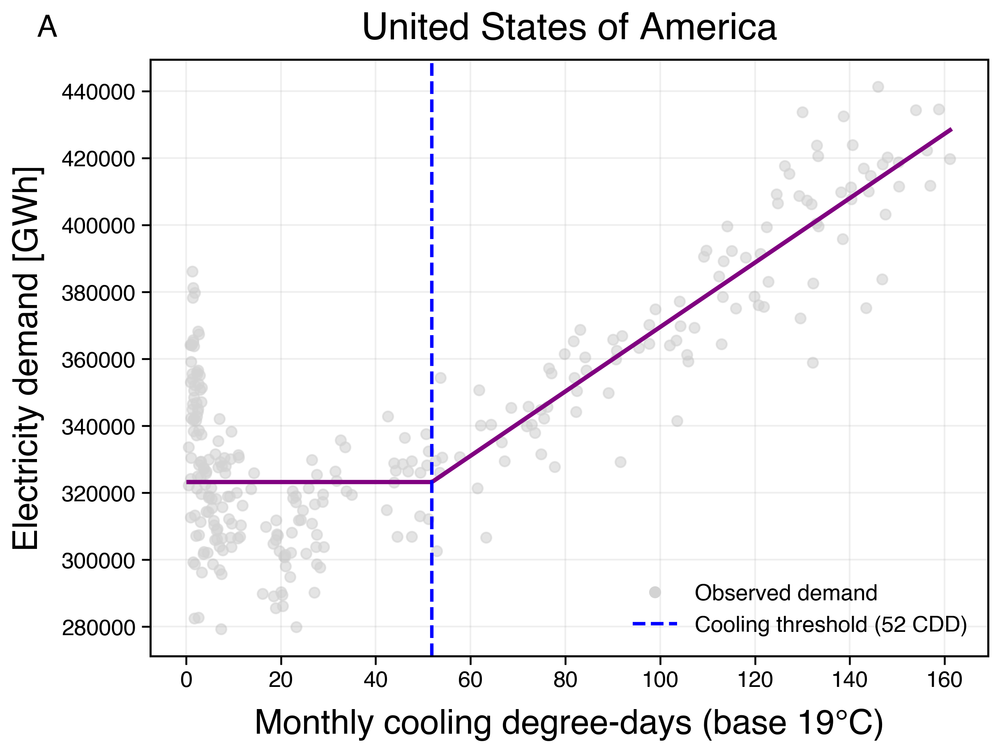

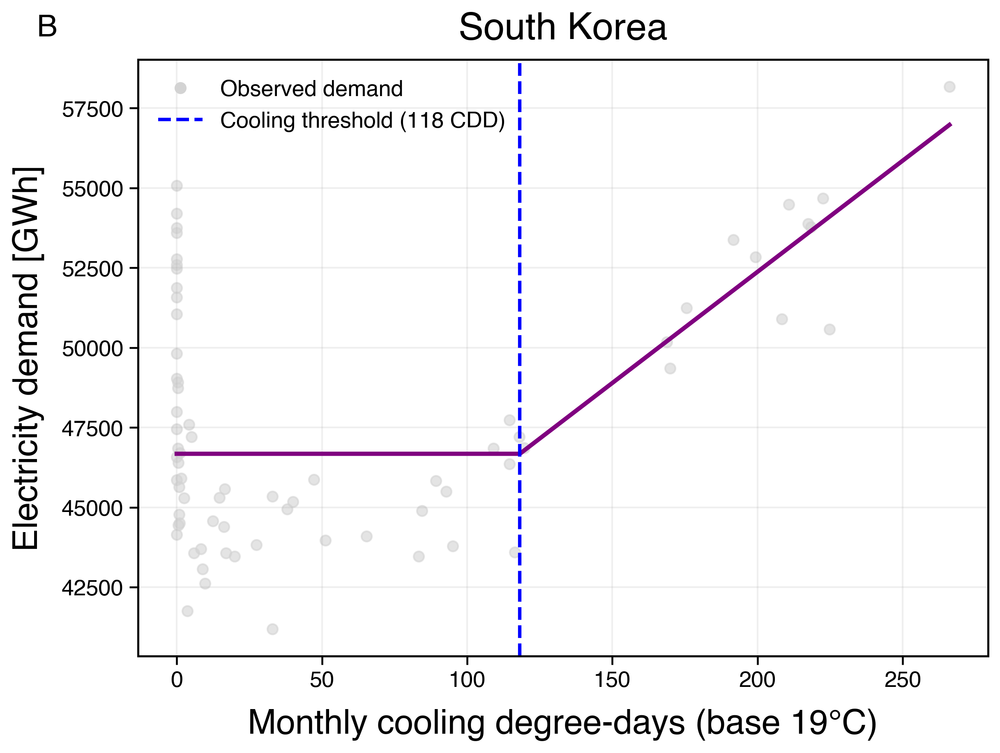

In [21]:
def plot_balance_cdd(country_name, variable='cdd_sum_avg', letter=None):
    # One-hinge analogue of plot_balance_temp: CDD (base 19°C) is already
    # zero-floored below the reference temperature, so there's no heating side.
    df = mdf[mdf['Country'] == country_name].copy().dropna(subset=[variable, 'demand_gwh'])
    x = df[variable].values
    y = df['demand_gwh'].values

    Tb_cool = estimate_balance_cdd(country_name, variable=variable)

    x_range = np.linspace(x.min(), x.max(), 300)
    X_fit = single_cool_features(x, Tb_cool)
    X_rng = single_cool_features(x_range, Tb_cool)

    model = LinearRegression().fit(X_fit, y)
    y_range = model.predict(X_rng)

    fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
    ax.scatter(x, y, color='lightgray', alpha=0.6)
    ax.plot(x_range, y_range, color='purple', linewidth=2.5)

    handles = [
        Line2D([], [], color='lightgray', marker='o', linestyle='None', label='Observed demand'),
        Line2D([], [], color='blue', linestyle='--', linewidth=2,
               label=f'Cooling threshold ({Tb_cool:.0f} CDD)'),
    ]
    ax.axvline(Tb_cool, color='blue', linestyle='--', linewidth=2)

    ax.set_xlabel('Monthly cooling degree-days (base 19°C)', fontsize=20, labelpad=10)
    ax.set_ylabel('Electricity demand [GWh]', fontsize=20, labelpad=10)
    ax.set_title(country_name, fontsize=22, pad=12)
    ax.legend(handles=handles, fontsize=13, loc='best')
    ax.grid(True)
    if letter:
        fig.text(0.03, 0.99, letter, fontsize=18, fontweight='bold', va='top', ha='left')

    fig.savefig(OUT_DIR + f'supplementary/balancecdd_{country_name}.png',
                bbox_inches='tight')
    plt.show()


plot_balance_cdd('United States of America', letter='A')
plot_balance_cdd('South Korea', letter='B')

## Figure 3: Linear relationship

In [22]:
# Use adjusted r2
def adjusted_r2(r2, n, p):
    if n == p + 1:
        return -np.inf
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

# This tries to fit different lines-- we ended up going with just linear, but you can adjust max-degree at the input to test different lines of fit
def fit_poly_with_adj_r2(x, y, max_degree=3):
    n = len(x)
    best_adj_r2 = -np.inf
    best_model = None
    best_degree = None
    max_degree = min(max_degree, n - 2)
    for degree in range(1, max_degree + 1):
        model = make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression())
        model.fit(x.reshape(-1, 1), y)
        r2 = model.score(x.reshape(-1, 1), y)
        adj_r2 = adjusted_r2(r2, n, degree)
        if adj_r2 > best_adj_r2:
            best_adj_r2 = adj_r2
            best_model = model
            best_degree = degree
    if best_model is None:
        return None
    return {'model': best_model, 'degree': best_degree, 'adj_r2': best_adj_r2}


def get_linear_r2(warm_df, variable='cdd_sum_sum'):
    results = []
    for country in warm_df['Country'].unique():
        dfc = warm_df[warm_df['Country'] == country].dropna(subset=[variable, 'demand_gwh', 'avg_temp'])
        if len(dfc) < 5:
            continue
        row = df_ac[df_ac['Country'] == country]
        if row.empty:
            continue
        X = dfc[variable].values
        y = dfc['demand_gwh'].values
        fit = fit_poly_with_adj_r2(X, y, max_degree=1)
        if fit is None:
            continue
        _, _, _, p_value, _ = stats.linregress(X, y)
        results.append({
            'Country': country,
            'BestDegree': fit['degree'],
            'BestR2': fit['adj_r2'],
            'p_value': p_value,
            'significant': p_value < 0.05,
            'AC': row['AC'].values[0],
            'avg_temp': dfc['avg_temp'].mean(),
            'avg_gdp': dfc['GDP'].mean(),
            'avg_pop': dfc['Population'].mean(),
            'gdp_capita': np.mean(dfc['GDP'] / dfc['Population']),
        })
    return pd.DataFrame(results)

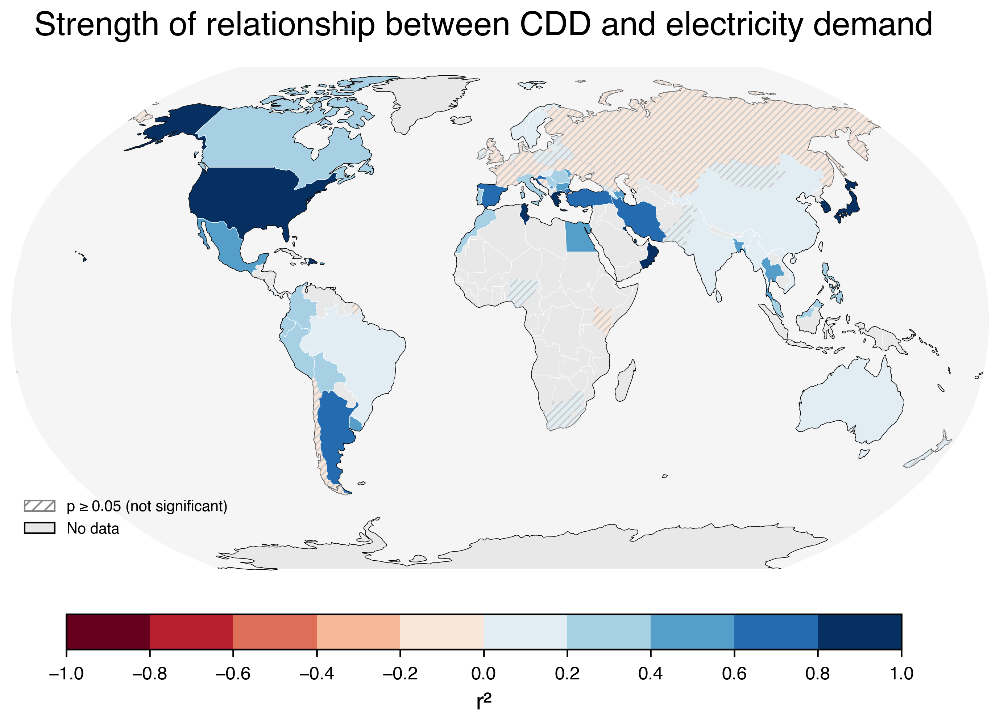

In [23]:
df_all = get_linear_r2(wdf)

r2_map = gdf.merge(df_all[['Country', 'BestR2', 'p_value']], 
                   left_on='ADMIN', right_on='Country', how='left')
mapping_stuff(r2_map, 'BestR2', 'RdBu', -1, 1, 'neither', 
              'Strength of relationship between CDD and electricity demand',
              'r²', 'r2_map.png', pval_col='p_value')

In [24]:
print('Countries over 0.6:', len(df_all[df_all['BestR2']>0.6]))
print('Countries below 0.3:', len(df_all[df_all['BestR2']<0.3]))

Countries over 0.6: 15
Countries below 0.3: 57


## Figure S3: Linear relationship (CDD base 22°C)

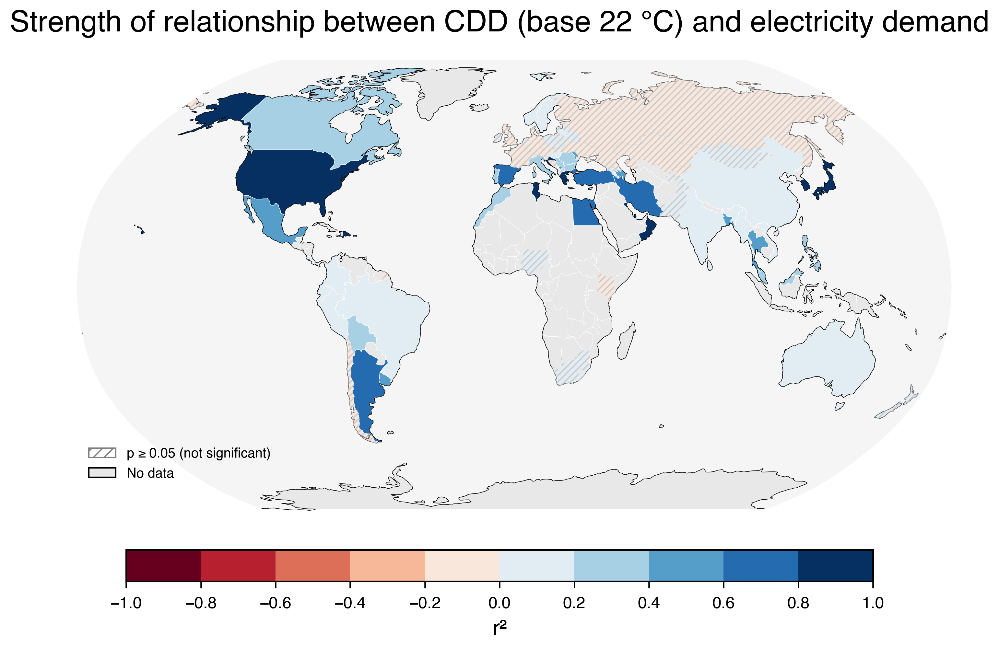

Countries over 0.6: 16
Countries below 0.3: 56


In [25]:
# Same as Figure 3, but using CDD computed with a 22°C base temperature.
# Kept in a separate dataframe (wdf22) so mdf/wdf still hold the base-19 CDDs.
# Same countries and warm-season months as wdf; only the CDD columns are swapped.
df_cdd22 = pd.read_csv(CLIMATE_DIR + 'monthly_cdd_base22.csv')
df_cdd22['Date'] = pd.to_datetime(df_cdd22['Date'], format='%Y-%m-%d')

wdf22 = (wdf.drop(columns=['cdd_sum_avg', 'cdd_sum_sum', 'cdd_sum_sq'])
         .merge(df_cdd22[['Country', 'Date', 'cdd_sum_avg', 'cdd_sum_sum']], on=['Country', 'Date'], how='left'))
wdf22['cdd_sum_sq'] = wdf22['cdd_sum_sum'] ** 2

df_all22 = get_linear_r2(wdf22)

r2_map22 = gdf.merge(df_all22[['Country', 'BestR2', 'p_value']], 
                     left_on='ADMIN', right_on='Country', how='left')
mapping_stuff(r2_map22, 'BestR2', 'RdBu', -1, 1, 'neither', 
              'Strength of relationship between CDD (base 22 °C) and electricity demand',
              'r²', 'supplementary/r2_map_cdd22.png', pval_col='p_value')

print('Countries over 0.6:', len(df_all22[df_all22['BestR2']>0.6]))
print('Countries below 0.3:', len(df_all22[df_all22['BestR2']<0.3]))

## Figure 4: r2 vs. other factors

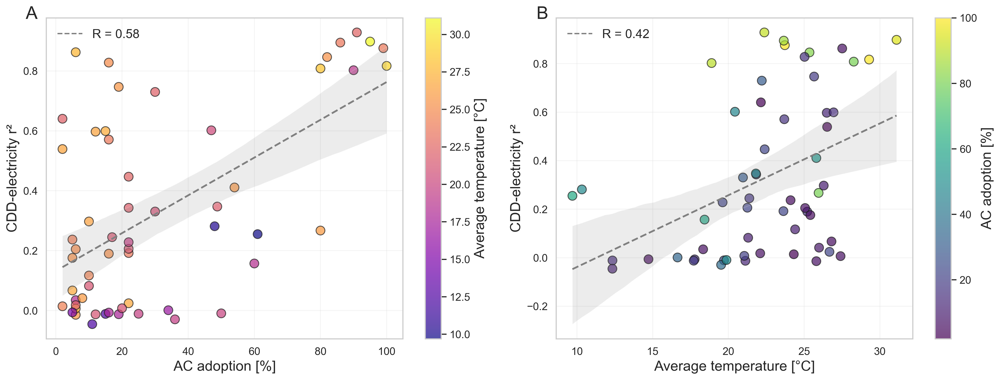

Figure 4 sample sizes: panel A n = 57 countries, panel B n = 57 countries


In [26]:
def scatter_with_fit(ax, x, y, xlabel, ylabel=None, subset=None, color_by=None, cmap_name='viridis', letter = None, location = [0.01, 0.99]):
    # Scatter + OLS fit line + legend with R² (subset optional, optional color gradient).
    if subset is not None:
        if color_by:
            df = subset[[x, y, color_by]].dropna()
        else:
            df = subset[[x, y]].dropna()
    else:
        if color_by:
            df = df_all[[x, y, color_by]].dropna()
        else:
            df = df_all[[x, y]].dropna()

    if df.empty:
        print(f"No data for {xlabel} vs {ylabel}")
        return

    X = sm.add_constant(df[x])
    model = sm.OLS(df[y], X).fit()
    r2 = model.rsquared
    slope = model.params[1] # coefficient on x
    r = np.sign(slope) * np.sqrt(r2)

    # Scatter with gradient color if color_by is provided
    if color_by:
        sc = ax.scatter(
            df[x], df[y],
            c=df[color_by],
            cmap=cmap_name,
            s=100,
            edgecolor='k',
            alpha=0.7
        )
        cbar = plt.colorbar(sc, ax=ax)
        if(color_by == 'avg_temp'):
            cbar.set_label('Average temperature [°C]', fontsize=16)
        elif(color_by == 'AC'):
            cbar.set_label('AC adoption [%]', fontsize=16)

        cbar.ax.tick_params(labelsize=12)
    else:
        sc = ax.scatter(
            df[x], df[y],
            color='steelblue',
            s=100,
            edgecolor='k',
            alpha=0.7
        )

    # Dashed fit line
    sns.regplot(
        data=df, x=x, y=y,
        scatter=False, ax=ax,
        color='gray',
        line_kws={'linestyle': 'dashed', 'linewidth': 2}
    )

    # Legend with r
    legend_text = f"R = {r:.2f}"
    legend_handles = [Line2D([], [], color='gray', linestyle='--', label=legend_text)]
    ax.legend(handles=legend_handles, fontsize=14)
    ax.set_xlabel(xlabel, fontsize=16)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=16)
    ax.tick_params(labelsize=12)
    fig.text(location[0], location[1], letter, fontsize=20, va='top', ha='left')


sns.set(style="whitegrid") # consistent style
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes = axes.flatten() # easier indexing

# --- Plot 1: AC adoption colored by temperature ---
df_ac = df_all.merge(df_ac[['Country','Notes']], on='Country')
df_ac = df_ac[df_ac['Notes'] != 'Dubious']
scatter_with_fit(
    axes[0], x='AC', y='BestR2',
    xlabel='AC adoption [%]',
    ylabel='CDD-electricity r²',
    subset=df_ac,
    color_by='avg_temp',
    cmap_name='plasma',
    letter = 'A', 
    location = [0.03, 0.99]
)

# --- Plot 2: Avg temperature colored by AC adoption ---
scatter_with_fit(
    axes[1], x='avg_temp', y='BestR2',
    xlabel='Average temperature [°C]',
    ylabel='CDD-electricity r²',
    subset=df_ac,
    color_by='AC',
    cmap_name='viridis',
    letter = 'B', 
    location = [0.53, 0.99]
)


plt.tight_layout()
plt.savefig(OUT_DIR + 'r2_all_2x1.png', dpi=300)
plt.show()

# Sample sizes for the figure caption (n = countries plotted in each panel)
n_a = len(df_ac[['AC', 'BestR2', 'avg_temp']].dropna())
n_b = len(df_ac[['avg_temp', 'BestR2', 'AC']].dropna())
print(f"Figure 4 sample sizes: panel A n = {n_a} countries, panel B n = {n_b} countries")

# MODELING 

## OLS vs GAM-temp — combined comparison

In [27]:
# Model setup: feature sets, target, and shared helpers
# Needed by run_ols_gam_combined_cv (Figure 6) and the pooled-GAM PDP cells
# (Figures 8-10), so this must run even if res_combined is loaded from cache.
TARGET = 'demand_gwh'

OLS_BASE = ['GDP', 'Population']
OLS_CDD = ['GDP', 'Population', 'cdd_sum_sum', 'cdd_sum_sq']
OLS_ELD = ['GDP', 'Population', 'avg_ELD']
OLS_CDD_ELD = ['GDP', 'Population', 'cdd_sum_sum', 'cdd_sum_sq', 'avg_ELD']

GAM_BASE = ['GDP', 'Population']
GAM_ELD = ['GDP', 'Population', 'avg_ELD']
GAM_TEMP = ['GDP', 'Population', 'avg_temp']
GAM_TEMP_ELD = ['GDP', 'Population', 'avg_temp', 'avg_ELD']

MIN_SAMPLES = 12


def _country_meta(wdf, country_name):
    df2 = wdf[wdf['Country'] == country_name][['avg_temp', 'avg_ELD', 'GDP', 'Population', 'AC']].dropna()
    if df2.empty:
        return np.nan, np.nan, np.nan, np.nan
    return (df2['avg_temp'].mean(),
            df2['avg_ELD'].mean(),
            (df2['GDP'] / df2['Population']).mean(),
            df2['AC'].iloc[0])


def _safe_ttest(a, b):
    if len(a) > 1 and len(a) == len(b):
        return ttest_rel(a, b)[1]
    return np.nan


In [28]:
def run_ols_gam_combined_cv(wdf, n_splits=100, n_splines=6, label='OLS+GAM-temp'):
    """
    For each country, runs n random 80/20 splits and fits both OLS and
    GAM across four model specifications (base, +temp/CDD, +ELD, +temp/CDD+ELD).

    OLS CDD term  : CDD + CDD²  (cdd_sum_sum, cdd_sum_sq)
    GAM temp term  : avg_temp   (nonlinear spline — threshold learned endogenously)

    Returns a single DataFrame with per-country mean R² for every model × family
    combination, within-family deltas, and paired t-test p-values both within each
    family (each spec vs. base) and across families (GAM vs. OLS for matched specs).
    """
    # Feature sets
    ols_feats = {
        'base': OLS_BASE,
        'cdd': OLS_CDD, # GDP + Pop + CDD + CDD²
        'eld': OLS_ELD,
        'cdd_eld': OLS_CDD_ELD, # GDP + Pop + CDD + CDD² + ELD
    }
    gam_feats = {
        'base': GAM_BASE,
        'temp': GAM_TEMP, # GDP + Pop + avg_temp ↔ OLS 'cdd'
        'eld': GAM_ELD,
        'temp_eld': GAM_TEMP_ELD, # GDP + Pop + avg_temp + ELD ↔ OLS 'cdd_eld'
    }

    # GAM builders (one lambda per spec to get a fresh model each split)
    gam_builders = {
        'base': lambda: LinearGAM(s(0, n_splines=n_splines) + s(1, n_splines=n_splines)),
        'temp': lambda: LinearGAM(s(0, n_splines=n_splines) + s(1, n_splines=n_splines) +
                                      s(2, n_splines=n_splines)),
        'eld': lambda: LinearGAM(s(0, n_splines=n_splines) + s(1, n_splines=n_splines) +
                                      s(2, n_splines=n_splines)),
        'temp_eld': lambda: LinearGAM(s(0, n_splines=n_splines) + s(1, n_splines=n_splines) +
                                      s(2, n_splines=n_splines) + s(3, n_splines=n_splines)),
    }

    # All columns required across every spec
    all_cols = list(set(OLS_CDD_ELD + GAM_TEMP_ELD + [TARGET]))

    countries = [c for c, g in wdf.groupby('Country')
                 if len(g.dropna(subset=all_cols)) >= MIN_SAMPLES]

    ss = ShuffleSplit(n_splits=n_splits, test_size=0.2, random_state=42)
    results = []

    for country_name in countries:
        df = (wdf[wdf['Country'] == country_name]
              .sort_values('Date')[all_cols + ['Date']]
              .dropna())
        if len(df) < MIN_SAMPLES:
            continue

        y = df[TARGET].values
        ols_X = {k: df[v].values for k, v in ols_feats.items()}
        gam_X = {k: df[v].values for k, v in gam_feats.items()}

        ols_r2 = {k: [] for k in ols_feats}
        gam_r2 = {k: [] for k in gam_feats}

        for train_idx, test_idx in ss.split(y):
            if len(test_idx) < 2:
                continue

            # OLS
            for key, X in ols_X.items():
                m = LinearRegression().fit(X[train_idx], y[train_idx])
                ols_r2[key].append(r2_score(y[test_idx], m.predict(X[test_idx])))

            # GAM-temp
            for key in gam_X:
                try:
                    gam = gam_builders[key]()
                    gam.fit(gam_X[key][train_idx], y[train_idx])
                    gam_r2[key].append(r2_score(y[test_idx], gam.predict(gam_X[key][test_idx])))
                except Exception:
                    pass

        if not ols_r2['base'] or not gam_r2['base']:
            continue

        o = {k: np.array(v) for k, v in ols_r2.items()}
        g = {k: np.array(v) for k, v in gam_r2.items()}

        avg_temp, avg_eld, gdp_capita, AC = _country_meta(wdf, country_name)

        results.append({
            'Country': country_name,

            # OLS mean R²
            'avg_R2_ols_base': o['base'].mean(),
            'avg_R2_ols_cdd': o['cdd'].mean(),
            'avg_R2_ols_eld': o['eld'].mean(),
            'avg_R2_ols_cdd_eld': o['cdd_eld'].mean(),

            # GAM-temp mean R²
            'avg_R2_gam_base': g['base'].mean(),
            'avg_R2_gam_temp': g['temp'].mean(),
            'avg_R2_gam_eld': g['eld'].mean(),
            'avg_R2_gam_temp_eld': g['temp_eld'].mean(),

            # OLS deltas vs OLS base
            'delta_R2_ols_cdd': o['cdd'].mean() - o['base'].mean(),
            'delta_R2_ols_eld': o['eld'].mean() - o['base'].mean(),
            'delta_R2_ols_eld_on_cdd': o['cdd_eld'].mean() - o['cdd'].mean(), # marginal ELD on top of CDD

            # GAM deltas vs GAM base
            'delta_R2_gam_temp': g['temp'].mean() - g['base'].mean(),
            'delta_R2_gam_eld': g['eld'].mean() - g['base'].mean(),
            'delta_R2_gam_eld_on_temp': g['temp_eld'].mean() - g['temp'].mean(), # marginal ELD on top of temp

            # Within-OLS p-values
            'pval_ols_cdd': _safe_ttest(o['cdd'], o['base']),
            'pval_ols_eld': _safe_ttest(o['eld'], o['base']),
            'pval_ols_eld_on_cdd': _safe_ttest(o['cdd_eld'], o['cdd']), # marginal ELD given CDD

            # Within-GAM p-values
            'pval_gam_temp': _safe_ttest(g['temp'], g['base']),
            'pval_gam_eld': _safe_ttest(g['eld'], g['base']),
            'pval_gam_eld_on_temp': _safe_ttest(g['temp_eld'], g['temp']), # marginal ELD given temp

            # GAM vs OLS cross-family p-values (matched specs)
            'pval_gam_vs_ols_base': _safe_ttest(g['base'], o['base']),
            'pval_gam_vs_ols_cdd': _safe_ttest(g['temp'], o['cdd']),
            'pval_gam_vs_ols_eld': _safe_ttest(g['eld'], o['eld']),
            'pval_gam_vs_ols_cdd_eld': _safe_ttest(g['temp_eld'], o['cdd_eld']),

            # GAM − OLS deltas (matched specs)
            'delta_gam_ols_base': g['base'].mean() - o['base'].mean(),
            'delta_gam_ols_cdd': g['temp'].mean() - o['cdd'].mean(),
            'delta_gam_ols_eld': g['eld'].mean() - o['eld'].mean(),
            'delta_gam_ols_cdd_eld': g['temp_eld'].mean() - o['cdd_eld'].mean(),

            # Country-level covariates
            'avg_temp': avg_temp,
            'avg_ELD': avg_eld,
            'gdp_capita': gdp_capita,
            'AC': AC,
        })

    print(f"[{label}] {len(results)} countries")
    return pd.DataFrame(results)

# Cache: load if available, otherwise compute

# IF RERUNNING WITH NEW DATA, DELETE THE OLD PARQUET FILE!
import os
_RC_CACHE = OUT_DIR_FILES + 'res_combined.parquet'

if os.path.exists(_RC_CACHE):
    res_combined = pd.read_parquet(_RC_CACHE)
    print(f"res_combined loaded from cache ({len(res_combined)} countries). "
          f"Delete {_RC_CACHE!r} to recompute.")
else:
    res_combined = run_ols_gam_combined_cv(wdf, n_splits=100, n_splines=6)
    res_combined.to_parquet(_RC_CACHE, index=False)
    print("res_combined computed and saved to cache.")


res_combined loaded from cache (85 countries). Delete '/Users/charlottecockburn/Documents/Columbia/AC_project/Tables/res_combined.parquet' to recompute.


In [29]:
print('OLS greater than 0.6:', len(res_combined[res_combined['avg_R2_ols_cdd_eld']>0.6]))
print('GAM greater than 0.6:', len(res_combined[res_combined['avg_R2_gam_temp_eld']>0.6]))

OLS greater than 0.6: 35
GAM greater than 0.6: 37


In [30]:
print("\n--- Summary (full model: cdd_eld / temp_eld) ---")
n_sig = ((res_combined['pval_gam_vs_ols_cdd_eld'] < 0.05) & (res_combined['delta_gam_ols_cdd_eld'] > 0)).sum()
print(f"\nCountries where GAM significantly outperforms OLS (p<0.05): {n_sig} / {len(res_combined)}")
n_sig_bad = ((res_combined['pval_gam_vs_ols_cdd_eld'] < 0.05) & (res_combined['delta_gam_ols_cdd_eld'] < 0)).sum()
print(f"\nCountries where GAM significantly underperforms OLS (p<0.05): {n_sig_bad} / {len(res_combined)}")

t, p = stats.ttest_rel(res_combined['avg_R2_gam_temp_eld'].dropna(),
                        res_combined['avg_R2_ols_cdd_eld'].dropna())
print(f"\nOverall paired t-test: t={t:.3f}, p={p:.4f}")



--- Summary (full model: cdd_eld / temp_eld) ---

Countries where GAM significantly outperforms OLS (p<0.05): 49 / 85

Countries where GAM significantly underperforms OLS (p<0.05): 18 / 85

Overall paired t-test: t=0.159, p=0.8744


## Figure S4: Model performance

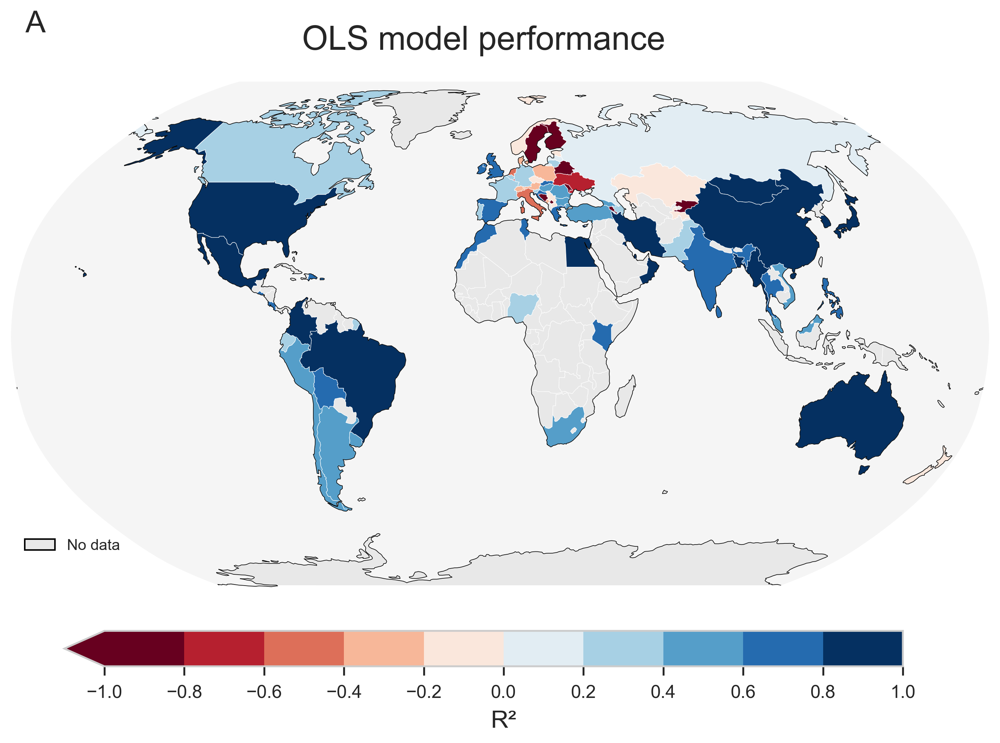

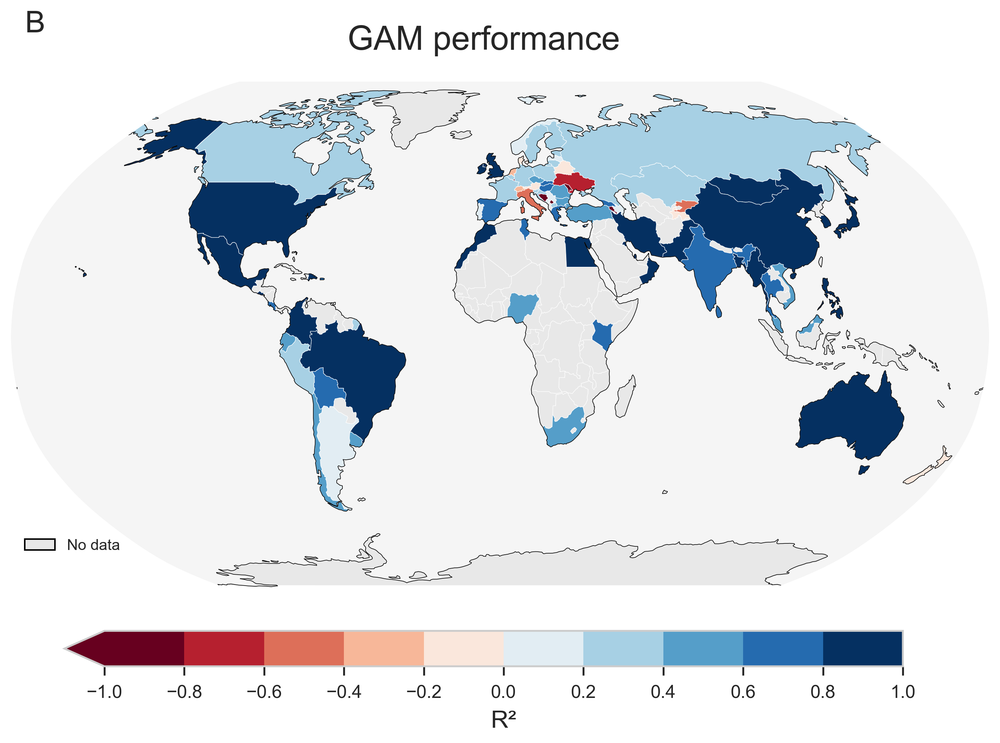

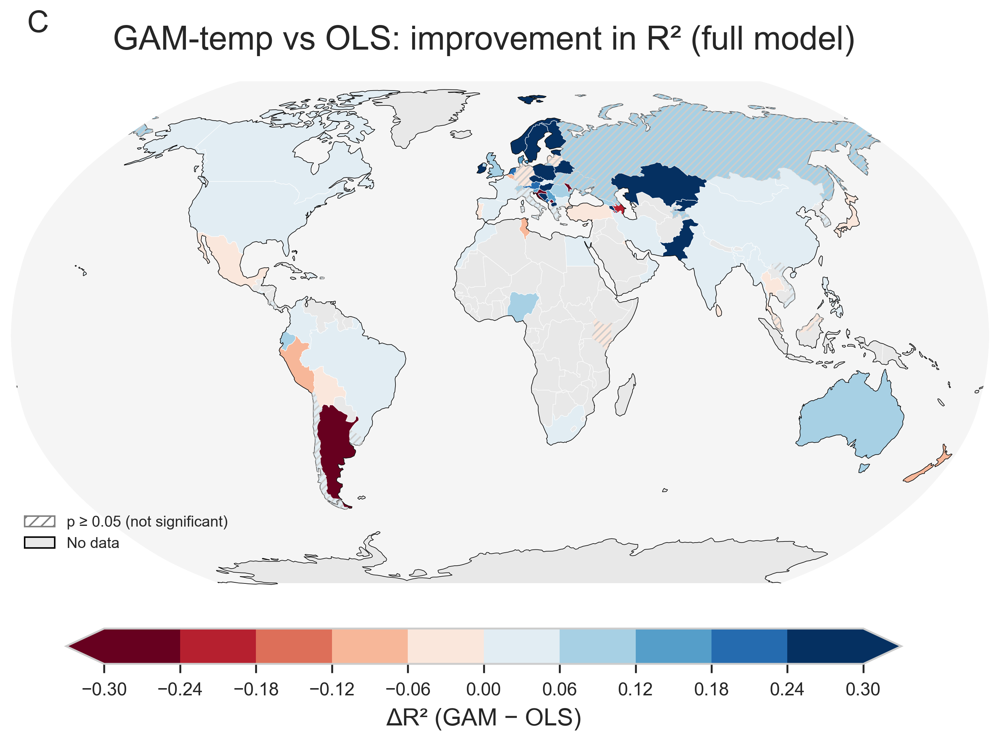

In [31]:
ols_map = gdf.merge(res_combined[['Country', 'avg_R2_ols_cdd_eld']],
                    left_on='ADMIN', right_on='Country', how='left')

mapping_stuff(ols_map, 'avg_R2_ols_cdd_eld', 'RdBu', -1, 1, 'neither', 'OLS model performance', 
              'R²', 'supplementary/ols_performance_map.png', letter = 'A')

# GAM
gam_map = gdf.merge(res_combined[['Country', 'avg_R2_gam_temp_eld']],
                    left_on='ADMIN', right_on='Country', how='left')

mapping_stuff(gam_map, 'avg_R2_gam_temp_eld', 'RdBu', -1, 1, 'neither', 'GAM performance', 
              'R²', 'supplementary/gam_performance_map.png', letter = 'B')

# DIFF

# Map: GAM-temp vs OLS difference (full model), hatched where not significant
gam_ols_map = gdf.merge(
    res_combined[['Country', 'delta_gam_ols_cdd_eld', 'pval_gam_vs_ols_cdd_eld']],
    left_on='ADMIN', right_on='Country', how='left')

mapping_stuff(gam_ols_map,'delta_gam_ols_cdd_eld', 'RdBu',-0.3,0.3,'both','GAM-temp vs OLS: improvement in R² (full model)', 
              'ΔR² (GAM − OLS)', 'supplementary/gam_ols_diff_significance.png', pval_col='pval_gam_vs_ols_cdd_eld', letter = 'C')


## Figure S5: Model performance vs. record length

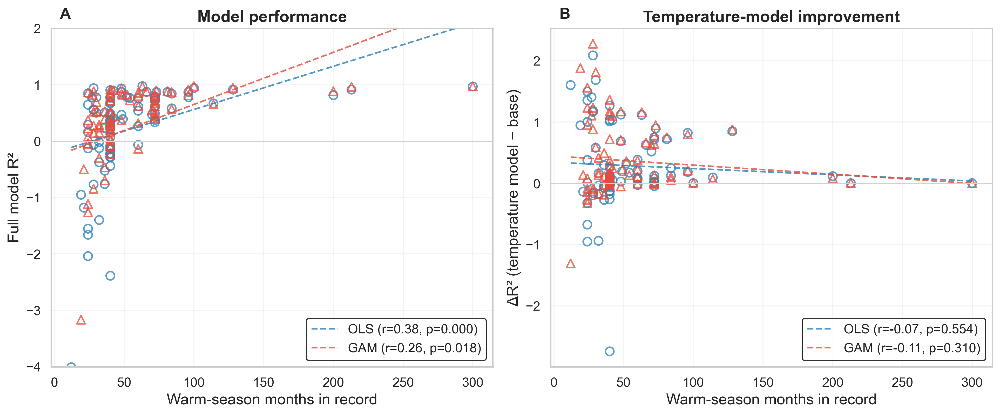

In [32]:
from scipy.stats import pearsonr

n_warm_months = (wdf.dropna(subset=['demand_gwh'])
                  .groupby('Country')['demand_gwh'].count()
                  .rename('n_warm_months').reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
FS = 14

panel_specs = [
    (('avg_R2_ols_cdd_eld', 'avg_R2_gam_temp_eld'), 'Full model R²',
     'Model performance', [-4, 2], 'A'),
    (('delta_R2_ols_cdd', 'delta_R2_gam_temp'), 'ΔR² (temperature model − base)',
     'Temperature-model improvement', None, 'B'),
]

for ax, (cols, ylabel, title, ylim, letter) in zip(axes, panel_specs):
    ols_col, gam_col = cols
    for col, marker, color, label in [
        (ols_col, 'o', '#2980b9', 'OLS'),
        (gam_col, '^', '#e74c3c', 'GAM'),
    ]:
        perf = res_combined[['Country', col]].merge(n_warm_months, on='Country').dropna()
        x, y = perf['n_warm_months'], perf[col]
        ax.scatter(x, y, marker=marker, s=60, alpha=0.75, facecolors='none',
                   edgecolors=color, linewidths=1.4)

        r, p = pearsonr(x, y)
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, linestyle='--', color=color,
                linewidth=1.5, alpha=0.8,
                label=f'{label} (r={r:.2f}, p={p:.3f})')

    ax.axhline(0, color='lightgray', linewidth=0.8)
    ax.set_xlabel('Warm-season months in record', fontsize=FS)
    ax.set_ylabel(ylabel, fontsize=FS)
    ax.set_title(title, fontsize=FS + 1)
    if ylim:
        ax.set_ylim(ylim)
    ax.tick_params(labelsize=FS - 2)
    ax.legend(fontsize=FS - 2, loc='lower right', frameon=True, edgecolor='black')
    ax.text(0.02, 1.02, letter, transform=ax.transAxes, fontsize=14, fontweight='bold', va='bottom')
    ax.grid(True)

plt.tight_layout()
plt.savefig(OUT_DIR + 'supplementary/perf_vs_recordlength.png', dpi=300, bbox_inches='tight')
plt.show()

In [33]:
# Significance: does record length predict the temperature-model improvement (ΔR², Panel B)?
from scipy.stats import pearsonr, spearmanr

for label, delta_col in [('OLS', 'delta_R2_ols_cdd'), ('GAM', 'delta_R2_gam_temp')]:
    df = res_combined[['Country', delta_col]].merge(n_warm_months, on='Country').dropna()
    r_p, p_p = pearsonr(df['n_warm_months'], df[delta_col])
    r_s, p_s = spearmanr(df['n_warm_months'], df[delta_col])
    print(f"{label}: Pearson r={r_p:.3f} (p={p_p:.4f}), Spearman r={r_s:.3f} (p={p_s:.4f}), n={len(df)}")

OLS: Pearson r=-0.065 (p=0.5540), Spearman r=0.062 (p=0.5718), n=85
GAM: Pearson r=-0.111 (p=0.3101), Spearman r=0.000 (p=0.9999), n=85


## Figure 5: change when adding CDD!

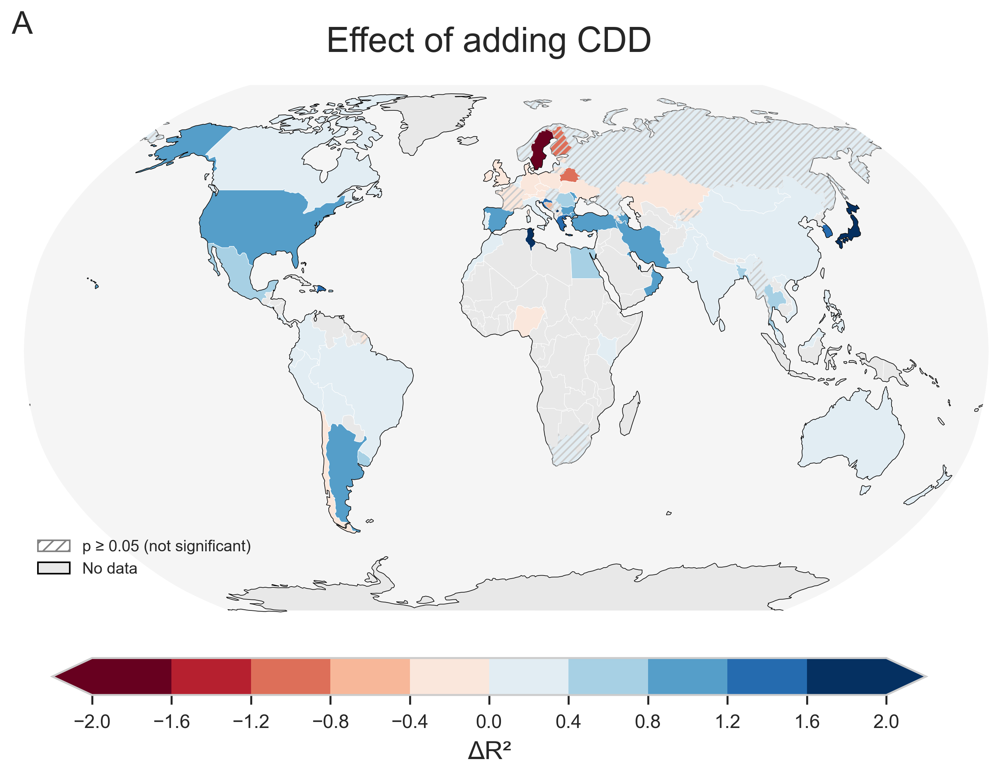

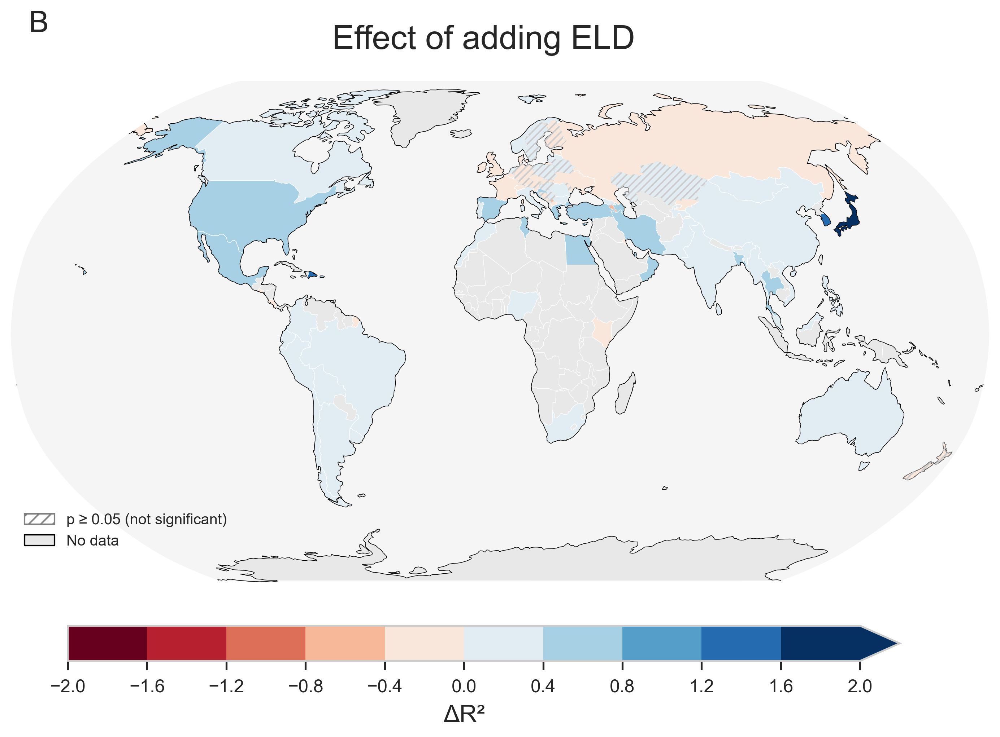

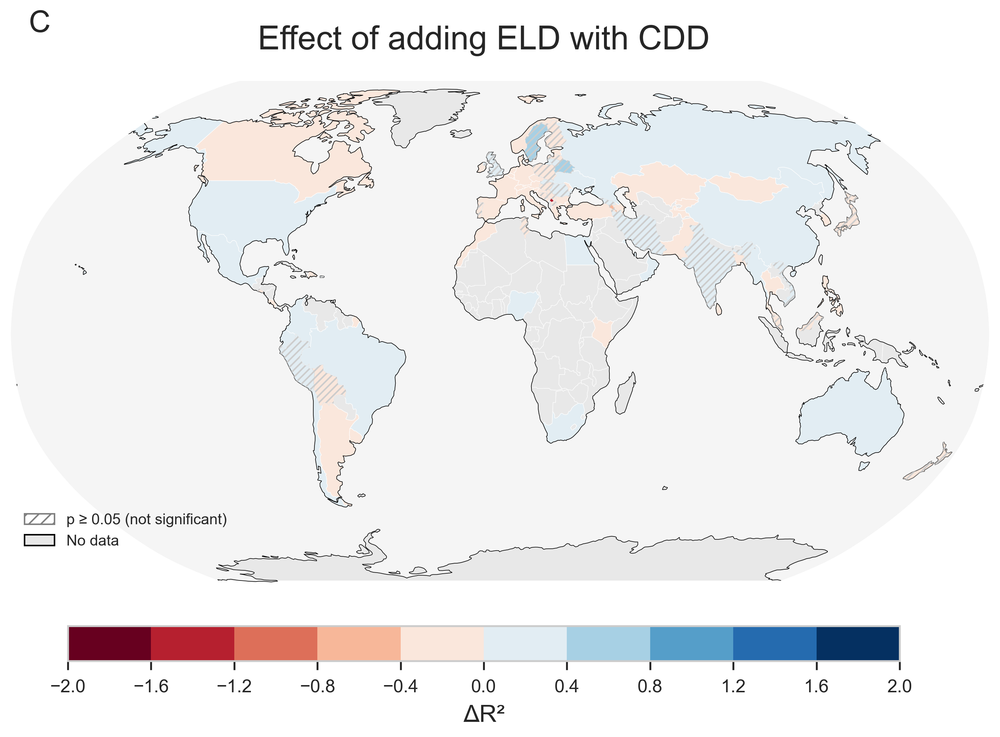

In [34]:
# FIGURE 5: EFFECT OF ADDING CDD / ELD TO OLS
# A) CDD added to OLS
deltaR2_OLS_map = gdf.merge(res_combined[['Country', 'delta_R2_ols_cdd', 'pval_ols_cdd']],
                    left_on='ADMIN', right_on='Country', how='left')

mapping_stuff(deltaR2_OLS_map, 'delta_R2_ols_cdd', 'RdBu', -2, 2, 'neither', 'Effect of adding CDD', 
              'ΔR²', 'deltaR2_OLS_cdd_map.png', pval_col='pval_ols_cdd', letter = 'A')

# B) ELD added to OLS
deltaR2_ELD_OLS_map = gdf.merge(res_combined[['Country', 'delta_R2_ols_eld', 'pval_ols_eld']],
                    left_on='ADMIN', right_on='Country', how='left')

mapping_stuff(deltaR2_ELD_OLS_map, 'delta_R2_ols_eld', 'RdBu', -2, 2, 'neither', 'Effect of adding ELD', 
              'ΔR²', 'deltaR2_OLS_eld_map_new.png', pval_col='pval_ols_eld', letter = 'B')

# C) ELD added to OLS w/ CDD
deltaR2_ELD_CDD_OLS_map = gdf.merge(res_combined[['Country', 'delta_R2_ols_eld_on_cdd', 'pval_ols_eld_on_cdd']],
                    left_on='ADMIN', right_on='Country', how='left')

mapping_stuff(deltaR2_ELD_CDD_OLS_map, 'delta_R2_ols_eld_on_cdd', 'RdBu', -2, 2, 'neither', 'Effect of adding ELD with CDD', 
              'ΔR²', 'deltaR2_OLS_cdd_eld_map_new.png', pval_col='pval_ols_eld_on_cdd', letter = 'C')


In [35]:
# TEXT SURROUNDING CHANGES
print('OLS greater than 0.6:', len(res_combined[res_combined['avg_R2_ols_cdd_eld']>0.6]))
print('GAM greater than 0.6:', len(res_combined[res_combined['avg_R2_gam_temp_eld']>0.6]))


# OLS
greater_than_03 = res_combined[res_combined['avg_R2_ols_cdd_eld']>0.3]
greater_than_03_cdd = greater_than_03[(greater_than_03['delta_R2_ols_cdd']>0) & (greater_than_03['pval_ols_cdd'] <0.05)]

print(
    f"\nFor the OLS models, there were {len(greater_than_03)} countries where the model R2 "
    f"was higher than 0.3 and adding CDD significantly improved performance in "
    f"{len(greater_than_03_cdd)} ({len(greater_than_03_cdd)/len(greater_than_03)*100:.1f}%) "
    f"of them, improving model R2 by an average of {greater_than_03_cdd['delta_R2_ols_cdd'].mean():.3f}"
)

# GAM
greater_than_03 = res_combined[res_combined['avg_R2_gam_temp_eld']>0.3]
greater_than_03_cdd = greater_than_03[(greater_than_03['delta_R2_gam_temp']>0) & (greater_than_03['pval_gam_temp'] <0.05)]

print(
    f"\nIn the GAM, there were {len(greater_than_03)} countries where the model R2 "
    f"was higher than 0.3, and adding temperature significantly improved performance in "
    f"{len(greater_than_03_cdd)} ({len(greater_than_03_cdd)/len(greater_than_03)*100:.1f}%) "
    f"of them, improving model R2 by an average of {greater_than_03_cdd['delta_R2_gam_temp'].mean():.3f}"
)

OLS greater than 0.6: 35
GAM greater than 0.6: 37

For the OLS models, there were 53 countries where the model R2 was higher than 0.3 and adding CDD significantly improved performance in 43 (81.1%) of them, improving model R2 by an average of 0.613

In the GAM, there were 56 countries where the model R2 was higher than 0.3, and adding temperature significantly improved performance in 45 (80.4%) of them, improving model R2 by an average of 0.604


## Figure S7

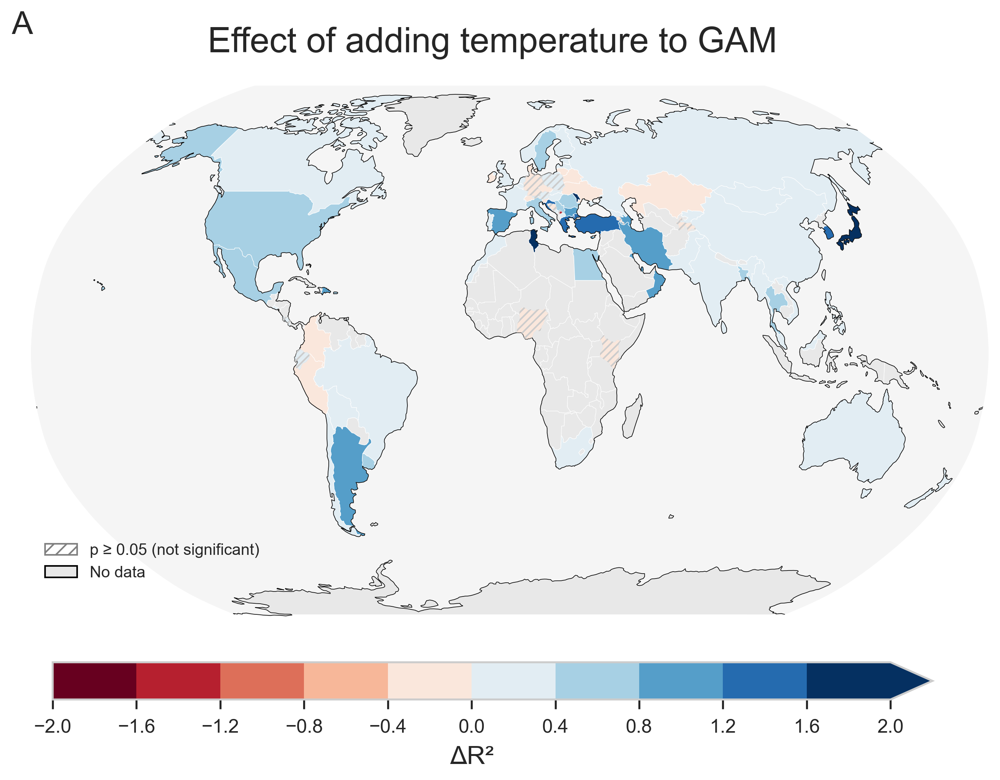

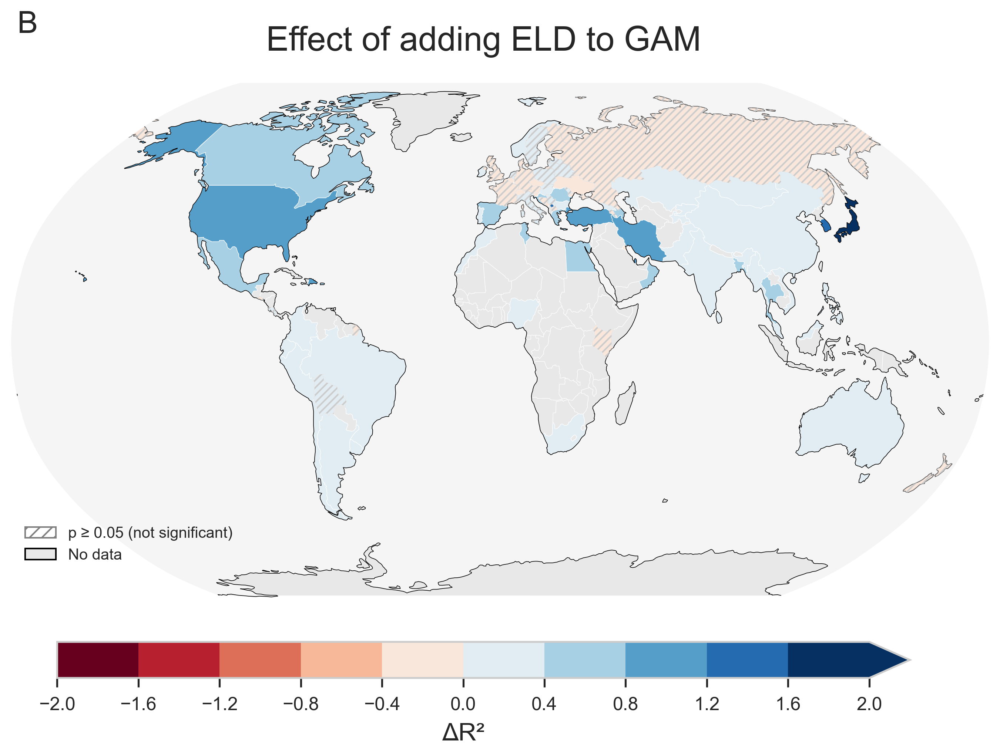

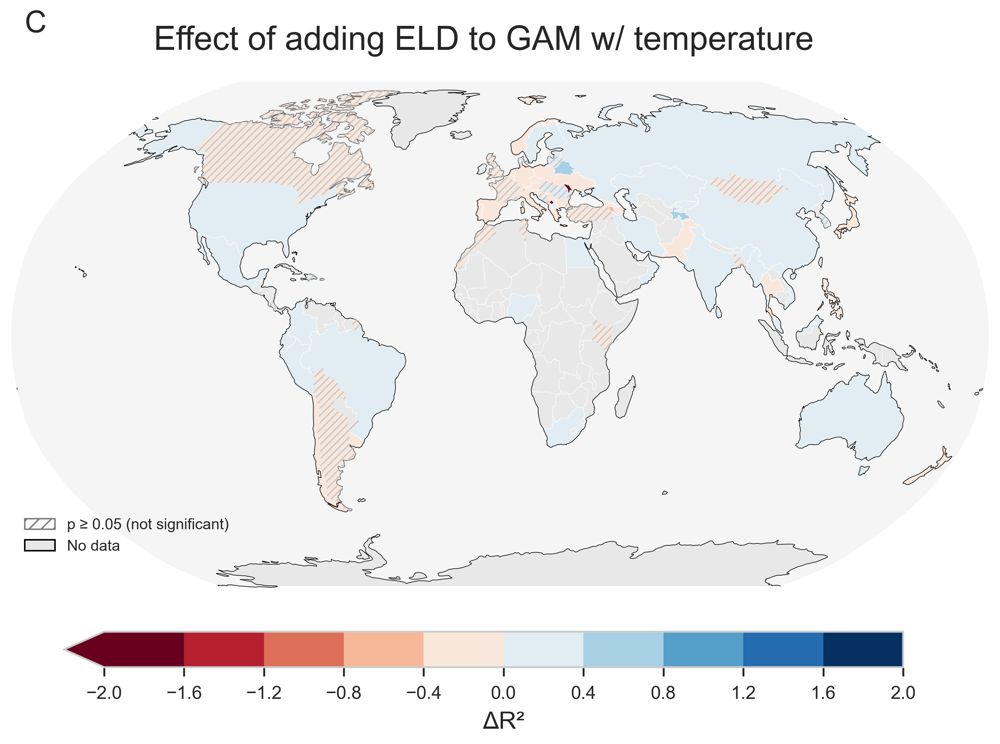

In [36]:
# SUPPLEMENTARY: EFFECT OF ADDING TEMP / ELD TO GAM
# A) Temperature added to GAM
deltaR2_GAM_map = gdf.merge(res_combined[['Country', 'delta_R2_gam_temp', 'pval_gam_temp']],
                    left_on='ADMIN', right_on='Country', how='left')

mapping_stuff(deltaR2_GAM_map, 'delta_R2_gam_temp', 'RdBu', -2, 2, 'neither', 'Effect of adding temperature to GAM', 
              'ΔR²', 'supplementary/deltaR2_GAM_temp_map.png', pval_col='pval_gam_temp', letter = 'A')

# B) ELD added to GAM
deltaR2_ELD_GAM_map = gdf.merge(res_combined[['Country', 'delta_R2_gam_eld', 'pval_gam_eld']],
                    left_on='ADMIN', right_on='Country', how='left')

mapping_stuff(deltaR2_ELD_GAM_map, 'delta_R2_gam_eld', 'RdBu', -2, 2, 'neither', 'Effect of adding ELD to GAM', 
              'ΔR²', 'supplementary/deltaR2_GAM_eld_map_new.png', pval_col='pval_gam_eld', letter = 'B')

# C) ELD added to GAM w/ temperature
deltaR2_temp_ELD_GAM_map = gdf.merge(res_combined[['Country', 'delta_R2_gam_eld_on_temp', 'pval_gam_eld_on_temp']],
                    left_on='ADMIN', right_on='Country', how='left')

mapping_stuff(deltaR2_temp_ELD_GAM_map, 'delta_R2_gam_eld_on_temp', 'RdBu', -2, 2, 'neither', 'Effect of adding ELD to GAM w/ temperature', 
              'ΔR²', 'supplementary/deltaR2_GAM_temp_eld_map_new.png', pval_col='pval_gam_eld_on_temp', letter = 'C')


In [37]:
# OLS
greater_than_03 = res_combined[res_combined['avg_R2_ols_cdd_eld']>0.3]
greater_than_03_eld = greater_than_03[(greater_than_03['delta_R2_ols_eld']>0) & (greater_than_03['pval_ols_eld'] <0.05)]
greater_than_03_eld_on_cdd = greater_than_03[(greater_than_03['delta_R2_ols_eld_on_cdd']>0) & (greater_than_03['pval_ols_eld_on_cdd'] <0.05)]

greater_than_03_gam = res_combined[res_combined['avg_R2_gam_temp_eld']>0.3]
greater_than_03_eld_gam = greater_than_03_gam[(greater_than_03_gam['delta_R2_gam_eld']>0) & (greater_than_03_gam['pval_gam_eld'] <0.05)]
greater_than_03_eld_on_cdd_gam = greater_than_03_gam[(greater_than_03_gam['delta_R2_gam_eld_on_temp']>0) & (greater_than_03_gam['pval_gam_eld_on_temp'] <0.05)]

print(f"When CDD or temperature was not in the base model, adding ELD improved performance in {len(greater_than_03_eld)} countries"
      f" for the OLS model and {len(greater_than_03_eld_gam)} countries for GAM. " 
      f"\nWhen CDD or temperature was already present in the model, adding ELD improved performance in {len(greater_than_03_eld_on_cdd)}"
      f" countries for the OLS model and {len(greater_than_03_eld_on_cdd_gam)} for the GAM,"
      f"\nthough the average improvement to R2 was only {greater_than_03_eld_on_cdd['delta_R2_ols_eld_on_cdd'].mean():.2f} and "
      f"{greater_than_03_eld_on_cdd_gam['delta_R2_gam_eld_on_temp'].mean():.2f}, respectively.")


When CDD or temperature was not in the base model, adding ELD improved performance in 42 countries for the OLS model and 43 countries for GAM. 
When CDD or temperature was already present in the model, adding ELD improved performance in 16 countries for the OLS model and 23 for the GAM,
though the average improvement to R2 was only 0.04 and 0.03, respectively.


## Figure 6: heatmaps!

In [38]:
INCOME_ORDER = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']
TEMP_BINS, TEMP_LABELS = [-10, 15, 20, 25, 50], ['Cold', 'Temperate', 'Warm', 'Hot']


def _income_pivot(results, df_income, col):
    """Mean of `col` by temperature class x income group."""
    df = (results[['Country', col, 'avg_temp', 'AC']]
          .merge(df_income[['Country', 'Income group']], on='Country', how='left').copy())
    df['temp_class'] = pd.cut(df['avg_temp'], bins=TEMP_BINS, labels=TEMP_LABELS)
    df['income_class'] = pd.Categorical(df['Income group'],
                                         categories=INCOME_ORDER, ordered=True)
    return df.pivot_table(index='temp_class', columns='income_class',
                          values=col, aggfunc='mean')


def _ac_pivot(results, col):
    """Mean of `col` by temperature class x AC adoption class."""
    df = results[['Country', col, 'avg_temp', 'AC']].copy()
    df['temp_class'] = pd.cut(df['avg_temp'], bins=TEMP_BINS, labels=TEMP_LABELS)
    df['AC_class'] = pd.cut(df['AC'], bins=[0, 30, 60, 100],
                             labels=['Low AC', 'Moderate AC', 'High AC'])
    return df.pivot_table(index='temp_class', columns='AC_class',
                          values=col, aggfunc='mean')


def _heatmap_figure(pivots, labels, letters, width_ratios, results_list, col,
                    cbar_label, filename, vmin=None, vmax=None):
    """Draw a row of heatmaps (one per pivot) with a shared colourbar."""
    n = len(pivots)
    fig, axes_grid = plt.subplots(
        1, n + 1, figsize=(6 * n + 1.5, 6),
        gridspec_kw={'width_ratios': list(width_ratios) + [0.4]}
    )
    axes = list(axes_grid[:n])
    cbar_ax = axes_grid[-1]
    cmap_hm = sns.color_palette('coolwarm', as_cmap=True)
    cmap_hm.set_bad('lightgray')
    if vmin is None or vmax is None:
        all_vals = pd.concat([r[[col]] for r in results_list], ignore_index=True)[col].dropna()
        if vmin is None: vmin = float(all_vals.quantile(0.02))
        if vmax is None: vmax = float(all_vals.quantile(0.98))
    for ax, pivot, label, letter in zip(axes, pivots, labels, letters):
        sns.heatmap(pivot, annot=True, fmt='.2f', cmap=cmap_hm, vmin=vmin, vmax=vmax,
                    linewidths=0.5, linecolor='white', cbar=False, ax=ax)
        ax.set_xlabel(''); ax.set_ylabel('')
        ax.set_title(label, fontsize=16, fontweight = 'normal')
        ax.text(-0.05, 1.08, letter, transform=ax.transAxes,
                fontsize=14, va='top')
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    sm = mpl.cm.ScalarMappable(cmap=cmap_hm, norm=norm)
    sm.set_array([])
    fig.colorbar(sm, cax=cbar_ax,
                 extend=colorbar_extend(np.concatenate([p.values.ravel() for p in pivots]), vmin, vmax))
    cbar_ax.set_ylabel(cbar_label, fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT_DIR + filename, dpi=300, bbox_inches='tight')
    plt.show()


def heatmap_panel(results_list, labels, df_income, col, cbar_label,
                  filename, vmin=None, vmax=None):
    """Income x temperature heatmap — works for any number of panels."""
    pivots = [_income_pivot(r, df_income, col) for r in results_list]
    _heatmap_figure(pivots, labels, 'ABCDEFGH', [7] * len(pivots), results_list, col,
                    cbar_label, filename, vmin, vmax)


def heatmap_ac_panel(results_list, labels, col, cbar_label, filename, vmin=None, vmax=None):
    """AC x temperature heatmap — works for any number of panels."""
    pivots = [_ac_pivot(r, col) for r in results_list]
    _heatmap_figure(pivots, labels, 'CDEFGH', [6] * len(pivots), results_list, col,
                    cbar_label, filename, vmin, vmax)


def heatmap_income_ac(rows, df_income, filename):
    """One row per entry in `rows`: income x temperature and AC x temperature side by side,
    each row with its own colourbar. Each row is a dict with keys: results, col, labels,
    cbar_label, and optionally vmin / vmax (default: symmetric about zero, from the
    2nd-98th percentile of that row)."""
    n = len(rows)
    fig, axes = plt.subplots(n, 3, figsize=(13.5, 6 * n), squeeze=False,
                             gridspec_kw={'width_ratios': [7, 6, 0.4]})
    cmap_hm = sns.color_palette('coolwarm', as_cmap=True)
    cmap_hm.set_bad('lightgray')
    letters = iter('ABCDEFGH')
    for r, row in enumerate(rows):
        results, col = row['results'], row['col']
        vmin, vmax = row.get('vmin'), row.get('vmax')
        if vmin is None or vmax is None:
            # Symmetric about zero so ΔR² = 0 is always the neutral colour
            vals = results[col].dropna()
            lim = float(max(abs(vals.quantile(0.02)), abs(vals.quantile(0.98))))
            vmin, vmax = -lim, lim
        pivots = [_income_pivot(results, df_income, col), _ac_pivot(results, col)]
        for ax, pivot, label in zip(axes[r, :2], pivots, row['labels']):
            sns.heatmap(pivot, annot=True, fmt='.2f', cmap=cmap_hm, vmin=vmin, vmax=vmax,
                        linewidths=0.5, linecolor='white', cbar=False, ax=ax)
            ax.set_xlabel(''); ax.set_ylabel('')
            ax.set_title(label, fontsize=16, fontweight = 'normal')
            ax.text(-0.05, 1.08, next(letters), transform=ax.transAxes,
                    fontsize=14, va='top')
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
        sm = mpl.cm.ScalarMappable(cmap=cmap_hm, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
        sm.set_array([])
        fig.colorbar(sm, cax=axes[r, 2],
                     extend=colorbar_extend(np.concatenate([p.values.ravel() for p in pivots]), vmin, vmax))
        axes[r, 2].set_ylabel(row['cbar_label'], fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT_DIR + filename, dpi=300, bbox_inches='tight')
    plt.show()


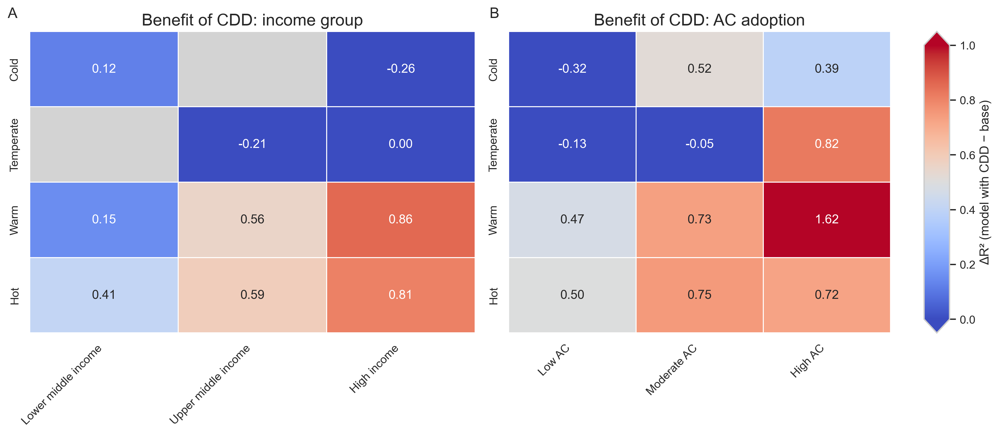

In [39]:
# Per-model views with a unified column name
def _hm_view(col):
    return (res_combined[['Country', col, 'avg_temp', 'AC']]
            .rename(columns={col: 'delta_R2'}))

rc_ols = _hm_view('delta_R2_ols_cdd')
rc_ols_eld = _hm_view('delta_R2_ols_eld_on_cdd')
rc_gam = _hm_view('delta_R2_gam_temp')
rc_gam_eld = _hm_view('delta_R2_gam_eld_on_temp')

# Figure 6: benefit of adding CDD to OLS, by (A) income group and (B) AC adoption
heatmap_income_ac([
    dict(results=rc_ols, col='delta_R2', vmin=0, vmax=1,
         labels=['Benefit of CDD: income group', 'Benefit of CDD: AC adoption'],
         cbar_label='ΔR² (model with CDD − base)'),
], df_income, filename='heatmap_income_AC_temp_OLS.png')


## Figure S8

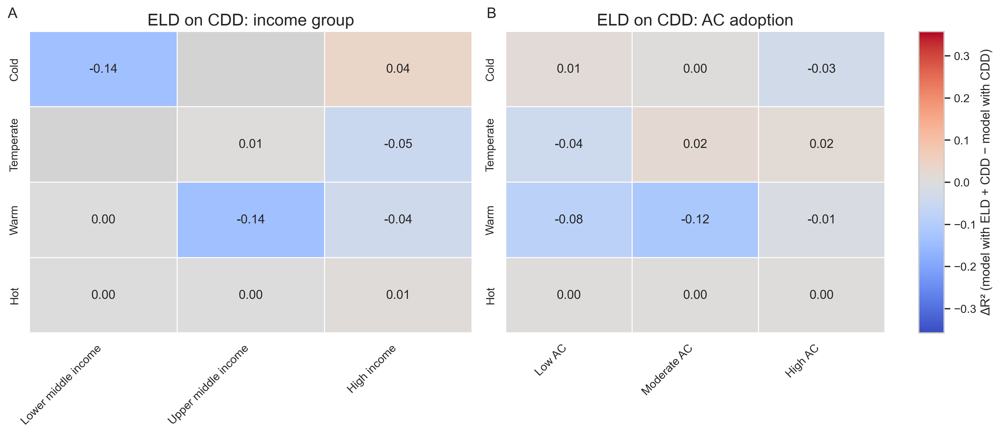

In [40]:
# Supplementary: benefit of adding ELD to OLS w/ CDD, by (A) income group and (B) AC adoption
heatmap_income_ac([
    dict(results=rc_ols_eld, col='delta_R2',
         labels=['ELD on CDD: income group', 'ELD on CDD: AC adoption'],
         cbar_label='ΔR² (model with ELD + CDD − model with CDD)'),
], df_income, filename='supplementary/heatmap_income_AC_temp_eld_OLS.png')


## Figure S9: GAM heatmaps


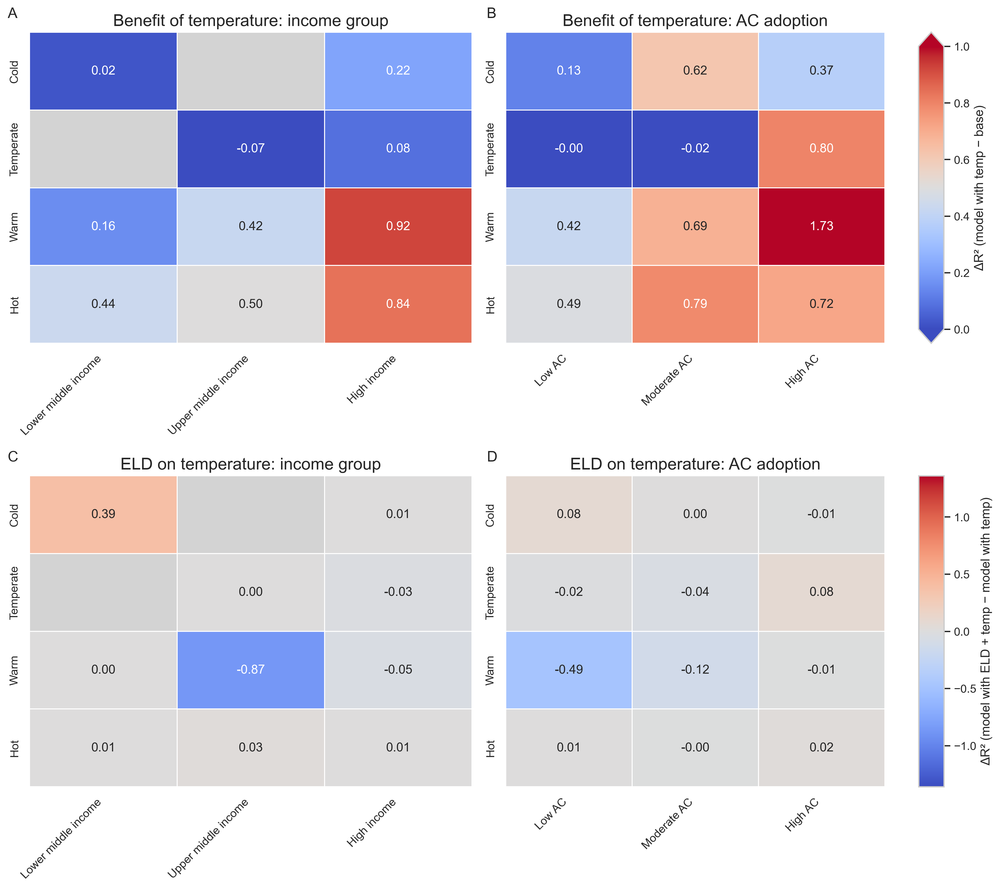

In [41]:
# Supplementary: GAM -- (A, B) benefit of adding temperature; (C, D) benefit of adding ELD w/ temperature
heatmap_income_ac([
    dict(results=rc_gam, col='delta_R2', vmin=0, vmax=1,
         labels=['Benefit of temperature: income group', 'Benefit of temperature: AC adoption'],
         cbar_label='ΔR² (model with temp − base)'),
    dict(results=rc_gam_eld, col='delta_R2',
         labels=['ELD on temperature: income group', 'ELD on temperature: AC adoption'],
         cbar_label='ΔR² (model with ELD + temp − model with temp)'),
], df_income, filename='supplementary/heatmap_income_AC_temp_GAM.png')


## Table S2: Second-stage regression

In [42]:
import statsmodels.api as sm

# Second-stage regression: ΔR²_climate ~ avg_temp + avg_ELD + gdp_capita + AC
for label, savename, delta_col in [('Enhanced OLS (CDD + CDD²)', 'OLS', 'delta_R2_ols_cdd'),
                           ('GAM-temp', 'GAM', 'delta_R2_gam_temp')]:
    df = res_combined[['Country', delta_col, 'avg_temp', 'gdp_capita', 'AC']].dropna()
    df = df.rename(columns={delta_col: 'delta_R2'})
    for col in ['avg_temp', 'gdp_capita', 'AC']:
        df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()
    X = sm.add_constant(df[['avg_temp_z', 'gdp_capita_z', 'AC_z']])
    model = sm.OLS(df['delta_R2'], X).fit()
    print(f"\n{'='*60}")
    print(f"{label}")
    print(f"{'='*60}")
    print(model.summary().tables[1])
    pd.DataFrame(model.summary().tables[1].data[1:], 
             columns=model.summary().tables[1].data[0]).to_csv(
    OUT_DIR_FILES + f'second_regression_{savename}_noELD.csv', index=False)


Enhanced OLS (CDD + CDD²)
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.2857      0.062      4.645      0.000       0.163       0.408
avg_temp_z       0.2282      0.070      3.239      0.002       0.088       0.368
gdp_capita_z    -0.0771      0.072     -1.074      0.286      -0.220       0.066
AC_z             0.2256      0.067      3.354      0.001       0.092       0.359

GAM-temp
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.3634      0.054      6.671      0.000       0.255       0.472
avg_temp_z       0.1598      0.062      2.561      0.012       0.036       0.284
gdp_capita_z    -0.0007      0.064     -0.010      0.992      -0.127       0.126
AC_z             0.2033      0.060      3.413      0.001       0.085    

In [43]:
import statsmodels.api as sm

# same but with eld!

# Second-stage regression: ΔR²_climate ~ avg_temp + avg_ELD + gdp_capita + AC
for label, savename, delta_col in [('Enhanced OLS (CDD + CDD²)', 'OLS', 'delta_R2_ols_cdd'),
                           ('GAM-temp', 'GAM', 'delta_R2_gam_temp')]:
    df = res_combined[['Country', delta_col, 'avg_temp', 'avg_ELD', 'gdp_capita', 'AC']].dropna()
    df = df.rename(columns={delta_col: 'delta_R2'})
    for col in ['avg_temp', 'avg_ELD', 'gdp_capita', 'AC']:
        df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()
    X = sm.add_constant(df[['avg_temp_z', 'avg_ELD_z', 'gdp_capita_z', 'AC_z']])
    model = sm.OLS(df['delta_R2'], X).fit()
    print(f"\n{'='*60}")
    print(f"{label}")
    print(f"{'='*60}")
    print(model.summary().tables[1])
    pd.DataFrame(model.summary().tables[1].data[1:], 
             columns=model.summary().tables[1].data[0]).to_csv(
    OUT_DIR_FILES + f'second_regression_{savename}.csv', index=False)


Enhanced OLS (CDD + CDD²)
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.2857      0.062      4.638      0.000       0.163       0.408
avg_temp_z       0.2745      0.088      3.120      0.003       0.099       0.450
avg_ELD_z       -0.0730      0.083     -0.880      0.381      -0.238       0.092
gdp_capita_z    -0.0830      0.072     -1.150      0.254      -0.227       0.061
AC_z             0.2219      0.067      3.287      0.002       0.088       0.356

GAM-temp
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.3634      0.054      6.704      0.000       0.256       0.471
avg_temp_z       0.2217      0.077      2.863      0.005       0.068       0.376
avg_ELD_z       -0.0976      0.073     -1.338      0.185      -0.243    

In [44]:
# Same regression, HC3 robust standard errors — checks whether n_warm_months
# significance survives once heteroscedasticity is accounted for (short-record
# countries have noisier ΔR² estimates from CV on small test sets, which can
# distort OLS standard errors and inflate apparent significance).
for label, delta_col in [('Enhanced OLS (CDD + CDD²)', 'delta_R2_ols_cdd'),
                          ('GAM-temp', 'delta_R2_gam_temp')]:
    df = (res_combined[['Country', delta_col, 'avg_temp', 'avg_ELD', 'gdp_capita', 'AC']]
          .merge(n_warm_months, on='Country')
          .dropna())
    df = df.rename(columns={delta_col: 'delta_R2'})
    for col in ['avg_temp', 'avg_ELD', 'gdp_capita', 'AC', 'n_warm_months']:
        df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()
    X = sm.add_constant(df[['avg_temp_z', 'avg_ELD_z', 'gdp_capita_z', 'AC_z', 'n_warm_months_z']])
    model = sm.OLS(df['delta_R2'], X).fit(cov_type='HC3')
    print(f"\n{'='*60}")
    print(f"{label} (+ record length, HC3 robust SE)")
    print(f"{'='*60}")
    print(model.summary().tables[1])


Enhanced OLS (CDD + CDD²) (+ record length, HC3 robust SE)
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.2857      0.062      4.575      0.000       0.163       0.408
avg_temp_z          0.2896      0.094      3.066      0.002       0.104       0.475
avg_ELD_z          -0.0142      0.081     -0.175      0.861      -0.173       0.145
gdp_capita_z       -0.0731      0.058     -1.256      0.209      -0.187       0.041
AC_z                0.2246      0.069      3.265      0.001       0.090       0.359
n_warm_months_z    -0.1542      0.091     -1.694      0.090      -0.333       0.024

GAM-temp (+ record length, HC3 robust SE)
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.3634      0.055      6.549      0.0

## Second-stage regression (ELD)

In [45]:
# Second-stage regression: delta R2_ELD ~ avg_temp + avg_ELD + gdp_capita + AC
for label, savename, delta_col in [('Enhanced OLS (ELD)', 'OLS_ELD', 'delta_R2_ols_eld'),
                           ('GAM-ELD', 'GAM_ELD', 'delta_R2_gam_eld')]:
    df = res_combined[['Country', delta_col, 'avg_temp', 'avg_ELD', 'gdp_capita', 'AC']].dropna()
    df = df.rename(columns={delta_col: 'delta_R2'})
    for col in ['avg_temp', 'avg_ELD', 'gdp_capita', 'AC']:
        df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()
    X = sm.add_constant(df[['avg_temp_z', 'avg_ELD_z', 'gdp_capita_z', 'AC_z']])
    model = sm.OLS(df['delta_R2'], X).fit()
    print(f"\n{'='*60}")
    print(f"{label}")
    print(f"{'='*60}")
    print(model.summary().tables[1])
    pd.DataFrame(model.summary().tables[1].data[1:],
             columns=model.summary().tables[1].data[0]).to_csv(
    OUT_DIR_FILES + f'second_regression_{savename}.csv', index=False)


Enhanced OLS (ELD)
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.1995      0.037      5.439      0.000       0.127       0.273
avg_temp_z       0.0550      0.052      1.050      0.297      -0.049       0.159
avg_ELD_z        0.0721      0.049      1.461      0.148      -0.026       0.170
gdp_capita_z     0.0021      0.043      0.048      0.962      -0.083       0.088
AC_z             0.1724      0.040      4.289      0.000       0.092       0.252

GAM-ELD
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.2456      0.039      6.232      0.000       0.167       0.324
avg_temp_z       0.0543      0.056      0.965      0.338      -0.058       0.166
avg_ELD_z        0.0375      0.053      0.707      0.482      -0.068       0.143

## Dataset S3: Per-country model performance summary 

In [46]:
# Supplementary Table S4: per-country model performance summary
def fmt_r2(val, pval, dp=3):
    """Format a delta-R² value; append * when improvement is not significant (p≥0.05)."""
    if pd.isna(val):
        return ''
    s = f'{val:.{dp}f}'
    if pd.isna(pval) or pval >= 0.05:
        s += '*'
    return s

cols_needed = [
    'Country',
    'avg_R2_ols_cdd_eld',
    'delta_R2_ols_cdd', 'pval_ols_cdd',
    'delta_R2_ols_eld', 'pval_ols_eld',
    'delta_R2_ols_eld_on_cdd','pval_ols_eld_on_cdd',
    'avg_R2_gam_temp_eld',
    'delta_R2_gam_temp', 'pval_gam_temp',
    'delta_R2_gam_eld', 'pval_gam_eld',
    'delta_R2_gam_eld_on_temp','pval_gam_eld_on_temp',
    'avg_temp', 'AC',
]

tbl = (res_combined[cols_needed]
       .merge(df_income[['Country', 'Income group']], on='Country', how='left')
       .copy())

tbl['Temperature class'] = pd.cut(tbl['avg_temp'], bins=[-10, 15, 20, 25, 50],
                                    labels=['Cold', 'Temperate', 'Warm', 'Hot'])
tbl['AC class'] = pd.cut(tbl['AC'], bins=[0, 30, 60, 100],
                            labels=['Low AC', 'Moderate AC', 'High AC'])

out = pd.DataFrame()
out['Country'] = tbl['Country']
out['OLS - R2'] = tbl['avg_R2_ols_cdd_eld'].round(3)
out['OLS - dR2 (CDD)'] = tbl.apply(lambda r: fmt_r2(r['delta_R2_ols_cdd'], r['pval_ols_cdd']), axis=1)
out['OLS - dR2 (ELD)'] = tbl.apply(lambda r: fmt_r2(r['delta_R2_ols_eld'], r['pval_ols_eld']), axis=1)
out['OLS - dR2 (ELD on CDD)'] = tbl.apply(lambda r: fmt_r2(r['delta_R2_ols_eld_on_cdd'], r['pval_ols_eld_on_cdd']), axis=1)
out['GAM - R2'] = tbl['avg_R2_gam_temp_eld'].round(3)
out['GAM - dR2 (temp)'] = tbl.apply(lambda r: fmt_r2(r['delta_R2_gam_temp'], r['pval_gam_temp']), axis=1)
out['GAM - dR2 (ELD)'] = tbl.apply(lambda r: fmt_r2(r['delta_R2_gam_eld'], r['pval_gam_eld']), axis=1)
out['GAM - dR2 (ELD on temp)'] = tbl.apply(lambda r: fmt_r2(r['delta_R2_gam_eld_on_temp'], r['pval_gam_eld_on_temp']), axis=1)
out['Income group'] = tbl['Income group']
out['Temperature class'] = tbl['Temperature class'].astype(str)
out['AC class'] = tbl['AC class'].astype(str)

out = out.sort_values(['Income group', 'Country']).reset_index(drop=True)

outpath = OUT_DIR_FILES + 'model_performance_summary.csv'
out.to_csv(outpath, index=False)
print(f'Saved {len(out)} rows to {outpath}')
print('  * = improvement not significant at p>=0.05')
out

Saved 85 rows to /Users/charlottecockburn/Documents/Columbia/AC_project/Tables/model_performance_summary.csv
  * = improvement not significant at p>=0.05


,Country,OLS - R2,OLS - dR2 (CDD),OLS - dR2 (ELD),OLS - dR2 (ELD on CDD),GAM - R2,GAM - dR2 (temp),GAM - dR2 (ELD),GAM - dR2 (ELD on temp),Income group,Temperature class,AC class
0,Australia,0.815,0.116,0.061,0.003,0.885,0.084,0.080,0.015,High income,Hot,High AC
1,Austria,-0.286,-0.135,-0.055*,-0.093,-0.100,0.055*,-0.048*,-0.076,High income,Temperate,Low AC
2,Belgium,0.378,0.115,-0.015,-0.025,0.280,0.120,-0.079,-0.105,High income,Temperate,Low AC
3,Bulgaria,0.491,1.032,0.266,-0.048,0.527,1.118,0.225,-0.039,High income,Warm,Low AC
4,Canada,0.266,0.387,0.369,-0.033,0.316,0.373,0.412,-0.007*,High income,Cold,High AC
...,...,...,...,...,...,...,...,...,...,...,...,...
80,Republic of Serbia,-0.017,0.161*,0.027*,-0.027*,0.149,0.414,0.047*,-0.063,Upper middle income,Warm,Low AC
81,South Africa,0.411,0.050*,0.267,0.153,0.447,0.243,0.327,0.056,Upper middle income,Warm,Low AC
82,Thailand,0.717,0.711,0.407,-0.011,0.675,0.644,0.429,-0.022,Upper middle income,Hot,Low AC
83,Turkey,0.562,1.183,0.769,-0.053,0.524,1.232,0.800,-0.046*,Upper middle income,Warm,Low AC


## Figure S10: Partial dependence — all drivers by income group

In [47]:
income_colors = {
    'Lower middle income': '#e67e22',
    'Upper middle income': '#3498db',
    'High income': '#2ecc71',
}
countries_by_income = (
    wdf[['Country', 'Income group']].drop_duplicates()
    .dropna(subset=['Income group'])
    .groupby('Income group')['Country'].apply(list).to_dict()
)


In [48]:
# Setup: fit GAM(GDP + Population + avg_temp + avg_ELD) per income group
_gam_eld_r2 = res_combined.set_index('Country')['avg_R2_gam_temp_eld'].to_dict()

def pool_and_fit_gam_eld(countries, r2_min=0.0):
    """Pool countries and fit GAM(GDP+Pop+Temp+ELD); return (fitted_gam, included)."""
    pool, included = [], []
    for c in countries:
        if _gam_eld_r2.get(c, -np.inf) < r2_min:
            continue
        df_c = wdf[wdf['Country'] == c][GAM_TEMP_ELD + [TARGET]].dropna()
        if len(df_c) < MIN_SAMPLES:
            continue
        y_mean = df_c[TARGET].mean()
        if y_mean <= 0:
            continue
        df_n = df_c.copy()
        df_n[TARGET] = df_n[TARGET] / y_mean
        pool.append(df_n)
        included.append(c)
    if not pool:
        return None, []
    pooled = pd.concat(pool, ignore_index=True)
    gam = LinearGAM(
        s(0, n_splines=6) + s(1, n_splines=6) + s(2, n_splines=6) + s(3, n_splines=6)
    ).fit(pooled[GAM_TEMP_ELD].values, pooled[TARGET].values)
    return gam, included

print("Income groups (countries with GAM-ELD R² > 0):")
income_groups = ["Lower middle income", "Upper middle income", "High income"]

for g in income_groups:
    ctries = countries_by_income.get(g, [])
    n_pass = sum(1 for c in ctries if _gam_eld_r2.get(c, -1) >= 0)
    print(f"  {g}: {len(ctries)} total, {n_pass} pass R² filter")

Income groups (countries with GAM-ELD R² > 0):
  Lower middle income: 15 total, 13 pass R² filter
  Upper middle income: 27 total, 21 pass R² filter
  High income: 43 total, 36 pass R² filter


### Aggregate of per-country PDPs, by income group

Comparison with the pooled-model PDP above. Instead of pooling all countries' normalized data and fitting one GAM per income group, here we fit a separate GAM(GDP, Population, avg_temp, avg_ELD) **per country** (on that country's own normalized data), compute each country's partial-dependence curve for avg_temp and avg_ELD on a common grid, and then show the across-country mean ± SE alongside the individual country curves (thin lines). This isolates the *within-country* shape of the response, which is what the per-country CV R² results (showing ELD adds little) actually speak to.

In [49]:
# Fit one GAM(GDP+Pop+avg_temp+avg_ELD) per country (own normalized data)
def fit_country_gam_eld(country, n_splines=6):
    """Fit GAM(GDP+Pop+avg_temp+avg_ELD) on a single country's own data,
    normalized to mean=1. Returns (gam, df_n) or None if too little data."""
    df_c = wdf[wdf['Country'] == country][GAM_TEMP_ELD + [TARGET]].dropna()
    if len(df_c) < MIN_SAMPLES:
        return None
    y_mean = df_c[TARGET].mean()
    if y_mean <= 0:
        return None
    df_n = df_c.copy()
    df_n[TARGET] = df_n[TARGET] / y_mean
    gam = LinearGAM(
        s(0, n_splines=n_splines) + s(1, n_splines=n_splines) +
        s(2, n_splines=n_splines) + s(3, n_splines=n_splines)
    ).fit(df_n[GAM_TEMP_ELD].values, df_n[TARGET].values)
    return gam, df_n

_all_countries = wdf['Country'].dropna().unique()
country_gams = {}
for c in _all_countries:
    fit = fit_country_gam_eld(c)
    if fit is not None:
        country_gams[c] = fit

print(f"Fitted per-country GAMs for {len(country_gams)} / {len(_all_countries)} countries")


Fitted per-country GAMs for 85 / 85 countries


## Figure S10

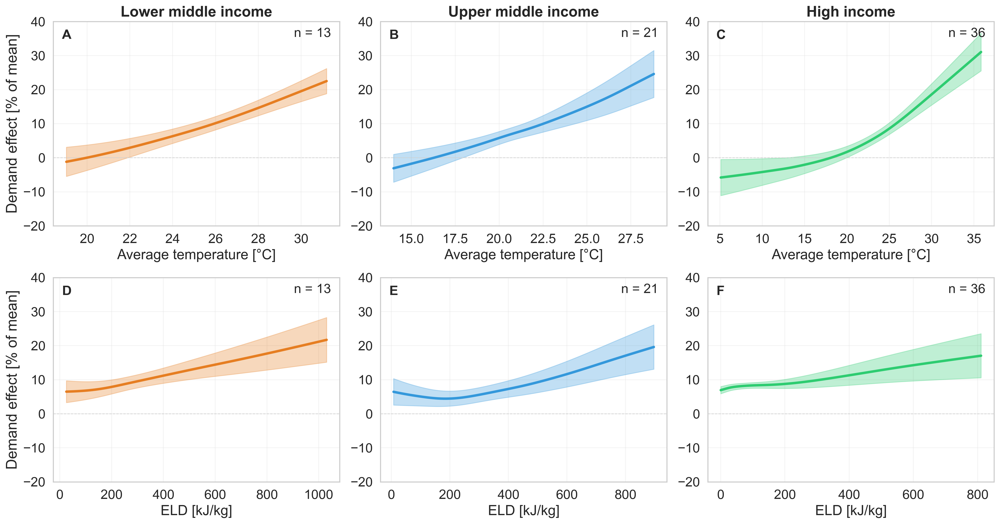

In [50]:
# Aggregate (spaghetti + mean ± SE) of per-country PDPs, by income group
pdp_terms = [
    (2, 'avg_temp', 'Average temperature [\u00b0C]'),
    (3, 'avg_ELD', 'ELD [kJ/kg]'),
]
N_GRID = 100

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
FS = 18

for row, (term_idx, var_col, xlabel) in enumerate(pdp_terms):
    for col_idx, grp in enumerate(income_groups):
        ax = axes[row, col_idx]
        color = income_colors[grp]

        ctries = [c for c in countries_by_income.get(grp, [])
                  if c in country_gams and _gam_eld_r2.get(c, -np.inf) >= 0]

        if not ctries:
            ax.set_visible(False)
            continue

        # Common grid: 2nd-98th percentile of this variable across the group's countries
        vals = wdf[wdf['Country'].isin(ctries)][var_col].dropna()
        lo, hi = vals.quantile(0.02), vals.quantile(0.98)
        grid = np.linspace(lo, hi, N_GRID)

        curves = []
        for c in ctries:
            gam, df_n = country_gams[c]
            X = np.zeros((N_GRID, len(GAM_TEMP_ELD)))
            X[:, term_idx] = grid
            pdp, _ = gam.partial_dependence(term=term_idx, X=X, width=0.95)
            curves.append(pdp * 100)

        curves = np.array(curves)
        mean_curve = curves.mean(axis=0)
        se_curve = curves.std(axis=0) / np.sqrt(len(curves))

        # Individual country curves (thin lines) behind the mean
        # for c_curve in curves:
        #     ax.plot(grid, c_curve, color=color, linewidth=0.8, alpha=0.3, zorder=1)

        ax.plot(grid, mean_curve, color=color, linewidth=3, zorder=3)
        ax.fill_between(grid, mean_curve - se_curve, mean_curve + se_curve,
                         color=color, alpha=0.3, zorder=2)
        ax.axhline(0, color='lightgray', linewidth=0.8, linestyle='--')
        ax.set_xlabel(xlabel, fontsize=FS - 1)
        if col_idx == 0:
            ax.set_ylabel('Demand effect [% of mean]', fontsize=18)
        if row == 0:
            ax.set_title(grp, fontsize=FS)
        panel_letter = chr(65 + row * 3 + col_idx)
        ax.text(0.03, 0.96, panel_letter, transform=ax.transAxes,
                fontsize=16, fontweight='bold', va='top')
        ax.tick_params(labelsize=FS - 2)
        ax.text(0.97, 0.97, f'n = {len(ctries)}', transform=ax.transAxes,
                ha='right', va='top', fontsize=FS - 2)
        ax.set_ylim([-20, 40])
        ax.grid(True)
plt.tight_layout()
plt.savefig(OUT_DIR + 'supplementary/pdp_drivers_by_income_aggregate.png', dpi=300, bbox_inches='tight')
plt.show()


### Per-country PDP figures (saved)

Saves each country's temperature and ELD partial-dependence plots (from its own GAM, fit above) to `Figures/country_pdps/`, for inspection.

In [51]:
# Save each country's temp/ELD PDP to Figures/country_pdps/ (not displayed)
country_pdp_dir = OUT_DIR + 'country_pdps/'
os.makedirs(country_pdp_dir, exist_ok=True)

for country, (gam, df_n) in country_gams.items():
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    for ax, (term_idx, var_col, xlabel) in zip(axes, pdp_terms):
        XX = gam.generate_X_grid(term=term_idx)
        pdp, conf = gam.partial_dependence(term=term_idx, X=XX, width=0.95)
        ax.plot(XX[:, term_idx], pdp * 100, color='#2980b9', linewidth=2)
        ax.fill_between(XX[:, term_idx], conf[:, 0] * 100, conf[:, 1] * 100,
                         color='#2980b9', alpha=0.2)
        ax.axhline(0, color='lightgray', linewidth=0.8, linestyle='--')
        ax.set_xlabel(xlabel)
        ax.set_ylabel('Demand effect [% of mean]')
        ax.grid(True, alpha=0.2)
    fig.suptitle(f"{country}  (n={len(df_n)})")
    plt.tight_layout()
    safe_name = country.replace('/', '-')
    plt.savefig(country_pdp_dir + f'{safe_name}_pdp.png', dpi=150, bbox_inches='tight')
    plt.close(fig)

print(f"Saved {len(country_gams)} per-country PDP figures to {country_pdp_dir}")


Saved 85 per-country PDP figures to /Users/charlottecockburn/Documents/Columbia/AC_project/Figures/country_pdps/


# PART 3: Daily case studies!

In [52]:
# Load daily US / UK data and build warm-season subsets
df_usa_d = pd.read_csv(DATA_DIR + 'Subnational_Electricity/US_data_fewerBAs/USA_daily.csv', parse_dates=['Date'])
df_uk_d = pd.read_csv(DATA_DIR + 'UK_data_daily.csv', parse_dates=['Date'])
df_uk_d['Sector'] = 'United Kingdom' # national series, no subregions

for df in [df_usa_d, df_uk_d]:
    df['Month'] = df['Date'].dt.month

WARM = {6, 7, 8, 9}
usa_w = df_usa_d[df_usa_d['Month'].isin(WARM)].copy()
uk_w = df_uk_d[df_uk_d['Month'].isin(WARM)].copy()

print(f"USA warm-season daily: {len(usa_w):,} obs across {usa_w['Sector'].nunique()} sectors")
print(f"UK  warm-season daily: {len(uk_w):,} obs")


USA warm-season daily: 5,725 obs across 8 sectors
UK  warm-season daily: 732 obs


In [53]:
# Region areas (km2), for normalizing ELD by area
import geopandas as gpd

SHAPE_DIR = '/Users/charlottecockburn/Documents/Columbia/AC_project/Data/Shapefiles/'

ba = gpd.read_file(SHAPE_DIR + 'Balancing_Authorities/Balancing_Authorities.shp')
ba = ba[ba['EIAcode'].isin(usa_w['Sector'].unique())].to_crs('EPSG:6933')
ba['area_km2'] = ba.geometry.area / 1e6
ba_areas = ba.groupby('EIAcode')['area_km2'].sum()

countries = gpd.read_file(SHAPE_DIR + 'natural_earth_shapefiles/ne_110m_admin_0_countries.shp')
uk_area = (countries[countries['NAME'] == 'United Kingdom']
           .to_crs('EPSG:6933').geometry.area.sum() / 1e6)

area_km2 = ba_areas.to_dict()
area_km2['United Kingdom'] = uk_area

print("Region areas (km\u00b2):")
for k, v in area_km2.items():
    print(f"  {k:20s} {v:,.0f}")

# ELD is a spatial sum over each region's grid cells, so divide by area to get an area-normalized "ELD density" for cross-region comparison.
usa_w['ELD_density'] = usa_w['ELD'] / usa_w['Sector'].map(area_km2)
uk_w['ELD_density'] = uk_w['ELD'] / uk_w['Sector'].map(area_km2)


Region areas (km²):
  CISO                 356,973
  ERCO                 508,355
  ISNE                 172,112
  MISO                 1,679,394
  NYIS                 128,022
  PJM                  602,938
  PNM                  252,467
  SWPP                 1,471,861
  United Kingdom       249,930


## Figure S11: US balancing authorities used in the daily analysis

Map of the 8 US balancing-authority (BA) footprints used in the daily USA/UK ELD comparison above (Figure 11 and the ELD-benefit table), labeled by EIA code. Other US BAs are shown in gray for context.

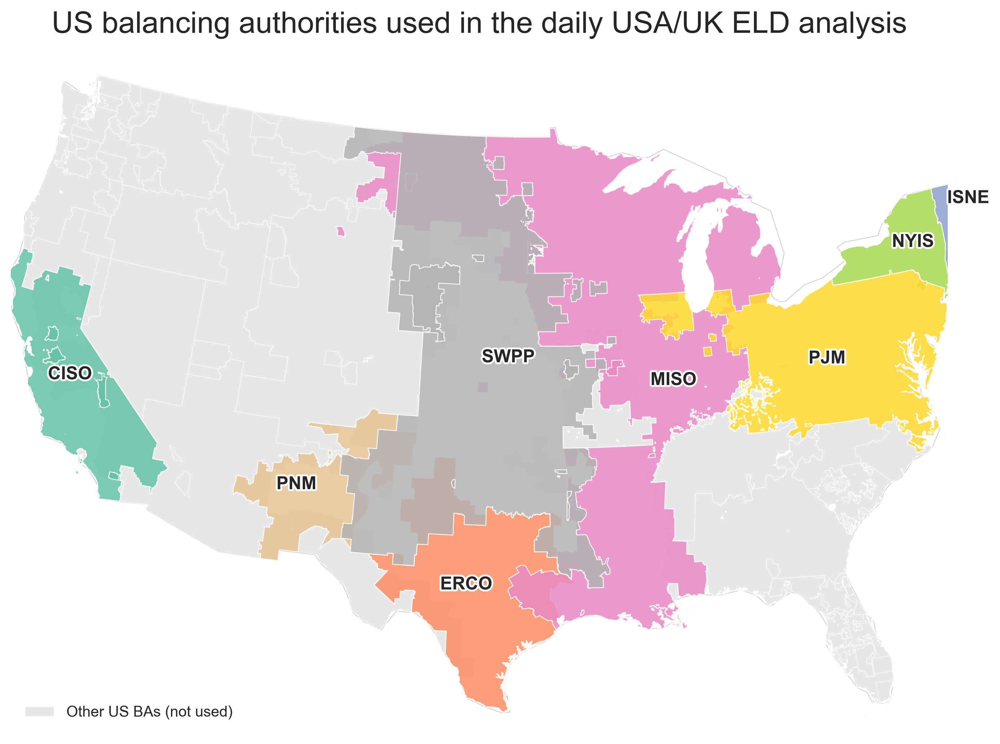

In [54]:
# Map: US balancing authorities used in the daily analysis
ALBERS = 'EPSG:5070' # NAD83 / Conus Albers

ba_all = gpd.read_file(SHAPE_DIR + 'Balancing_Authorities/Balancing_Authorities.shp').to_crs('EPSG:4326')

ba_codes = list(usa_w['Sector'].unique())
ba_used = ba_all[ba_all['EIAcode'].isin(ba_codes)].to_crs(ALBERS)
ba_other = ba_all[~ba_all['EIAcode'].isin(ba_codes)].cx[-125:-66, 24:50].to_crs(ALBERS)

us_land = countries[countries['NAME'] == 'United States of America'].to_crs(ALBERS)

ba_palette = dict(zip(sorted(ba_used['EIAcode'].unique()),
                       sns.color_palette('Set2', n_colors=ba_used['EIAcode'].nunique())))

fig, ax = plt.subplots(figsize=(12, 7))

us_land.plot(ax=ax, facecolor='white', edgecolor='#cccccc', linewidth=0.5)
ba_other.plot(ax=ax, facecolor='#e8e8e8', edgecolor='white', linewidth=0.3)

for code, grp in ba_used.groupby('EIAcode'):
    grp.plot(ax=ax, facecolor=ba_palette[code], edgecolor='white', linewidth=0.6, alpha=0.85)
    pt = grp.geometry.buffer(0).union_all().representative_point()
    ax.text(pt.x, pt.y, code, ha='center', va='center', fontsize=12, fontweight='bold',
            path_effects=[mpe.withStroke(linewidth=2.5, foreground='white')])

# Clip view to CONUS (keeps Alaska/Hawaii from the 110m country polygon off-screen)
b = ba_other.total_bounds
ax.set_xlim(b[0] - 50000, b[2] + 50000)
ax.set_ylim(b[1] - 50000, b[3] + 50000)

ax.axis('off')
legend_handles = [Patch(facecolor='#e8e8e8', edgecolor='white', label='Other US BAs (not used)')]
ax.legend(handles=legend_handles, loc='lower left', fontsize=10, framealpha=0.9)
fig.suptitle('US balancing authorities used in the daily USA/UK ELD analysis', fontsize=20, y=0.98)
plt.tight_layout()
plt.savefig(OUT_DIR + 'us_balancing_authorities_map.png', dpi=300, bbox_inches='tight')
plt.show()

## Table: benefit of adding ELD to daily models (UK + US sub-regions)

Same logic as the monthly OLS/GAM comparison (`base`, `base+CDD`, `base+ELD`, `base+CDD+ELD`), applied per-region to the daily warm-season data. There's no daily GDP/Population series, so `Year` (a simple multi-year trend term) plays the role of `base` here. The table below reports R² for `base+CDD` vs. `base+CDD+ELD` (i.e. the marginal contribution of ELD on top of CDD), for both OLS and GAM, for each region.

In [55]:
# Per-region OLS/GAM comparison: does ELD improve on CDD?
DAILY_FEATS = {
    'base': ['Year'],
    'cdd': ['Year', 'CDD'],
    'eld': ['Year', 'ELD_density'],
    'cdd_eld': ['Year', 'CDD', 'ELD_density'],
}

DAILY_GAM_BUILDERS = {
    'base': lambda: LinearGAM(l(0)),
    'cdd': lambda: LinearGAM(l(0) + s(1, n_splines=8)),
    'eld': lambda: LinearGAM(l(0) + s(1, n_splines=8)),
    'cdd_eld': lambda: LinearGAM(l(0) + s(1, n_splines=8) + s(2, n_splines=8)),
}

DAILY_MIN_SAMPLES = 30


def run_daily_eld_benefit_cv(regions, n_splits=100, random_state=42):
    """For each region, runs n_splits random 80/20 splits and fits OLS and GAM
    across base / base+CDD / base+ELD / base+CDD+ELD. Returns per-region mean
    R² for each spec (both families), the marginal ELD-on-CDD delta, and a
    paired t-test p-value for that delta."""
    ss = ShuffleSplit(n_splits=n_splits, test_size=0.2, random_state=random_state)
    results = []

    for region_name, df in regions.items():
        cols = ['Demand'] + sorted(set(c for feats in DAILY_FEATS.values() for c in feats))
        rdf = df[cols].dropna()
        if len(rdf) < DAILY_MIN_SAMPLES:
            continue

        y = (rdf['Demand'] / rdf['Demand'].mean()).values
        X_all = {spec: rdf[feats].values for spec, feats in DAILY_FEATS.items()}

        ols_r2 = {k: [] for k in DAILY_FEATS}
        gam_r2 = {k: [] for k in DAILY_FEATS}

        for train_idx, test_idx in ss.split(y):
            if len(test_idx) < 2:
                continue
            for spec, X in X_all.items():
                m = LinearRegression().fit(X[train_idx], y[train_idx])
                ols_r2[spec].append(r2_score(y[test_idx], m.predict(X[test_idx])))
                try:
                    gam = DAILY_GAM_BUILDERS[spec]()
                    gam.fit(X[train_idx], y[train_idx])
                    gam_r2[spec].append(r2_score(y[test_idx], gam.predict(X[test_idx])))
                except Exception:
                    pass

        if not ols_r2['cdd'] or not gam_r2['cdd']:
            continue

        o = {k: np.array(v) for k, v in ols_r2.items()}
        g = {k: np.array(v) for k, v in gam_r2.items()}

        results.append({
            'Region': region_name,
            'n': len(rdf),

            'avg_R2_ols_base': o['base'].mean(),
            'avg_R2_ols_cdd': o['cdd'].mean(),
            'avg_R2_ols_eld': o['eld'].mean(),
            'avg_R2_ols_cdd_eld': o['cdd_eld'].mean(),
            'delta_R2_ols_eld_on_cdd': o['cdd_eld'].mean() - o['cdd'].mean(),
            'pval_ols_eld_on_cdd': _safe_ttest(o['cdd_eld'], o['cdd']),

            'avg_R2_gam_base': g['base'].mean(),
            'avg_R2_gam_cdd': g['cdd'].mean(),
            'avg_R2_gam_eld': g['eld'].mean(),
            'avg_R2_gam_cdd_eld': g['cdd_eld'].mean(),
            'delta_R2_gam_eld_on_cdd': g['cdd_eld'].mean() - g['cdd'].mean(),
            'pval_gam_eld_on_cdd': _safe_ttest(g['cdd_eld'], g['cdd']),
        })

    return pd.DataFrame(results)


# Build the per-region dict: each US sector + the UK, with Year added
daily_regions = {}
for sector, sdf in usa_w.groupby('Sector'):
    sdf = sdf.copy()
    sdf['Year'] = sdf['Date'].dt.year
    daily_regions[sector] = sdf

uk_w_yr = uk_w.copy()
uk_w_yr['Year'] = uk_w_yr['Date'].dt.year
daily_regions['United Kingdom'] = uk_w_yr

eld_benefit_daily = run_daily_eld_benefit_cv(daily_regions, n_splits=100)
eld_benefit_daily


,Region,n,avg_R2_ols_base,avg_R2_ols_cdd,avg_R2_ols_eld,avg_R2_ols_cdd_eld,delta_R2_ols_eld_on_cdd,pval_ols_eld_on_cdd,avg_R2_gam_base,avg_R2_gam_cdd,avg_R2_gam_eld,avg_R2_gam_cdd_eld,delta_R2_gam_eld_on_cdd,pval_gam_eld_on_cdd
0,CISO,675,-0.008163,0.602520,0.172415,0.638519,0.035999,1.934177e-44,-0.008162,0.613744,0.309166,0.651721,0.037978,9.366106e-43
1,ERCO,730,0.390594,0.918104,0.429276,0.918292,0.000188,3.597727e-03,0.390602,0.920790,0.488835,0.923364,0.002574,2.493307e-21
2,ISNE,726,-0.010774,0.774938,0.695589,0.816115,0.041177,1.162112e-52,-0.010773,0.776932,0.701029,0.819522,0.042589,1.338271e-52
3,MISO,721,-0.005201,0.658693,0.648401,0.717005,0.058312,1.046092e-50,-0.005200,0.657873,0.646606,0.714796,0.056923,1.177878e-49
4,NYIS,730,-0.001552,0.727112,0.674815,0.761093,0.033981,2.855367e-43,-0.001551,0.724703,0.683194,0.758229,0.033525,3.688356e-43
5,PJM,729,-0.008567,0.823509,0.705869,0.835365,0.011856,1.378334e-32,-0.008565,0.832881,0.706487,0.842323,0.009442,7.189510e-25
6,PNM,702,0.014846,0.732342,0.024086,0.783259,0.050918,4.900917e-57,0.014847,0.737692,0.090772,0.810856,0.073163,7.885856e-66
7,SWPP,712,0.056418,0.720179,0.524244,0.740728,0.020549,1.048149e-35,0.056423,0.723254,0.533116,0.749690,0.026436,2.478894e-41
8,United Kingdom,732,0.173486,0.176019,0.197243,0.195446,0.019427,1.291487e-17,0.173489,0.176002,0.196180,0.208714,0.032712,2.134864e-25


In [56]:
# Display: marginal benefit of ELD on top of CDD, OLS and GAM
eld_benefit_table = eld_benefit_daily[[
    'Region', 'n',
    'avg_R2_ols_cdd', 'avg_R2_ols_cdd_eld', 'delta_R2_ols_eld_on_cdd', 'pval_ols_eld_on_cdd',
    'avg_R2_gam_cdd', 'avg_R2_gam_cdd_eld', 'delta_R2_gam_eld_on_cdd', 'pval_gam_eld_on_cdd',
]].rename(columns={
    'avg_R2_ols_cdd': 'OLS R² (CDD)',
    'avg_R2_ols_cdd_eld': 'OLS R² (CDD+ELD)',
    'delta_R2_ols_eld_on_cdd': 'OLS ΔR² (ELD)',
    'pval_ols_eld_on_cdd': 'OLS p-value',
    'avg_R2_gam_cdd': 'GAM R² (CDD)',
    'avg_R2_gam_cdd_eld': 'GAM R² (CDD+ELD)',
    'delta_R2_gam_eld_on_cdd': 'GAM ΔR² (ELD)',
    'pval_gam_eld_on_cdd': 'GAM p-value',
}).round(4)

eld_benefit_table.to_csv(OUT_DIR_FILES + 'daily_eld_benefit_on_cdd.csv', index=False)
eld_benefit_table


,Region,n,OLS R² (CDD),OLS R² (CDD+ELD),OLS ΔR² (ELD),OLS p-value,GAM R² (CDD),GAM R² (CDD+ELD),GAM ΔR² (ELD),GAM p-value
0,CISO,675,0.6025,0.6385,0.0360,0.0000,0.6137,0.6517,0.0380,0.0
1,ERCO,730,0.9181,0.9183,0.0002,0.0036,0.9208,0.9234,0.0026,0.0
2,ISNE,726,0.7749,0.8161,0.0412,0.0000,0.7769,0.8195,0.0426,0.0
3,MISO,721,0.6587,0.7170,0.0583,0.0000,0.6579,0.7148,0.0569,0.0
4,NYIS,730,0.7271,0.7611,0.0340,0.0000,0.7247,0.7582,0.0335,0.0
5,PJM,729,0.8235,0.8354,0.0119,0.0000,0.8329,0.8423,0.0094,0.0
6,PNM,702,0.7323,0.7833,0.0509,0.0000,0.7377,0.8109,0.0732,0.0
7,SWPP,712,0.7202,0.7407,0.0205,0.0000,0.7233,0.7497,0.0264,0.0
8,United Kingdom,732,0.1760,0.1954,0.0194,0.0000,0.1760,0.2087,0.0327,0.0


In [57]:
# One pooled GAM(T + ELD density) per region
def fit_region_gam(df, target='Demand', t_col='T', eld_col='ELD_density', n_splines=8):
    """Normalize demand to mean=1 within each sector (so sectors of very
    different sizes contribute equally), pool, and fit a single GAM(T + ELD)."""
    pool = []
    for sector, sdf in df.groupby('Sector'):
        sdf = sdf.dropna(subset=[target, t_col, eld_col])
        if len(sdf) < 30:
            continue
        sdf = sdf.copy()
        sdf[target] = sdf[target] / sdf[target].mean()
        pool.append(sdf)
    pooled = pd.concat(pool, ignore_index=True)
    X = pooled[[t_col, eld_col]].values
    y = pooled[target].values
    gam = LinearGAM(s(0, n_splines=n_splines) + s(1, n_splines=n_splines)).fit(X, y)
    return gam, pooled

gam_usa, usa_pooled = fit_region_gam(usa_w)
gam_uk, uk_pooled = fit_region_gam(uk_w)

print(f"USA: pooled n={len(usa_pooled):,}")
print(f"UK:  pooled n={len(uk_pooled):,}")


USA: pooled n=5,725
UK:  pooled n=732


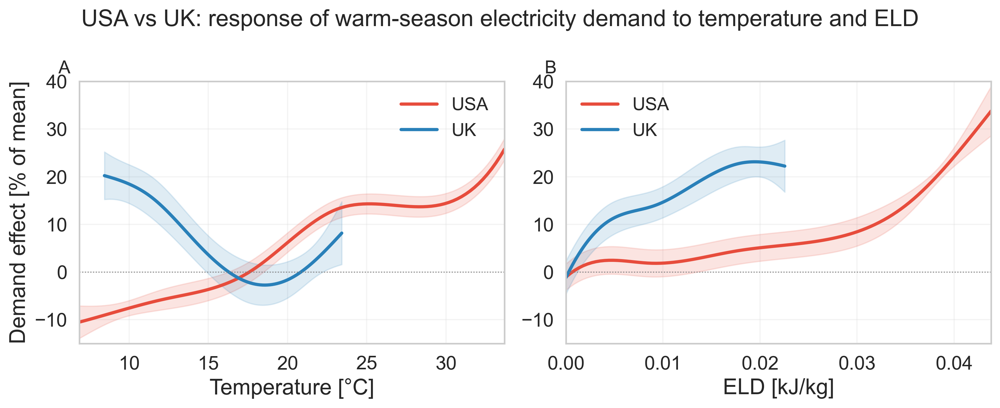

In [58]:
# Response curves: USA vs UK — temperature and ELD side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
FS = 18

panels = [
    (axes[0], 0, 'Temperature [\u00b0C]', 'A'),
    (axes[1], 1, 'ELD [kJ/kg]', 'B'),
]

lines = [
    ('USA', gam_usa, '#e74c3c'),
    ('UK', gam_uk, '#2980b9'),
]

for ax, term_idx, var_label, letter in panels:
    grids = {}
    y_all = []
    for country, gam, color in lines:
        XX = gam.generate_X_grid(term=term_idx)
        pdp, conf = gam.partial_dependence(term=term_idx, X=XX, width=0.95)
        grids[country] = (XX, pdp, conf)
        y_all.append(conf[:, 0] * 100)
        y_all.append(conf[:, 1] * 100)
    y_all = np.concatenate(y_all)
    y_pad = 0.05 * (y_all.max() - y_all.min())
    ylim = (y_all.min() - y_pad, y_all.max() + y_pad)

    x_all = []
    for country, gam, color in lines:
        XX, pdp, conf = grids[country]
        ax.plot(XX[:, term_idx], pdp * 100, color=color, lw=2.5, label=country)
        ax.fill_between(XX[:, term_idx], conf[:, 0] * 100, conf[:, 1] * 100,
                        color=color, alpha=0.15)
        x_all.append(XX[:, term_idx])

    ax.axhline(0, color='gray', lw=0.8, ls=':')
    ax.set_xlim(min(x.min() for x in x_all), max(x.max() for x in x_all))
    ax.set_ylim(ylim)
    ax.set_xlabel(var_label, fontsize=FS - 1)
    if letter == 'A':
        ax.set_ylabel('Demand effect [% of mean]', fontsize=FS - 1)
    ax.text(-0.05, 1.08, letter, transform=ax.transAxes,
            fontsize=14, va='top')
    ax.tick_params(labelsize=FS - 3)
    ax.grid(True, alpha=0.2)
    ax.legend(fontsize=FS - 4)
    ax.set_ylim([-15, 40])

fig.suptitle('USA vs UK: response of warm-season electricity demand to temperature and ELD',
              fontsize=FS)
plt.tight_layout()
plt.savefig(OUT_DIR + 'response_curves_us_vs_uk.png', dpi=300, bbox_inches='tight')
plt.show()


### Figure 7: Daily vs. monthly response curves: USA and UK

Same layout as the figure above (Temperature, ELD), but with the monthly GAM(GDP, Population, avg_temp, avg_ELD) response added for the USA and UK (dashed lines), alongside the daily GAM(T, ELD_density) response (solid lines, as above).

For the temperature panel, daily `T` and monthly `avg_temp` are both in °C, so no rescaling is needed. For the ELD panel, daily `ELD_density` and monthly `avg_ELD` differ by a region-specific, roughly constant factor (grid-cell area in km²) — so each series is normalized by its own mean (`ELD / mean(ELD)`), putting both on a common 'x mean ELD' x-axis where 1.0 = that region's typical ELD.

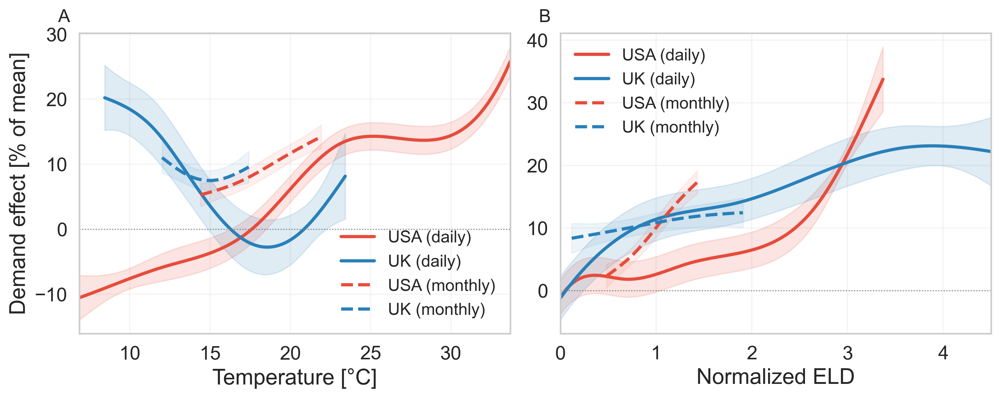

Figure 7 sample sizes:
  USA (daily):   n = 5,725 days (warm season, 8 region(s))
  UK (daily):   n = 732 days (warm season, 1 region(s))
  USA (monthly): n = 96 months (warm season)
  UK (monthly): n = 40 months (warm season)


In [59]:
# Daily vs. monthly response curves: USA and UK
daily_gams = {
    'USA': gam_usa,
    'UK': gam_uk,
}
daily_pooled = {
    'USA': usa_pooled,
    'UK': uk_pooled,
}
monthly_gams = {
    'USA': country_gams.get('United States of America'),
    'UK': country_gams.get('United Kingdom'),
}
colors = {'USA': '#e74c3c', 'UK': '#2980b9'}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
FS = 18

# Panel A: Temperature (daily T vs. monthly avg_temp, both in °C)
ax = axes[0]
x_all, y_all = [], []
curves = [] # (x, pdp, conf, color, ls, label)

for name, gam in daily_gams.items():
    XX = gam.generate_X_grid(term=0)
    pdp, conf = gam.partial_dependence(term=0, X=XX, width=0.95)
    curves.append((XX[:, 0], pdp, conf, colors[name], '-', f'{name} (daily)'))

for name, fit in monthly_gams.items():
    if fit is None:
        continue
    gam, df_n = fit
    XX = gam.generate_X_grid(term=2) # avg_temp
    pdp, conf = gam.partial_dependence(term=2, X=XX, width=0.95)
    curves.append((XX[:, 2], pdp, conf, colors[name], '--', f'{name} (monthly)'))

for x, pdp, conf, color, ls, label in curves:
    x_all.append(x)
    y_all += [conf[:, 0] * 100, conf[:, 1] * 100]

y_all = np.concatenate(y_all)
y_pad = 0.05 * (y_all.max() - y_all.min())
ylim = (y_all.min() - y_pad, y_all.max() + y_pad)

for x, pdp, conf, color, ls, label in curves:
    alpha_fill = 0.15 if ls == '-' else 0.08
    ax.plot(x, pdp * 100, color=color, lw=2.5, ls=ls, label=label)
    ax.fill_between(x, conf[:, 0] * 100, conf[:, 1] * 100, color=color, alpha=alpha_fill)

ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.set_xlim(min(x.min() for x in x_all), max(x.max() for x in x_all))
ax.set_ylim(ylim)
ax.set_xlabel('Temperature [\u00b0C]', fontsize=FS - 1)
ax.set_ylabel('Demand effect [% of mean]', fontsize=FS - 1)
ax.text(-0.05, 1.08, 'A', transform=ax.transAxes, fontsize=14, va='top')
ax.tick_params(labelsize=FS - 3)
ax.grid(True, alpha=0.2)
ax.legend(fontsize=FS - 5)

# Panel B: ELD, each series normalized by its own mean
ax = axes[1]
x_all, y_all = [], []
curves = []

for name, gam in daily_gams.items():
    XX = gam.generate_X_grid(term=1) # ELD_density
    pdp, conf = gam.partial_dependence(term=1, X=XX, width=0.95)
    mean_eld = daily_pooled[name]['ELD_density'].mean()
    curves.append((XX[:, 1] / mean_eld, pdp, conf, colors[name], '-', f'{name} (daily)'))

for name, fit in monthly_gams.items():
    if fit is None:
        continue
    gam, df_n = fit
    XX = gam.generate_X_grid(term=3) # avg_ELD
    pdp, conf = gam.partial_dependence(term=3, X=XX, width=0.95)
    mean_eld = df_n['avg_ELD'].mean()
    curves.append((XX[:, 3] / mean_eld, pdp, conf, colors[name], '--', f'{name} (monthly)'))

for x, pdp, conf, color, ls, label in curves:
    x_all.append(x)
    y_all += [conf[:, 0] * 100, conf[:, 1] * 100]

y_all = np.concatenate(y_all)
y_pad = 0.05 * (y_all.max() - y_all.min())
ylim = (y_all.min() - y_pad, y_all.max() + y_pad)

for x, pdp, conf, color, ls, label in curves:
    alpha_fill = 0.15 if ls == '-' else 0.08
    ax.plot(x, pdp * 100, color=color, lw=2.5, ls=ls, label=label)
    ax.fill_between(x, conf[:, 0] * 100, conf[:, 1] * 100, color=color, alpha=alpha_fill)

ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.set_xlim(min(x.min() for x in x_all), max(x.max() for x in x_all))
ax.set_ylim(ylim)
ax.set_xlabel('Normalized ELD', fontsize=FS - 1)
ax.text(-0.05, 1.08, 'B', transform=ax.transAxes, fontsize=14, va='top')
ax.tick_params(labelsize=FS - 3)
ax.grid(True, alpha=0.2)
ax.legend(fontsize=FS - 5)

# fig.suptitle('USA vs UK: daily (solid) vs. monthly (dashed) response to temperature and normalized ELD',
# fontsize=FS)
plt.tight_layout()
plt.savefig(OUT_DIR + 'response_curves_us_vs_uk_daily_vs_monthly.png', dpi=300, bbox_inches='tight')
plt.show()

# Sample sizes for the figure caption (n = observations used to fit each GAM)
print("Figure 7 sample sizes:")
for name in ['USA', 'UK']:
    n_sectors = daily_pooled[name]['Sector'].nunique()
    print(f"  {name} (daily):   n = {len(daily_pooled[name]):,} days (warm season, {n_sectors} region(s))")
for name, fit in monthly_gams.items():
    if fit is not None:
        print(f"  {name} (monthly): n = {len(fit[1]):,} months (warm season)")

In [60]:
# Quantify the temperature response at 23°C (max temperature in the UK dataset)
T_eval = 23.0

def pdp_at_temp(gam, eld_pooled, T_value):
    """Partial-dependence value of the temperature term at a given T,
    in % of mean demand."""
    X_eval = np.array([[T_value, eld_pooled.mean()]])
    pdp, _ = gam.partial_dependence(term=0, X=X_eval, width=0.95)
    return pdp[0] * 100

uk_at_23 = pdp_at_temp(gam_uk, uk_pooled['ELD_density'], T_eval)
usa_at_23 = pdp_at_temp(gam_usa, usa_pooled['ELD_density'], T_eval)

print(f"UK max temperature in dataset: {uk_pooled['T'].max():.1f}\u00b0C")
print(f"\nThe response of electricity demand to temperature in the UK is weaker than that of the USA;")
print(f"at {T_eval:.0f}\u00b0C, the maximum temperature in the UK dataset:")
print(f"  UK  electricity demand was {uk_at_23:+.1f}% above its mean")
print(f"  USA electricity demand was {usa_at_23:+.1f}% above its mean")
print(f"\nUS temperature response at {T_eval:.0f}\u00b0C is {usa_at_23 / uk_at_23:.1f}x the UK's")


UK max temperature in dataset: 23.4°C

The response of electricity demand to temperature in the UK is weaker than that of the USA;
at 23°C, the maximum temperature in the UK dataset:
  UK  electricity demand was +6.6% above its mean
  USA electricity demand was +13.0% above its mean

US temperature response at 23°C is 2.0x the UK's


## Figure S12: USA subregions: temperature and ELD response curves


Fit 8 subregion GAMs: ['CISO', 'ERCO', 'ISNE', 'MISO', 'NYIS', 'PJM', 'PNM', 'SWPP']


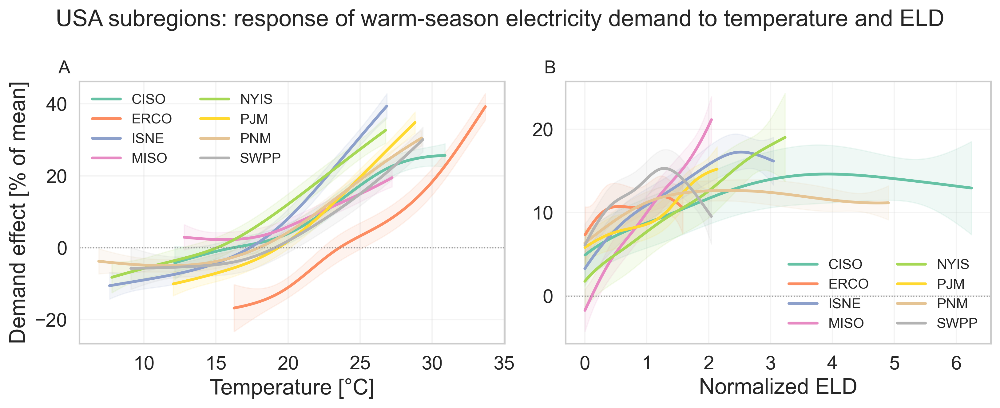

In [61]:
# Response curves: USA subregions -- temperature and ELD, all BAs on one plot
# Colors reuse `ba_palette` (defined above, in Figure S4) so subregions match
# the same colors across both figures.

def fit_single_region_gam(df, target='Demand', t_col='T', eld_col='ELD_density', n_splines=8):
    """Same normalization as fit_region_gam, but fit to a single subregion (no pooling)."""
    df = df.dropna(subset=[target, t_col, eld_col]).copy()
    df[target] = df[target] / df[target].mean()
    X = df[[t_col, eld_col]].values
    y = df[target].values
    gam = LinearGAM(s(0, n_splines=n_splines) + s(1, n_splines=n_splines)).fit(X, y)
    return gam, df

MIN_SUBREGION_N = 30
subregion_gams = {}
for sector, sdf in usa_w.groupby('Sector'):
    if len(sdf.dropna(subset=['Demand', 'T', 'ELD_density'])) < MIN_SUBREGION_N:
        continue
    subregion_gams[sector] = fit_single_region_gam(sdf)

print(f"Fit {len(subregion_gams)} subregion GAMs: {sorted(subregion_gams.keys())}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
FS = 18

# --- Panel A: Temperature ---
ax = axes[0]
grids, y_all = {}, []
for sector, (gam, df_n) in subregion_gams.items():
    XX = gam.generate_X_grid(term=0)
    pdp, conf = gam.partial_dependence(term=0, X=XX, width=0.95)
    grids[sector] = (XX[:, 0], pdp, conf)
    y_all += [conf[:, 0] * 100, conf[:, 1] * 100]
y_all = np.concatenate(y_all)
pad = 0.05 * (y_all.max() - y_all.min())
ylim = (y_all.min() - pad, y_all.max() + pad)

for sector, (x, pdp, conf) in grids.items():
    color = ba_palette[sector]
    ax.plot(x, pdp * 100, color=color, lw=2.2, label=sector)
    ax.fill_between(x, conf[:, 0] * 100, conf[:, 1] * 100, color=color, alpha=0.1)

ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.set_ylim(ylim)
ax.set_xlabel('Temperature [\u00b0C]', fontsize=FS - 1)
ax.set_ylabel('Demand effect [% of mean]', fontsize=FS - 1)
ax.text(-0.05, 1.08, 'A', transform=ax.transAxes, fontsize=14, va='top')
ax.tick_params(labelsize=FS - 3)
ax.grid(True, alpha=0.2)
ax.legend(fontsize=FS - 7, ncol=2)

# --- Panel B: ELD, normalized by each subregion's own mean ---
ax = axes[1]
grids, y_all = {}, []
for sector, (gam, df_n) in subregion_gams.items():
    XX = gam.generate_X_grid(term=1)
    pdp, conf = gam.partial_dependence(term=1, X=XX, width=0.95)
    mean_eld = df_n['ELD_density'].mean()
    grids[sector] = (XX[:, 1] / mean_eld, pdp, conf)
    y_all += [conf[:, 0] * 100, conf[:, 1] * 100]
y_all = np.concatenate(y_all)
pad = 0.05 * (y_all.max() - y_all.min())
ylim = (y_all.min() - pad, y_all.max() + pad)

for sector, (x, pdp, conf) in grids.items():
    color = ba_palette[sector]
    ax.plot(x, pdp * 100, color=color, lw=2.2, label=sector)
    ax.fill_between(x, conf[:, 0] * 100, conf[:, 1] * 100, color=color, alpha=0.1)

ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.set_ylim(ylim)
ax.set_xlabel('Normalized ELD', fontsize=FS - 1)
ax.text(-0.05, 1.08, 'B', transform=ax.transAxes, fontsize=14, va='top')
ax.tick_params(labelsize=FS - 3)
ax.grid(True, alpha=0.2)
ax.legend(fontsize=FS - 7, ncol=2)

fig.suptitle('USA subregions: response of warm-season electricity demand to temperature and ELD',
              fontsize=FS)
plt.tight_layout()
plt.savefig(OUT_DIR + 'supplementary/response_curves_us_subregions.png', dpi=300, bbox_inches='tight')
plt.show()


### USA/UK daily + monthly response curves, with the USA line replaced by the subregion ensemble average

Same figure and layout as “Daily vs. monthly response curves: USA and UK” above (same colours, UK daily/monthly and USA monthly all unchanged), but the “USA (daily)” line is now the unweighted mean ± 1.96 SE across the individual subregion GAMs (`subregion_gams`, computed the same way as in the ensemble-average figure above) instead of the single pooled `gam_usa` fit. The subregion spaghetti lines are kept in the background for context.

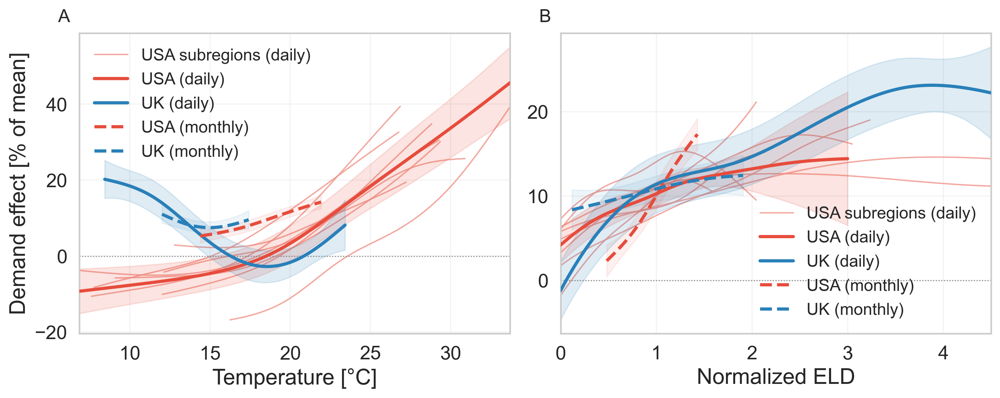

Figure 7 sample sizes:
  USA (daily):   n = 5,725 days (warm season, 8 region(s))
  UK (daily):   n = 732 days (warm season, 1 region(s))
  USA (monthly): n = 96 months (warm season)
  UK (monthly): n = 40 months (warm season)
  USA subregion CISO (daily): n = 675 days
  USA subregion ERCO (daily): n = 730 days
  USA subregion ISNE (daily): n = 726 days
  USA subregion MISO (daily): n = 721 days
  USA subregion NYIS (daily): n = 730 days
  USA subregion PJM (daily): n = 729 days
  USA subregion PNM (daily): n = 702 days
  USA subregion SWPP (daily): n = 712 days


In [62]:
# Daily USA/UK response curves (as in the figure above), but with the "USA
# (daily)" line replaced by the unweighted subregion ensemble mean ± 1.96 SE
# (from `subregion_gams`, fit in the "USA subregions" section above) instead of
# the pooled `gam_usa` fit. UK daily/monthly and USA monthly are unchanged.
# Subregion spaghetti lines are kept in the background for context.
SUBREGION_COLOR = '#f1948a'  # light red for the background subregion lines

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
FS = 18

# Panel A: Temperature (daily T vs. monthly avg_temp, both in °C)
ax = axes[0]
x_all, y_all = [], []
curves = []  # (x, pdp, conf, color, ls, label)

# USA (daily) -- subregion ensemble mean ± 1.96 SE, replacing the pooled USA GAM
T_grid = gam_usa.generate_X_grid(term=0)[:, 0]
region_pdps_temp = []
for sector, (gam, df_n) in subregion_gams.items():
    mean_eld = df_n['ELD_density'].mean()
    X_eval = np.column_stack([T_grid, np.full_like(T_grid, mean_eld)])
    pdp, _ = gam.partial_dependence(term=0, X=X_eval, width=0.95)
    region_pdps_temp.append(pdp)
region_pdps_temp = np.array(region_pdps_temp)
ens_mean_temp = region_pdps_temp.mean(axis=0)
ens_se_temp = region_pdps_temp.std(axis=0, ddof=1) / np.sqrt(region_pdps_temp.shape[0])
ens_conf_temp = np.column_stack([ens_mean_temp - 1.96 * ens_se_temp, ens_mean_temp + 1.96 * ens_se_temp])
curves.append((T_grid, ens_mean_temp, ens_conf_temp, colors['USA'], '-', 'USA (daily)'))

# UK (daily) -- unchanged
XX = gam_uk.generate_X_grid(term=0)
pdp, conf = gam_uk.partial_dependence(term=0, X=XX, width=0.95)
curves.append((XX[:, 0], pdp, conf, colors['UK'], '-', 'UK (daily)'))

# USA / UK (monthly) -- unchanged
for name, fit in monthly_gams.items():
    if fit is None:
        continue
    gam, df_n = fit
    XX = gam.generate_X_grid(term=2)  # avg_temp
    pdp, conf = gam.partial_dependence(term=2, X=XX, width=0.95)
    curves.append((XX[:, 2], pdp, conf, colors[name], '--', f'{name} (monthly)'))

# USA subregion spaghetti, for context
subregion_curves = []
for sector, (gam, df_n) in subregion_gams.items():
    XX = gam.generate_X_grid(term=0)
    pdp, conf = gam.partial_dependence(term=0, X=XX, width=0.95)
    subregion_curves.append((XX[:, 0], pdp))

for x, pdp, conf, color, ls, label in curves:
    x_all.append(x)
    y_all += [conf[:, 0] * 100, conf[:, 1] * 100]
for x, pdp in subregion_curves:
    y_all.append(pdp * 100)

y_all = np.concatenate(y_all)
y_pad = 0.05 * (y_all.max() - y_all.min())
ylim = (y_all.min() - y_pad, y_all.max() + y_pad)

for i, (x, pdp) in enumerate(subregion_curves):
    ax.plot(x, pdp * 100, color=SUBREGION_COLOR, lw=1.1, alpha=0.8, zorder=1,
            label='USA subregions (daily)' if i == 0 else None)

for x, pdp, conf, color, ls, label in curves:
    alpha_fill = 0.15 if ls == '-' else 0.08
    ax.plot(x, pdp * 100, color=color, lw=2.5, ls=ls, label=label, zorder=3)
    ax.fill_between(x, conf[:, 0] * 100, conf[:, 1] * 100, color=color, alpha=alpha_fill, zorder=2)

ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.set_xlim(min(x.min() for x in x_all), max(x.max() for x in x_all))
ax.set_ylim(ylim)
ax.set_xlabel('Temperature [°C]', fontsize=FS - 1)
ax.set_ylabel('Demand effect [% of mean]', fontsize=FS - 1)
ax.text(-0.05, 1.08, 'A', transform=ax.transAxes, fontsize=14, va='top')
ax.tick_params(labelsize=FS - 3)
ax.grid(True, alpha=0.2)
ax.legend(fontsize=FS - 5)

# Panel B: ELD, each series normalized by its own mean
ax = axes[1]
x_all, y_all = [], []
curves = []

# USA (daily) -- subregion ensemble mean ± 1.96 SE, x-axis in multiples of each
# region's own mean ELD (converted back to raw units before evaluating its GAM)
norm_grid = np.linspace(0, 3, 200)
region_pdps_eld = []
for sector, (gam, df_n) in subregion_gams.items():
    mean_t = df_n['T'].mean()
    mean_eld = df_n['ELD_density'].mean()
    raw_eld_grid = norm_grid * mean_eld
    X_eval = np.column_stack([np.full_like(raw_eld_grid, mean_t), raw_eld_grid])
    pdp, _ = gam.partial_dependence(term=1, X=X_eval, width=0.95)
    region_pdps_eld.append(pdp)
region_pdps_eld = np.array(region_pdps_eld)
ens_mean_eld = region_pdps_eld.mean(axis=0)
ens_se_eld = region_pdps_eld.std(axis=0, ddof=1) / np.sqrt(region_pdps_eld.shape[0])
ens_conf_eld = np.column_stack([ens_mean_eld - 1.96 * ens_se_eld, ens_mean_eld + 1.96 * ens_se_eld])
curves.append((norm_grid, ens_mean_eld, ens_conf_eld, colors['USA'], '-', 'USA (daily)'))

# UK (daily) -- unchanged
XX = gam_uk.generate_X_grid(term=1)  # ELD_density
pdp, conf = gam_uk.partial_dependence(term=1, X=XX, width=0.95)
mean_eld_uk = daily_pooled['UK']['ELD_density'].mean()
curves.append((XX[:, 1] / mean_eld_uk, pdp, conf, colors['UK'], '-', 'UK (daily)'))

# USA / UK (monthly) -- unchanged
for name, fit in monthly_gams.items():
    if fit is None:
        continue
    gam, df_n = fit
    XX = gam.generate_X_grid(term=3)  # avg_ELD
    pdp, conf = gam.partial_dependence(term=3, X=XX, width=0.95)
    mean_eld = df_n['avg_ELD'].mean()
    curves.append((XX[:, 3] / mean_eld, pdp, conf, colors[name], '--', f'{name} (monthly)'))

# USA subregion spaghetti, for context
subregion_curves = []
for sector, (gam, df_n) in subregion_gams.items():
    XX = gam.generate_X_grid(term=1)
    pdp, conf = gam.partial_dependence(term=1, X=XX, width=0.95)
    mean_eld = df_n['ELD_density'].mean()
    subregion_curves.append((XX[:, 1] / mean_eld, pdp))

for x, pdp, conf, color, ls, label in curves:
    x_all.append(x)
    y_all += [conf[:, 0] * 100, conf[:, 1] * 100]
for x, pdp in subregion_curves:
    y_all.append(pdp * 100)

y_all = np.concatenate(y_all)
y_pad = 0.05 * (y_all.max() - y_all.min())
ylim = (y_all.min() - y_pad, y_all.max() + y_pad)

for i, (x, pdp) in enumerate(subregion_curves):
    ax.plot(x, pdp * 100, color=SUBREGION_COLOR, lw=1.1, alpha=0.8, zorder=1,
            label='USA subregions (daily)' if i == 0 else None)

for x, pdp, conf, color, ls, label in curves:
    alpha_fill = 0.15 if ls == '-' else 0.08
    ax.plot(x, pdp * 100, color=color, lw=2.5, ls=ls, label=label, zorder=3)
    ax.fill_between(x, conf[:, 0] * 100, conf[:, 1] * 100, color=color, alpha=alpha_fill, zorder=2)

ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.set_xlim(min(x.min() for x in x_all), max(x.max() for x in x_all))
ax.set_ylim(ylim)
ax.set_xlabel('Normalized ELD', fontsize=FS - 1)
ax.text(-0.05, 1.08, 'B', transform=ax.transAxes, fontsize=14, va='top')
ax.tick_params(labelsize=FS - 3)
ax.grid(True, alpha=0.2)
ax.legend(fontsize=FS - 5)

plt.tight_layout()
plt.savefig(OUT_DIR + 'response_curves_us_vs_uk_daily_vs_monthly_usa_ensemble.png', dpi=300, bbox_inches='tight')
plt.show()

# Sample sizes for the figure caption (n = observations used to fit each GAM)
print("Figure 7 sample sizes:")
for name in ['USA', 'UK']:
    n_sectors = daily_pooled[name]['Sector'].nunique()
    print(f"  {name} (daily):   n = {len(daily_pooled[name]):,} days (warm season, {n_sectors} region(s))")
for name, fit in monthly_gams.items():
    if fit is not None:
        print(f"  {name} (monthly): n = {len(fit[1]):,} months (warm season)")
for sector, (gam, df_n) in subregion_gams.items():
    print(f"  USA subregion {sector} (daily): n = {len(df_n):,} days")

# Other Supplementary Figures

In [63]:
# Shared setup for supplementary CV-robustness figures
from sklearn.model_selection import LeaveOneGroupOut

MIN_YEARS = 4


class TemporalHoldout:
    def split(self, X, y=None, groups=None):
        n = len(X)
        split = max(int(n * 0.8), MIN_SAMPLES)
        if split >= n - 1:
            return
        yield np.arange(split), np.arange(split, n)


def run_ols_cv(wdf, cv_splitter, label='', use_year_groups=False,
               feat_base=None, feat_cdd=None, feat_eld=None, feat_cdd_eld=None):
    """
    Per-country OLS. Feature sets default to the standard OLS_* globals but
    can be overridden.
    """
    fb = feat_base or OLS_BASE
    fc = feat_cdd or OLS_CDD
    fe = feat_eld or OLS_ELD
    fce = feat_cdd_eld or OLS_CDD_ELD
    needed = list(set(fce + [TARGET]))

    countries = [c for c, g in wdf.groupby('Country')
                 if len(g.dropna(subset=needed)) >= MIN_SAMPLES]
    results = []

    for country_name in countries:
        df = (wdf[wdf['Country'] == country_name]
              .sort_values('Date')
              [needed + ['Date']]
              .dropna())
        if len(df) < MIN_SAMPLES:
            continue

        years = df['Date'].dt.year.values
        n_yrs = len(np.unique(years))
        if use_year_groups and n_yrs < MIN_YEARS:
            continue

        y = df[TARGET].values
        Xs = {'base': df[fb].values, 'cdd': df[fc].values,
              'eld': df[fe].values, 'cdd_eld': df[fce].values}
        groups = years if use_year_groups else None

        r2 = {k: [] for k in Xs}
        for train_idx, test_idx in cv_splitter.split(Xs['base'], groups=groups):
            if len(test_idx) < 2:
                continue
            for key, X in Xs.items():
                m = LinearRegression().fit(X[train_idx], y[train_idx])
                r2[key].append(r2_score(y[test_idx], m.predict(X[test_idx])))

        if not r2['base']:
            continue

        r = {k: np.array(v) for k, v in r2.items()}
        avg_temp, _avg_eld, gdp_capita, AC = _country_meta(wdf, country_name)

        results.append({
            'Country': country_name,
            'n_years': n_yrs,
            'avg_R2_base': r['base'].mean(),
            'avg_R2_cdd': r['cdd'].mean(),
            'avg_R2_eld': r['eld'].mean(),
            'avg_R2_cdd_eld': r['cdd_eld'].mean(),
            'delta_R2_cdd': r['cdd'].mean() - r['base'].mean(),
            'delta_R2_eld': r['eld'].mean() - r['base'].mean(),
            'delta_R2_eld_on_cdd': r['cdd_eld'].mean() - r['cdd'].mean(),
            'pval_cdd': _safe_ttest(r['cdd'], r['base']),
            'pval_eld': _safe_ttest(r['eld'], r['base']),
            'pval_eld_on_cdd': _safe_ttest(r['cdd_eld'], r['cdd']),
            'avg_temp': avg_temp,
            'gdp_capita': gdp_capita,
            'AC': AC,
        })

    print(f"[{label}] {len(results)} countries")
    return pd.DataFrame(results)


ss100 = ShuffleSplit(n_splits=100, test_size=0.2, random_state=42)
res_ols = run_ols_cv(wdf, ss100, label='OLS standard CDD')

[OLS standard CDD] 85 countries


## Figure S13: Time-aware cross-validation splits

In [64]:
CLIP = -5

# 80/20 temporal holdout
res_diag_temp80 = run_ols_cv(wdf, TemporalHoldout(), label='OLS 80/20 temporal')

# Leave-one-year-out
logo = LeaveOneGroupOut()
res_ols_loyo = run_ols_cv(wdf, logo, label='OLS LOYO CV', use_year_groups=True)

# Test-set sizes
avg_warm = (wdf.dropna(subset=['demand_gwh'])
            .groupby(['Country', 'Year'])['demand_gwh'].count().reset_index()
            .groupby('Country')['demand_gwh'].mean()
            .rename('n_test_months').reset_index())

temp80_rows = []
for country, grp in wdf.dropna(subset=['demand_gwh']).groupby('Country'):
    grp = grp.sort_values('Date')
    n = len(grp)
    split = max(int(n * 0.8), MIN_SAMPLES)
    if split < n - 1:
        temp80_rows.append({'Country': country, 'n_test_months': n - split})
temp80_size = pd.DataFrame(temp80_rows)

[OLS 80/20 temporal] 84 countries


[OLS LOYO CV] 83 countries


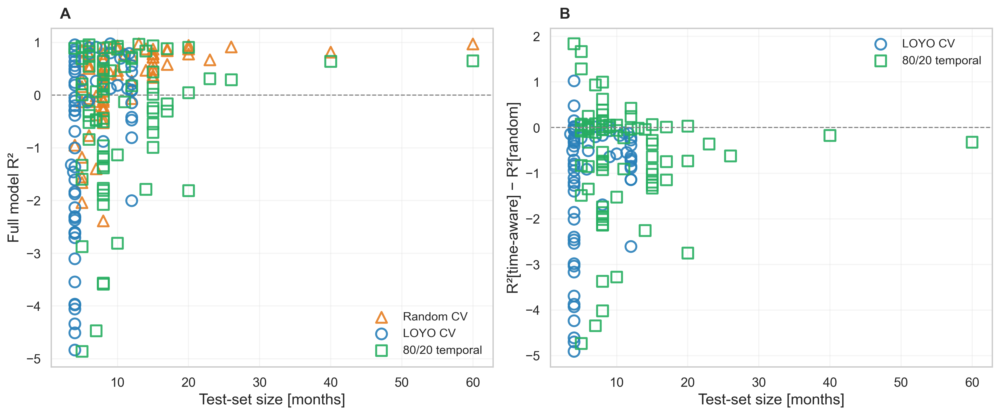

In [65]:
df_loyo = (res_ols_loyo[['Country', 'avg_R2_cdd_eld']]
           .rename(columns={'avg_R2_cdd_eld': 'R2_loyo'})
           .merge(res_ols[['Country', 'avg_R2_cdd_eld']]
                  .rename(columns={'avg_R2_cdd_eld': 'R2_rand_loyo'}), on='Country')
           .merge(avg_warm, on='Country').dropna())
df_loyo = df_loyo[df_loyo['R2_loyo'] > CLIP].copy()
df_loyo['diff'] = df_loyo['R2_loyo'] - df_loyo['R2_rand_loyo']

df_temp80 = (res_diag_temp80[['Country', 'avg_R2_cdd_eld']]
             .rename(columns={'avg_R2_cdd_eld': 'R2_temp80'})
             .merge(res_ols[['Country', 'avg_R2_cdd_eld']]
                    .rename(columns={'avg_R2_cdd_eld': 'R2_rand'}), on='Country')
             .merge(temp80_size, on='Country').dropna())
df_temp80 = df_temp80[df_temp80['R2_temp80'] > CLIP].copy()
df_temp80['diff'] = df_temp80['R2_temp80'] - df_temp80['R2_rand']

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
FS = 14

# Left: absolute R²
ax = axes[0]
ax.scatter(df_temp80['n_test_months'], df_temp80['R2_rand'],
           marker='^', s=100, facecolors='none', edgecolors='#e67e22',
           linewidths=1.8, label='Random CV', zorder=3, alpha=0.9)
ax.scatter(df_loyo['n_test_months'], df_loyo['R2_loyo'],
           marker='o', s=100, facecolors='none', edgecolors='#2980b9',
           linewidths=1.8, label='LOYO CV', zorder=4, alpha=0.9)
ax.scatter(df_temp80['n_test_months'], df_temp80['R2_temp80'],
           marker='s', s=100, facecolors='none', edgecolors='#27ae60',
           linewidths=1.8, label='80/20 temporal', zorder=4, alpha=0.9)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('Test-set size [months]', fontsize=FS)
ax.set_ylabel('Full model R²', fontsize=FS)
ax.tick_params(labelsize=FS - 2)
ax.legend(fontsize=FS - 3)
ax.text(0.02, 1.02, 'A', transform=ax.transAxes, fontsize=14, fontweight='bold', va='bottom')
ax.grid(True)


# Right: difference (time-aware − random)
ax = axes[1]
ax.scatter(df_loyo['n_test_months'], df_loyo['diff'],
           marker='o', s=100, facecolors='none', edgecolors='#2980b9',
           linewidths=1.8, label='LOYO CV', alpha=0.9)
ax.scatter(df_temp80['n_test_months'], df_temp80['diff'],
           marker='s', s=100, facecolors='none', edgecolors='#27ae60',
           linewidths=1.8, label='80/20 temporal', alpha=0.9)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('Test-set size [months]', fontsize=FS)
ax.set_ylabel('R²[time-aware] − R²[random]', fontsize=FS)
ax.tick_params(labelsize=FS - 2)
ax.legend(fontsize=FS - 3)
ax.text(0.02, 1.02, 'B', transform=ax.transAxes, fontsize=14, fontweight='bold', va='bottom')
ax.grid(True)

plt.tight_layout()
plt.savefig(OUT_DIR + 'supplementary/diagnostic_timeaware_combined.png', dpi=300, bbox_inches='tight')
plt.show()

## Figure S6: 10+ year record-length sensitivity

In [66]:
# Restrict to countries with 10+ years of record
wdf['record_length'] = wdf.groupby('Country')['Year'].transform(lambda x: x.max() - x.min() + 1)
wdf_10 = wdf[wdf['record_length'] >= 10]
res_ols10 = run_ols_cv(wdf_10, ss100, label='OLS (>=10 years)')

[OLS (>=10 years)] 34 countries


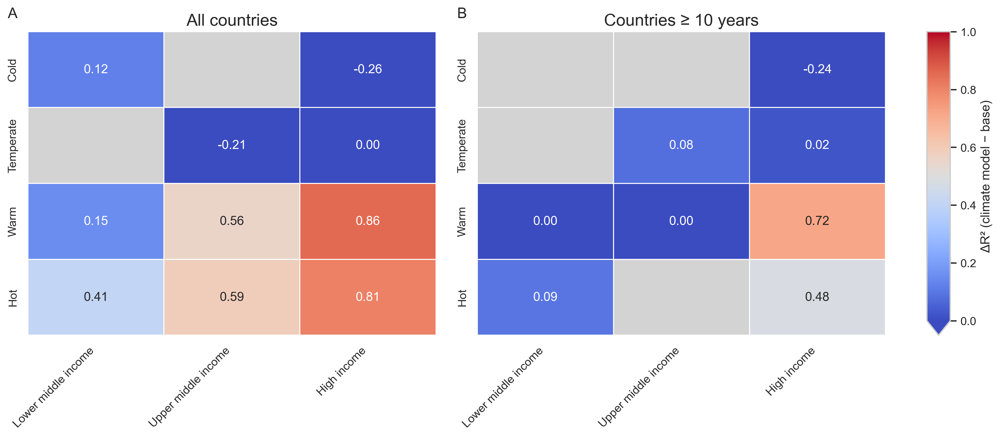

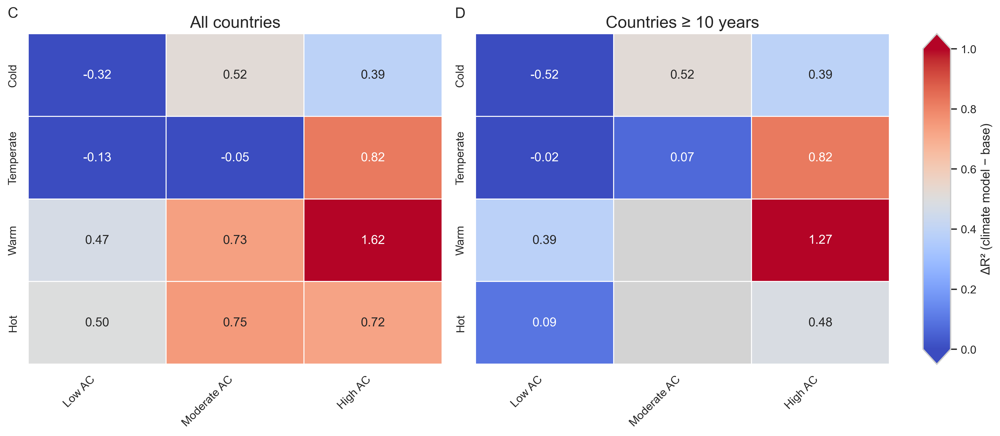

In [67]:
# ΔR² heatmaps: all countries vs. 10+ year subset
# Create views with a unified column name expected by the heatmap functions
def _ols_view(res):
    return res[['Country', 'delta_R2_cdd', 'avg_temp', 'AC']].copy()

heatmap_panel(
    [_ols_view(res_ols), _ols_view(res_ols10)],
    ['All countries', 'Countries ≥ 10 years'],
    df_income, col='delta_R2_cdd',
    cbar_label='ΔR² (climate model − base)',
    filename='supplementary/heatmap_income_temp_10yrs.png', vmin=0, vmax=1,
)

heatmap_ac_panel(
    [_ols_view(res_ols), _ols_view(res_ols10)],
    ['All countries', 'Countries ≥ 10 years'],
    col='delta_R2_cdd',
    cbar_label='ΔR² (climate model − base)',
    filename='supplementary/heatmap_AC_temp_10yrs.png', vmin=0, vmax=1,
)